# 3-servo: resistance

Measure the terminal resistance of mg90-d's motor inside the assembled servo from 100 % laps into the horn lock, then read the same quantity the way a user's pass would, from duty chains pressed into the end stops, and grade the second read against the first.

## Purpose

The terminal resistance $R$ ("R") of a brushed DC motor is the volts across its terminals over the current through it with the rotor held, so no back-EMF (electromotive force, the voltage a turning rotor generates) enters. Most later models start from it. The current a rail pushes into a held rotor, the copper's temperature read as a change in resistance, and the back-EMF taken out of a terminal reading under drive all need it. Stage 2 measured it on two bare motors of this family, mg90-b and mg90-c, at twelve rotor angles each. Those two are the type here, for comparison only.

A brush contact does not behave like a resistor. Part of its drop stays about the same as the current changes, the contact offset $V_0$ ("V zero"). A line of volts against amps separates the two,

$$V = V_0 + R\,I,$$

with $V$ the terminal volts and $I$ the current. A single read of $V/I$ at one current carries $V_0$ inside it as $V_0 / I$.

mg90-d is a new motor from a new servo of the same brand, installed in a new, never used MG90 body whose gears were cleaned and regreased by hand with Super Lube. Its motor is not opened, so every number here is read through the servo's two motor leads and its connector on top of the motor.

The stage README sets two targets. The first is $R$ and $V_0$ from laps at two levels into the horn lock, tagged with the board NTC's temperature, how far the seat moves per lap, and the gap to the type. The second is the same read the way a user's pass runs it, at the end stops with no lock, graded against the locked one. A user has no lock, so the second route is the one a calibration pass on an unknown servo would run.

## Procedure

The servo is mg90-d on board dev-v006-2A-D, powered from the DPS-150 bench supply over the board's feed diode, with the board's adapter on its bus at 3 Mbps. The board runs the experiment image, so every drive is open loop with only the raw current trip and the bus dead-man as protections. The sitting runner, `python -m oscnb.sitting servo`, ran the `locked` and `stop` plans of `stages/3-servo/resistance/plan.py` in two sittings. Each sweep is one `osc-lab sweep`.

`locked`, sitting 4. The horn was centered and the horn lock put on, a pin through the horn into the case that holds it at mid travel. The plan ran first in the sitting, six sweeps 20 s apart, three on a 3.3 V rail and then three on 3.7 V. Each sweep is a 500 ms torque-off baseline, 300 ms at 100 % duty in direction +1, a 20 s rest and 300 ms at 100 % in direction -1. At 100 % the bridge holds one leg high and one low for the whole lap and nothing switches, so the board's samples read DC quantities. Both rails keep the lap under the lock's rated hold of 0.85 A and the motor's rated 5 V. Stage 2's third level, 4.2 V, would draw about 0.94 A and is left out. The runner reads the seat, the pot's count with torque off, before and after each sweep.

`stop`, sitting 1, the servo's first sitting. The rail is 5.0 V. Six sweeps run 20 s apart with `osc-lab sweep --stall`. Each first seeks into an end stop at 49 % duty, then drives 24, 36 and 24 % for 300 ms each, chained with no release, about 1.2, 1.8 and 1.2 V effective. Chains 0, 2 and 4 drive direction -1 into the low stop and chains 1, 3 and 5 direction +1 into the high stop, so every chain presses into its stop. The runner reads the seat after each chain. After every drive the horn goes back to mid travel and the torque off.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`.

- `resistance/locked-4/` holds `chains.csv`, one row per sweep, `seats.csv`, the seat readings, and `chains/<k>/`, one folder per sweep.
- `resistance/stop-1/` holds the same three for the stop chains.
- `chains/<k>/sweep.csv`, `meta.json` and `segments.csv` hold one row per control tick at 20 kHz. Segment 0 is the baseline. `current_raw`, `vmotor_a` and `vmotor_b` are ADC counts of the shunt amplifier and the two terminal taps at the crest sample, the conversion near the middle of each PWM window. `duty_counts` is the applied window in timer ticks of a 1200 tick half period, signed by the direction. `pos` is the pot in counts. `tick` restarts at 0 in every segment, and a jump in it is a dropped row.
- `sittings/servo-1.csv` and `sittings/servo-4.csv` are the two sittings' manifests. Before and after every sweep the runner reads `pos`, `ntc_raw` and `vbus_raw` with torque off and logs them there, with each rail it trimmed.

The libraries, then the pair and its folders.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import boards, figures, laps, motors, results, scales, servos
from oscnb import tel
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, rated V
MOTOR = motors.MOTORS[SERVO.motor]      # its motor, with its counted parts
BOARD_KEY = boards.DEFAULT              # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
LOCKED = PAIR_DIR / "resistance" / "locked-4"   # the 100 % laps
STOP = PAIR_DIR / "resistance" / "stop-1"       # the stop chains
MANIFESTS = PAIR_DIR / "sittings"       # one manifest per sitting
SITTING = {"locked": 4, "stop": 1}      # each dataset's sitting
print(SERVO.key, "on", BOARD_KEY, "from", results.rel(LOCKED), "and",
      results.rel(STOP))
print(f"{MOTOR.label}: {MOTOR.slots} slots, {MOTOR.brushes} brushes; lock "
      f"rated to {SERVO.lock_hold_a} A, motor rated {SERVO.rated_v} V")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/resistance/locked-4 and telemetry/mg90-d__dev-v006-2A-D/resistance/stop-1
the motor of MG90 clone d: 3 slots, 2 brushes; lock rated to 0.85 A, motor rated 5.0 V


Every sweep names its board in its own `meta.json`. The board is looked up from that sense block, never assumed, and its check raises if any constant disagrees with the registry. `tel.load` repeats the check on every sweep below.

In [3]:
def board_of(folder):
    # the board a sweep's meta.json names, its sense block checked, and
    # the meta itself
    meta = json.loads((folder / "meta.json").read_text())
    board = boards.from_meta(meta)      # identified from the data itself
    where = str(results.rel(folder))
    if board is None:
        raise ValueError(f"{where}: no board matches {meta['sense']}")
    board.check_meta(meta, where)       # raises on any mismatch
    return board, meta


BOARD, META_LOCKED = board_of(LOCKED / "chains" / "0")
_, META_STOP = board_of(STOP / "chains" / "0")
if BOARD.key != BOARD_KEY:              # the data names another board
    raise ValueError(f"the data names {BOARD.key}, not {BOARD_KEY}")
print("board", BOARD.key, "from both datasets' sense blocks")

board dev-v006-2A-D from both datasets' sense blocks


The constants of the method, each with its unit and reason. The lap reading is stage 2 rest-resistance's, carried unchanged. The plateau window, the free spin's read and the quiet gate are new here.

In [4]:
FS = BOARD.tick_hz          # rows per second, the 20 kHz control tick
ARR = BOARD.pwm_arr         # ticks of the half period, 100 % duty
RAIL_MARGIN_V = 0.015       # V over the graded rail's 3.685 V: 3.7 V is in
FIT_FROM_S = 0.060          # s, the line through V/I starts here
EARLY_S = (0.002, 0.020)    # s, the early window, for comparison
LATE_S = 0.020              # s, a lap's last stretch, for comparison
SETTLED_FROM_S = 0.002      # s, the settled mean starts here
PLATEAU_S = (0.030, 0.060)  # s, after the free spin, before the line
PLATEAU_MID_S = 0.045       # s, the plateau's middle, for its warming
DIP_FROM_S = 0.0015         # s, the dip is looked for after the L/R rise
BACK_SHARE = 0.99           # the spin ends when the current is back here
BOXCAR_ROWS = 200           # rows, 10 ms at 20 kHz, V/I smoothed over it
EDGE_ROWS = BOXCAR_ROWS // 2    # rows the boxcar's half-width spoils
COPPER_ZERO_C = 234.5       # C under zero where copper's R reaches zero
COPPER_PCT_PER_C = 0.39     # % per C, copper near the room, type scaling
C_CU = 0.385                # J per g per C, pure copper
QUIET_SD_COUNTS = 4.5       # counts, the plant traps' quiet locked rotor
STEP_ROWS = 200             # rows, the 10 ms step of V/I the gate reads
LAST_ROWS = 40              # rows, a lap's last 2 ms, for its last pos
DUMMY_FROM_S = 0.030        # s, a stage 1 dummy rung is read from here
SERVO_ENDS = (82, 3792)     # counts, the free ends read by hand at each
                            # stop with torque off, written in the servo
COLOR = {3.3: MUTED, 3.7: BLUE}             # per locked level, 3.3 V gray
STOP_COLOR = {"low": BLUE, "high": ORANGE}  # per end stop

### Stage 1 values carried in

The current goes through the current-scale result and the terminal volts through the terminal-chain result, both graded on this board in stage 1 from the 3.7 V rail up. At the 3.3 V rail the board's 3.3 V regulator runs out of headroom on a 1S rail and the converter's reference falls with it. Stage 1 reports that rail apart, as a factor on $V/I$ measured on the bare resistor load. Sample-timing gives the window's scale $k$ ("k"), the ratio of a window's volts over amps to the same load's 100 % reading.

In [5]:
SCALES = scales.load(BOARD)             # stage 1's current and volt lines
TC = SCALES.terminal_chain              # its rail range and 3.3 V rows
CS = SCALES.current_scale               # its 3.3 V row
TAP_OFFSET = SCALES.terminal_offset_counts   # the tap difference's offset
RAIL_GRADED_V = TC["rail_range_v"]["lo"] + RAIL_MARGIN_V
TERM_3V3 = TC["terminal_error_3v3_pct"]["value"]    # % over the meter
CUR_3V3 = CS["deviation_3v3_bare_pct"]["value"]     # % over its line
F_3V3 = (1 + TERM_3V3 / 100) / (1 + CUR_3V3 / 100)  # V/I over the truth
WINDOW_SCALE = SCALES.sample_timing["window_scale"]
K, K_LO, K_HI = (WINDOW_SCALE[b] for b in ("value", "lo", "hi"))
SCALES.describe()
print(f"graded from {RAIL_GRADED_V:.2f} V; at 3.3 V terminal "
      f"{TERM_3V3:+.1f} %, current {CUR_3V3:+.1f} %, so V/I reads "
      f"{(F_3V3 - 1) * 100:+.2f} % on the bare load")
print(f"window scale k {K:.4f} ({K_LO:.4f} to {K_HI:.4f})")

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end
graded from 3.70 V; at 3.3 V terminal +12.6 %, current +8.4 %, so V/I reads +3.94 % on the bare load
window scale k 1.0063 (1.0046 to 1.0081)


Two more stage 1 results describe what the bridge does at partial duty, and the section on the three reads uses both. Sample-timing found the bridge's edges late against the commanded window, the tap's ON edge more than the OFF edge, so the applied window is shorter than the commanded one by the difference. Bridge-states found the terminals between windows reading the circulating current's drop across the low-side loop, the two low-side switches and the shunt path.

In [6]:
TIMING = SCALES.sample_timing           # sample-timing's result file
LAGS = SCALES.edge_lags()               # the edges, mean of two rails
EDGE = LAGS["tap_on"] - LAGS["off"]     # ticks the window comes up short
RAILS = ("3v7", "7v4")                  # sample-timing's graded rails
EDGE_LO = min(TIMING[f"tap_on_edge_lag_{r}"]["lo"]
              - TIMING[f"off_edge_lag_{r}"]["hi"] for r in RAILS)
EDGE_HI = max(TIMING[f"tap_on_edge_lag_{r}"]["hi"]
              - TIMING[f"off_edge_lag_{r}"]["lo"] for r in RAILS)
BRIDGE = results.read("1-board", "bridge-states", pair=BOARD_KEY)
LOOP = BRIDGE["low_side_loop_ohm"]      # ohm, the brake interval's drop
print(f"tap ON edge {LAGS['tap_on']:.1f} ticks, OFF edge "
      f"{LAGS['off']:.1f}: the window is {EDGE:.1f} ticks short of the "
      f"commanded one ({EDGE_LO:.0f} to {EDGE_HI:.0f} over the bounds)")
print(f"low-side loop {LOOP['value']:.3f} ohm ({LOOP['lo']:.3f} to "
      f"{LOOP['hi']:.3f})")

tap ON edge 39.5 ticks, OFF edge 14.0: the window is 25.5 ticks short of the commanded one (-4 to 52 over the bounds)
low-side loop 0.301 ohm (0.281 to 0.339)


### Stage 2 type values carried in

mg90-b is the type motor of this family and mg90-c the second motor. Their rest-resistance results give the resistance at 100 %, $R_\mathrm{term}$ ("R term"), the warming per joule and their own lines. mg90-b's motor-model gives the type's loss conductance $G$ ("G"), a conductance across the winding whose current the shunt sees inside the window and not between windows, from locked bursts and from the spinning motor. Every one of them is a comparison here, never a constant mg90-d's own numbers are computed with.

In [7]:
TYPE_KEY = SERVO.type_motor             # mg90-b, the type motor
RR_B = results.read("2-motor", "rest-resistance", pair=TYPE_KEY)
RR_C = results.read("2-motor", "rest-resistance", pair="mg90-c")
MM_B = results.read("2-motor", "motor-model", pair=TYPE_KEY)
TYPES = {"mg90-b": RR_B, "mg90-c": RR_C}    # comparison only
G_LOCKED = MM_B["motor_g_locked_fast_ms"]["value"] * 1e-3   # S, bursts
G_SPIN = MM_B["g_spin_ms"]["value"] * 1e-3                   # S, spinning
for key, rr in TYPES.items():
    r = rr["r_term_median_ohm"]
    print(f"{key}: R_term {r['value']:.3f} ohm ({r['lo']:.3f} to "
          f"{r['hi']:.3f} over its holes) at {rr['r_term_amps']['value']:.3f}"
          f" A, board {rr['board_ntc_c']['value']:.1f} C, warming "
          f"{rr['warming_pct_per_j']['value']:.2f} %/J")
print(f"mg90-b's G: locked bursts {G_LOCKED * 1e3:.2f} mS, spinning "
      f"{G_SPIN * 1e3:.2f} mS")

mg90-b: R_term 4.455 ohm (4.384 to 4.531 over its holes) at 0.784 A, board 25.7 C, warming 2.86 %/J
mg90-c: R_term 4.402 ohm (4.283 to 4.439 over its holes) at 0.792 A, board 22.7 C, warming 3.44 %/J
mg90-b's G: locked bursts 2.49 mS, spinning 3.35 mS


### Stage 3 values carried in

The sag notebook ran a 300 ms stop lap of 1.5 V effective into the low stop at each of thirteen rails, 6.0 to 8.4 V, the duty rounded to a whole percent of the rail. Its finding is quoted from its result file. The laps read $V_\mathrm{eff} / I_\mathrm{crest}$, the effective volts over the crest current, at 4.344 ohm and 0.330 A, flat with the rail. The same file carries this motor's back-EMF constant $K_e$ ("K e"). The inductance notebook read the same slope as a bound on a held loss term and recommended that the stop chains here take no crest-to-mean correction, carrying its bound as a systematic. It also found that laps pressed into a stop are the clean ones, and every chain here pressed into its stop.

In [8]:
SAG = results.read("3-servo", "sag", pair=PAIR)          # quoted
IND = results.read("3-servo", "inductance", pair=PAIR)   # quoted
R_SAG = SAG["r_stop_lap_ohm"]["value"]      # ohm, V_eff / I_crest
I_SAG = SAG["lap_current_a"]["value"]       # A, the laps' mean current
SAG_SLOPE = SAG["r_stop_lap_per_v_ohm"]     # ohm per V of rail, se bounds
SAG_SLOPE_SE = (SAG_SLOPE["hi"] - SAG_SLOPE["lo"]) / 2
VON_GAP = SAG["rail_minus_crest_von_mv"]["value"] * 1e-3   # V
KE = SAG["ke_mv_per_rev_s"]["value"] * 1e-3     # V per rev/s, this motor
G_HOLD = IND["g_hold_bound_ms"]                 # mS, its held bound
CREST = {int(d): (v["value"], v["hi"])          # mA, value and +2 sigma
         for d, v in IND["crest_less_mean_stop_lap_ma"].items()}
R_ANCHOR = IND["r_locked_lap_100_ohm"]          # ohm, its 100 % anchor
print(f"sag stop laps: {R_SAG:.3f} ohm at {I_SAG:.3f} A, slope "
      f"{SAG_SLOPE['value']:+.4f} +/- {SAG_SLOPE_SE:.4f} ohm/V, V_on "
      f"{VON_GAP * 1e3:.0f} mV under the rail, Ke {KE * 1e3:.3f} mV per rev/s")
print(f"inductance: held G {G_HOLD['value']:.3f} ({G_HOLD['lo']:.3f} to "
      f"{G_HOLD['hi']:.3f}) mS, crest less mean {CREST} mA, anchor "
      f"{R_ANCHOR['value']:.4f} ({R_ANCHOR['lo']:.3f} to "
      f"{R_ANCHOR['hi']:.3f}) ohm")

sag stop laps: 4.344 ohm at 0.330 A, slope -0.0055 +/- 0.0071 ohm/V, V_on 282 mV under the rail, Ke 7.327 mV per rev/s
inductance: held G 0.419 (-0.658 to 1.495) mS, crest less mean {24: (1.5440507262766239, 5.511759679373101), 36: (1.300253243180315, 4.64148183526156)} mA, anchor 4.2189 (4.206 to 4.230) ohm


### chains.csv and seats.csv

One row per sweep. `k` is the sweep number, `volts_set` the rail asked for, `dps_read` the DPS's setpoint after the trim, `vsys_read` the rail the runner read with torque off, `pos_before` and `pos_after` the seat around a locked sweep, `stop` the end a stop chain pressed (`rev` the low end, `fwd` the high end) and `seat_pos` its seat, `t_start` and `t_end` the host times, `folder` the sweep's folder. `seats.csv` holds every seat reading with `shift_counts` its move from the first.

In [9]:
CH_LOCKED = pd.read_csv(LOCKED / "chains.csv")   # one row per sweep
CH_STOP = pd.read_csv(STOP / "chains.csv")
SEATS_LOCKED = pd.read_csv(LOCKED / "seats.csv")
SEATS_STOP = pd.read_csv(STOP / "seats.csv")
show(CH_LOCKED, n=None)
show(CH_STOP, n=None)
for name, ch in (("locked", CH_LOCKED), ("stop", CH_STOP)):
    apart = ch["t_start"].diff().dropna()       # s from sweep to sweep
    took = ch["t_end"] - ch["t_start"]          # s each sweep took
    print(f"{name}: {len(ch)} sweeps, starts {apart.min():.0f} to "
          f"{apart.max():.0f} s apart, each {took.min():.0f} to "
          f"{took.max():.0f} s on the host")
print("locked seats:", ", ".join(map(str, SEATS_LOCKED["pos"])))
print("stop seats:", ", ".join(map(str, SEATS_STOP["pos"])))

,k,volts_set,dps_read,vsys_read,duty_pct,pos_before,pos_after,t_start,t_end,folder
0,0,3.300,3.550,3.289,100,2015,2015,1794088427.664,1794088487.626,chains/0
1,1,3.300,3.550,3.289,100,2015,2020,1794088507.932,1794088556.654,chains/1
2,2,3.300,3.550,3.289,100,2019,2019,1794088576.974,1794088625.464,chains/2
3,3,3.700,3.950,3.694,100,2020,2015,1794088645.760,1794088698.588,chains/3
4,4,3.700,3.950,3.694,100,2018,2018,1794088718.857,1794088768.135,chains/4
5,5,3.700,3.950,3.694,100,2018,2017,1794088788.437,1794088837.707,chains/5


,k,volts_set,dps_read,vsys_read,duty_low_pct,duty_high_pct,stop,seat_pos,t_start,t_end,folder
0,0,5.000,5.250,5.010,24,36,rev,2.000,1793935421.522,1793935451.094,chains/0
1,1,5.000,5.250,5.010,24,36,fwd,3806.000,1793935471.105,1793935500.190,chains/1
2,2,5.000,5.250,5.010,24,36,rev,2.000,1793935520.201,1793935546.773,chains/2
3,3,5.000,5.250,5.010,24,36,fwd,3807.000,1793935566.778,1793935593.540,chains/3
4,4,5.000,5.250,5.010,24,36,rev,2.000,1793935613.546,1793935640.052,chains/4
5,5,5.000,5.250,5.010,24,36,fwd,3808.000,1793935660.058,1793935686.522,chains/5


locked: 6 sweeps, starts 69 to 80 s apart, each 48 to 60 s on the host
stop: 6 sweeps, starts 47 to 50 s apart, each 26 to 30 s on the host
locked seats: 2015, 2015, 2015, 2020, 2019, 2019, 2020, 2015, 2018, 2018, 2018, 2017
stop seats: 2, 3806, 2, 3807, 2, 3808


The locked sweeps start 69 to 80 s apart and each takes 48 to 60 s on the host, most of it the 20 s rest between the two directions and the runner's own probes. The stop chains start 47 to 50 s apart and each takes 26 to 30 s. The lock's seat reads 2015 to 2020, and the stop seats 2 at the low end and 3806 to 3808 at the high end.

### The manifests

The TEL rows carry no `ntc_raw` and no `vbus_raw`, which the next section shows, so the board NTC comes from the manifest's probes, read with torque off before and after every sweep and once by the sweep itself. The parsers below are local to this notebook.

In [10]:
def manifest(sitting):
    # one sitting's manifest, one row per event
    return pd.read_csv(MANIFESTS / f"servo-{sitting}.csv")


def manifest_probes(sitting):
    # the pos, ntc and vbus probes of one sitting's manifest, in order,
    # with the board NTC in C through the board's nominal beta
    m = manifest(sitting)
    p = m[m["event"] == "probe"].copy()
    parts = p["detail"].str.extract(
        r"^(.*): pos (-?\d+), ntc_raw (\d+), vbus_raw (\d+)")
    p["where"] = parts[0]               # the dataset or the moment
    p["pos"] = parts[1].astype(int)
    p["ntc_raw"] = parts[2].astype(int)
    p["vbus_raw"] = parts[3].astype(int)
    p["board_c"] = BOARD.ntc_c_beta(p["ntc_raw"].to_numpy(float))
    return p[["t_host", "where", "pos", "ntc_raw", "vbus_raw", "board_c"]]


def manifest_rails(sitting):
    # the rail trims of one sitting: set, read by the board, DPS setpoint
    m = manifest(sitting)
    r = m[m["event"] == "rail"].copy()
    parts = r["detail"].str.extract(
        r"^([\d.]+) V: reads ([\d.]+) V, DPS ([\d.]+) V")
    r["volts_set"] = parts[0].astype(float)
    r["rail_read_v"] = parts[1].astype(float)
    r["dps_v"] = parts[2].astype(float)
    return r[["t_host", "volts_set", "rail_read_v", "dps_v"]]

In [11]:
def ntc_around(probes, t_start, t_end):
    # the board NTC (C) of one sweep: the probe nearest before it, every
    # probe inside it and the one nearest after, their mean and range
    before = probes[probes["t_host"] <= t_start]
    after = probes[probes["t_host"] >= t_end]
    inside = probes[(probes["t_host"] > t_start)
                    & (probes["t_host"] < t_end)]
    cs = []
    if len(before):
        cs.append(before.iloc[-1]["board_c"])
    if len(inside):
        cs.extend(inside["board_c"].tolist())
    if len(after):
        cs.append(after.iloc[0]["board_c"])
    return float(np.mean(cs)), float(min(cs)), float(max(cs))


PROBES_LOCKED = manifest_probes(SITTING["locked"])
PROBES_STOP = manifest_probes(SITTING["stop"])
RAILS_LOCKED = manifest_rails(SITTING["locked"])
RAILS_STOP = manifest_rails(SITTING["stop"])
show(RAILS_LOCKED, n=None)
show(RAILS_STOP[RAILS_STOP["t_host"] < CH_STOP["t_end"].max()], n=None)

,t_host,volts_set,rail_read_v,dps_v
11,13:53:58.880,3.300,3.289,3.550
21,13:57:29.707,3.700,3.694,3.950
33,14:01:01.947,5.000,4.981,5.250


,t_host,volts_set,rail_read_v,dps_v
6,19:15:14.878,5.000,5.010,5.250


In sitting 4 the board read 3.289 V at the 3.3 V level and 3.694 V at 3.7 V, the DPS set 0.26 V over to cover the feed diode. In sitting 1 the board read 5.010 V through the stop chains.

### The two sittings

Every plan of sittings 1 and 4 on its own row, from the plan's mark in the manifest to the next plan's, in minutes from the sitting's start. The resistance plans are in blue. The thing to see is what ran on the motor before each dataset.

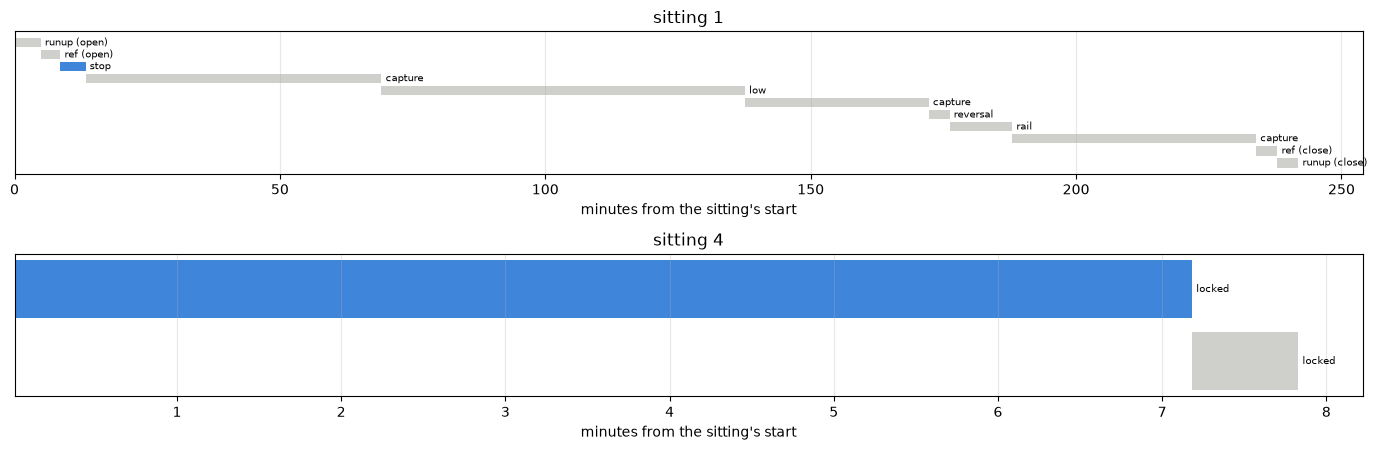

In [12]:
def plans(sitting):
    # each plan of a sitting with its start and end, minutes from the
    # sitting's first event, a plan ending where the next one starts
    m = manifest(sitting)
    t0 = m["t_host"].min()              # the sitting's first event
    p = m[m["event"] == "plan"][["t_host", "detail"]].copy()
    ends = list(p["t_host"].iloc[1:]) + [m["t_host"].max()]
    p["start_min"] = (p["t_host"] - t0) / 60
    p["end_min"] = (np.array(ends) - t0) / 60
    return p.rename(columns={"detail": "plan"}).reset_index(drop=True)


OURS = {1: "stop", 4: "locked"}         # the resistance plan per sitting
fig, ax = plt.subplots(2, 1, figsize=(14, 4.6))
for axis, sitting in zip(ax, (1, 4)):
    p = plans(sitting)
    ours = p.index[p["plan"] == OURS[sitting]][0]   # its first such plan
    for j, r in p.iterrows():
        mine = j == ours
        axis.barh(j, r["end_min"] - r["start_min"], left=r["start_min"],
                  color=BLUE if mine else MUTED, alpha=0.9 if mine else 0.4)
        axis.annotate(r["plan"], (r["end_min"], j), fontsize=7,
                      va="center", xytext=(3, 0), textcoords="offset points")
    axis.set_yticks([])
    axis.invert_yaxis()
    figures.label(axis, x="minutes from the sitting's start",
                  title=f"sitting {sitting}")
figures.finish(fig)

In [13]:
p1 = plans(1)
stop_at = p1[p1["plan"] == "stop"].iloc[0]
before = p1[p1["start_min"] < stop_at["start_min"]]
print(f"sitting 1: the stop plan starts {stop_at['start_min']:.1f} min in, "
      "after " + ", ".join(f"{r['plan']} ({r['start_min']:.1f} min)"
                           for _, r in before.iterrows()))
pilot = manifest(1).query("event == 'pilot'")["detail"].tolist()
print("the pilot before it:", pilot)
p4 = plans(4)
print("sitting 4: " + ", ".join(f"{r['plan']} at {r['start_min']:.1f} min"
                                for _, r in p4.iterrows()))
for name, ch in (("locked", CH_LOCKED), ("stop", CH_STOP)):
    m = manifest(SITTING[name])
    t0 = m["t_host"].min()
    print(f"{name}: sweeps from {(ch['t_start'].min() - t0) / 60:.1f} to "
          f"{(ch['t_end'].max() - t0) / 60:.1f} min into the sitting")

sitting 1: the stop plan starts 8.6 min in, after runup (open) (0.0 min), ref (open) (4.9 min)
the pilot before it: ['5.0 V 30 % for 300 ms: 3193 counts/s']
sitting 4: locked at 0.0 min, locked at 7.2 min
locked: sweeps from 0.0 to 6.8 min into the sitting
stop: sweeps from 8.6 to 13.1 min into the sitting


The stop chains ran 8.6 to 13.1 minutes into sitting 1, the servo's first. Before them only the 5 V 30 % pilot of 300 ms and the open run-up and reference plans had run on a motor whose brushes are new. In sitting 4 the locked laps ran first, and the inductance plan's bursts into the same lock followed them.

### One locked lap

The fourth locked sweep, chain 3 on 3.7 V, as recorded. The current, the two taps and the pot over the baseline and the two directions. Below it, what `meta.json` and the rows say.

segments: {0: 10000, 1: 6000, 2: 6000} | schedule: ['100@300'] | dirs: [1, -1] | rest ms: 20000 | rows dropped: 0
current limit 554 counts | rows carrying ntc_raw and vbus_raw: {'ntc_raw': 0, 'vbus_raw': 0}


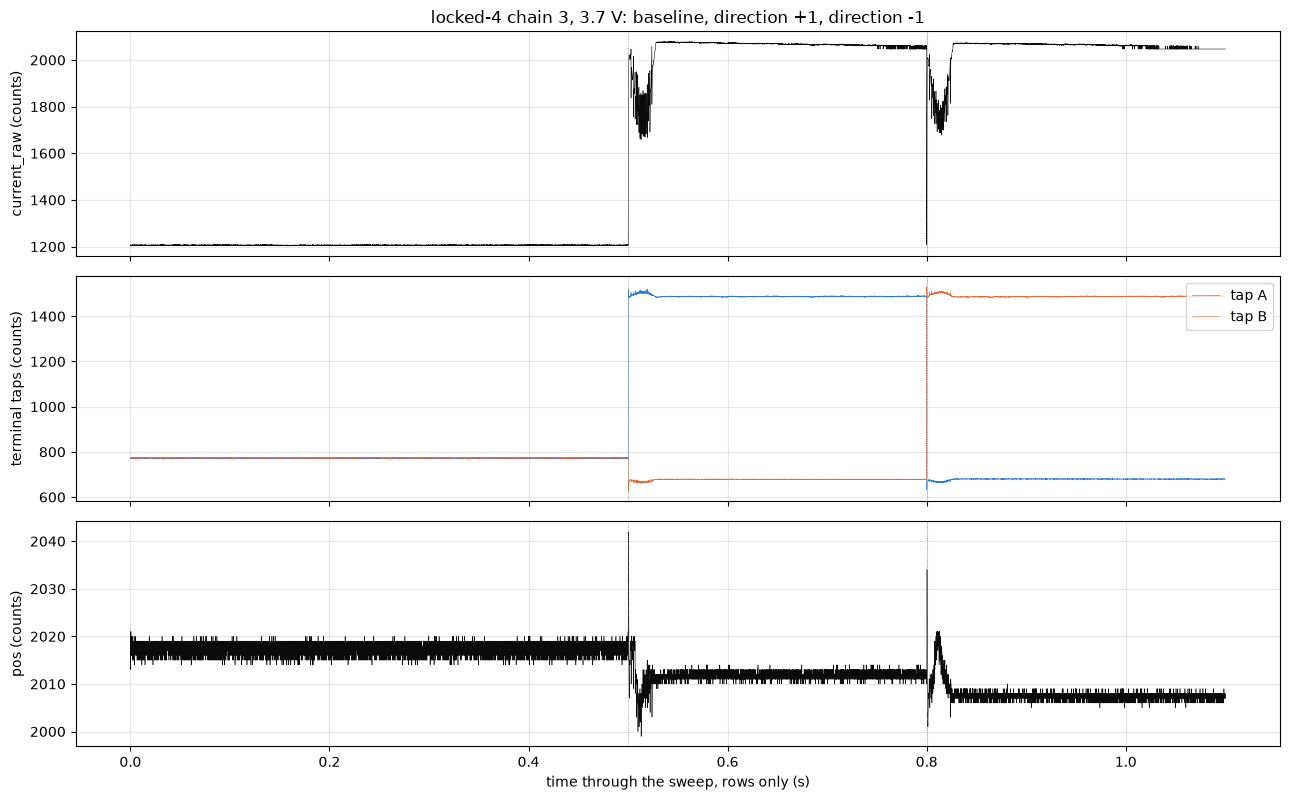

In [14]:
LAP_DF, LAP_META = tel.load(LOCKED / "chains" / "3", BOARD)   # checked
segs = LAP_DF["seg"].value_counts().sort_index().to_dict()
carried = {c: int(LAP_DF[c].notna().sum()) if c in LAP_DF else 0
           for c in ("ntc_raw", "vbus_raw")}
print("segments:", segs, "| schedule:", LAP_META["schedule"], "| dirs:",
      LAP_META["dirs"], "| rest ms:", LAP_META["rest_ms"],
      "| rows dropped:", LAP_META["rows_dropped"])
print("current limit", LAP_META["drive"]["current_limit_counts"],
      "counts | rows carrying ntc_raw and vbus_raw:", carried)
channels = [("current_raw (counts)", [(LAP_DF["current_raw"], INK)]),
            ("terminal taps (counts)", [(LAP_DF["vmotor_a"], BLUE, "tap A"),
                                        (LAP_DF["vmotor_b"], ORANGE,
                                         "tap B")]),
            ("pos (counts)", [(LAP_DF["pos"], INK)])]
fig, ax = figures.sweep_overview(
    LAP_DF, FS, channels,
    title="locked-4 chain 3, 3.7 V: baseline, direction +1, direction -1")
figures.finish(fig)

Half a second at the zero, then 300 ms each way. The 20 s rest between the two directions is not recorded, so the two streams sit end to end. The current channel reads the same current in both directions, since the shunt sits in the bridge's common return, and the taps swap. No row of the sweep carries `ntc_raw` or `vbus_raw`.

At the start of each direction the current rises to about 0.75 A, falls to about half of that within 15 ms and comes back. That dip is the rotor spinning free for a few turns before the lock takes the load, which the sections below read. The pot jumps by tens of counts at the same instant and is back within a couple of milliseconds, the same way in both directions. The horn moves at most a few counts against the lock, and a jump that fast and that large in both directions alike is a transient on the pot's reading at the current's step, not the seat.

### One stop chain

The first stop chain, chain 0 into the low stop, as recorded, with the applied duty in percent of the period.

segments: {0: 10000, 1: 6000, 2: 6000, 3: 6000} | schedule: ['24@300', 'then:36@300', 'then:24@300'] | stall: True | seek: 49 % | rows dropped: 0


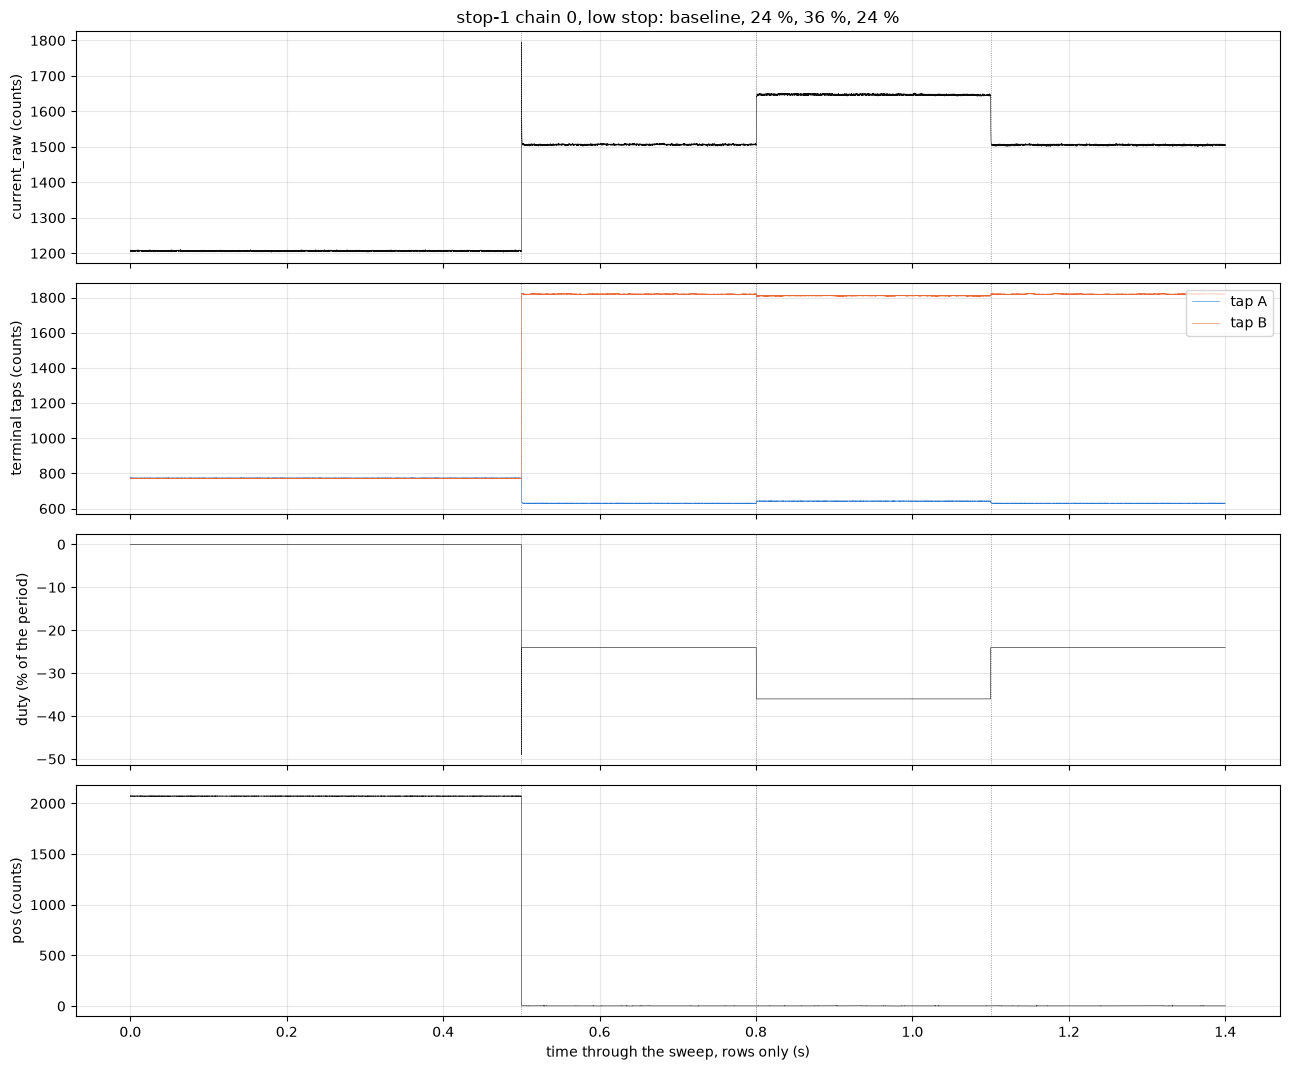

In [15]:
CHAIN_DF, CHAIN_META = tel.load(STOP / "chains" / "0", BOARD)
segs = CHAIN_DF["seg"].value_counts().sort_index().to_dict()
print("segments:", segs, "| schedule:", CHAIN_META["schedule"], "| stall:",
      CHAIN_META["stall"], "| seek:", CHAIN_META["seek_duty_pct"], "%",
      "| rows dropped:", CHAIN_META["rows_dropped"])
duty_pct = CHAIN_DF["duty_counts"] / ARR * 100      # signed, % of period
channels = [("current_raw (counts)", [(CHAIN_DF["current_raw"], INK)]),
            ("terminal taps (counts)",
             [(CHAIN_DF["vmotor_a"], BLUE, "tap A"),
              (CHAIN_DF["vmotor_b"], ORANGE, "tap B")]),
            ("duty (% of the period)", [(duty_pct, INK)]),
            ("pos (counts)", [(CHAIN_DF["pos"], INK)])]
fig, ax = figures.sweep_overview(
    CHAIN_DF, FS, channels,
    title="stop-1 chain 0, low stop: baseline, 24 %, 36 %, 24 %")
figures.finish(fig)

The baseline, then three segments of 300 ms at -24, -36 and -24 % with no release between them. Each segment opens with a few rows at the previous duty, the seek's 49 % before the first, and that is the stall press, not the step. The current settles within a millisecond at each step and stays flat. The pot reads 0 to 4 counts through the chain, at the bottom of its ADC range, 80 counts past the low end the servo's free stop reads with torque off. The stopper flexes under the press, and at the low end the pot's reading is on its rail and blind to the rotor.

## Method

### Conversions

The current over the sweep's own torque-off zero goes through the current-scale line, counts $= b + G_I\,I$, so

$$I = \frac{n - n_0 - b}{G_I}$$

with $n$ the current channel, $n_0$ the median of the second half of the sweep's baseline, $G_I$ the counts per amp and $b$ the in-drive offset. The terminal volts go through the terminal-chain line the same way,

$$V_\mathrm{on} = \frac{d\,(n_A - n_B) - c}{k_V}$$

with $n_A$ and $n_B$ the two taps, $d$ the direction, $k_V$ the counts per volt and $c$ its offset. The taps sit at the board's connector, so the reading carries the connector's contact and the servo's two motor leads on top of the motor. $V_\mathrm{on}$ is the crest sample's tap difference, the terminal volts while the bridge is on. The volts applied over a period are taken as

$$V_\mathrm{eff} = D\,V_\mathrm{on}$$

with $D$ ("D") the commanded duty, the window's ticks over 1200. At 100 % $D$ is 1 and $V_\mathrm{eff}$ is $V_\mathrm{on}$.

In [16]:
def boxcar(x, n=BOXCAR_ROWS):
    # the centered mean over n rows
    return np.convolve(x, np.ones(n) / n, mode="same")


def smooth_ratio(volts, amps):
    # V/I over the boxcar with its spoiled edges cut, and the rows kept
    keep = slice(EDGE_ROWS, len(volts) - EDGE_ROWS)
    return keep, (boxcar(volts) / boxcar(amps))[keep]


def held_rows(seg):
    # the rows of one segment at its held duty, the median of the
    # segment's second half, from the first row at that duty, so a seek
    # or the previous step's rows before it are out
    held = seg["duty_counts"].iloc[len(seg) // 2:].median()
    at = np.flatnonzero(seg["duty_counts"].to_numpy() == held)
    return seg.iloc[int(at[0]):], int(held), int(at[0])

In [17]:
def lap_signals(g, zero_i, direction, held):
    # current, crest volts and V_eff of one held stretch, row by row
    cur = g["current_raw"].to_numpy(float)          # counts
    taps = (g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * direction
    amps = SCALES.amps(cur, zero_i)     # over the zero, in-drive offset out
    v_on = SCALES.volts(taps, TAP_OFFSET)   # the crest tap difference
    duty = abs(held) / ARR              # the commanded duty, 1 at 100 %
    volts = duty * v_on                 # V_eff = D x V_on
    t = np.arange(len(g)) / FS          # s from the stretch's first row
    return {"cur": cur, "amps": amps, "v_on": v_on, "volts": volts,
            "duty": duty, "t": t, "pos": g["pos"].to_numpy(float)}

### Reading a lap

Stage 2's reading of a lap, unchanged. Each held stretch is read as a straight line through $V/I$ against time, from 60 ms after its first row to its end, extrapolated back to the first row. The value there, $R_\mathrm{start}$ ("R start"), is the path's resistance with the copper at the temperature it had when the lap began, and the line's slope is the warming rate. The current and the volts get lines of their own the same way, and their values at the first row are the points a line through the levels uses. The line's residual over 10 ms checks that the warming is straight. The settled mean from 2 ms, the early window 2 to 20 ms and the last 20 ms are read beside it for comparison.

In [18]:
def first_row_read(s):
    # V/I, I and V at the stretch's first row by lines over FIT_FROM_S
    # to the end, the V/I line's slope, its 10 ms residual, and the
    # current's scatter in counts over the same rows
    t, amps, volts = s["t"], s["amps"], s["volts"]
    late = t >= FIT_FROM_S
    ratio = volts / amps
    line = np.polyfit(t[late], ratio[late], 1)      # slope, first row
    resid = boxcar(ratio[late] - np.polyval(line, t[late]))
    resid_rms = np.sqrt(np.mean(resid[EDGE_ROWS:-EDGE_ROWS] ** 2))
    return {"r_first_ohm": line[1], "r_slope_ohm_per_s": line[0],
            "r_end_ohm": np.polyval(line, t[-1]),
            "i_first_a": np.polyfit(t[late], amps[late], 1)[1],
            "v_first_v": np.polyfit(t[late], volts[late], 1)[1],
            "resid_mohm": resid_rms * 1e3,
            "i_sd_counts": float(np.std(s["cur"][late]))}

In [19]:
def window_reads(s):
    # the plain means the line replaces, over their windows, for
    # comparison, and the lap's power and energy
    t, amps, volts = s["t"], s["amps"], s["volts"]
    early = (t >= EARLY_S[0]) & (t < EARLY_S[1])
    tail = t >= t[-1] - LATE_S
    settled = t >= SETTLED_FROM_S
    plateau = (t >= PLATEAU_S[0]) & (t < PLATEAU_S[1])
    power = volts * amps                # W, row by row
    return {"i_settled_a": amps[settled].mean(),
            "v_eff_settled_v": volts[settled].mean(),
            "v_on_settled_v": s["v_on"][settled].mean(),
            "r_settled_ohm": volts[settled].mean() / amps[settled].mean(),
            "r_early_ohm": volts[early].mean() / amps[early].mean(),
            "r_plateau_ohm": volts[plateau].mean() / amps[plateau].mean(),
            "r_tail_ohm": volts[tail].mean() / amps[tail].mean(),
            "watts": power[settled].mean(), "joules": power.sum() / FS,
            "lap_s": t[-1]}

### The plateau and the free spin

On a geared servo the early part of a locked lap carries something stage 2's bar on the pinion did not. The rotor turns through the train's play and the lock's give before the lock holds it, and while it turns its back-EMF takes current away. The read below finds the current's lowest point after its L/R rise, 1.5 ms, and before 30 ms, its fall under the plateau's mean from 30 to 60 ms, the EMF that fall implies at the plateau's $V_\mathrm{on}/I$, and when the current is back within 1 % of the plateau. Through this motor's $K_e$ the EMF is a speed. The plateau read, $V/I$ over 30 to 60 ms, sits after the spin and before most of the warming, a check on the first-row read beside it.

In [20]:
def free_spin(s):
    # the current's dip under its plateau after the L/R rise, the EMF the
    # dip implies at the plateau's V_on / I, and when the current is back
    # within BACK_SHARE of the plateau
    t, amps, v_on = s["t"], s["amps"], s["v_on"]
    plateau = (t >= PLATEAU_S[0]) & (t < PLATEAU_S[1])
    i_plateau = amps[plateau].mean()    # A, the level the dip falls from
    from_k = int(DIP_FROM_S * FS)       # row, past the L/R rise
    dip_k = from_k + int(np.argmin(amps[from_k:int(PLATEAU_S[0] * FS)]))
    back = np.flatnonzero((t > t[dip_k])
                          & (amps >= BACK_SHARE * i_plateau))
    until_s = float(t[back[0]]) if len(back) else np.nan
    r_on = v_on[plateau].mean() / i_plateau     # ohm, V_on / I there
    emf = float(v_on[dip_k] - r_on * amps[dip_k])   # V at the dip
    return {"i_plateau_a": i_plateau, "i_dip_a": float(amps[dip_k]),
            "t_dip_ms": float(t[dip_k] * 1e3), "emf_dip_v": emf,
            "spin_until_ms": until_s * 1e3}

In [21]:
def read_step(g, zero_i, direction, held, first_row):
    # every read of one held stretch, its signals kept for the figures
    s = lap_signals(g, zero_i, direction, held)
    settled = s["t"] >= SETTLED_FROM_S
    pos = s["pos"]
    return {"dir": direction, "duty_pct": s["duty"] * 100,
            "held_ticks": held, "rows_before_held": first_row,
            "rows": len(g), **first_row_read(s), **window_reads(s),
            **free_spin(s), "pos_median": float(np.median(pos[settled])),
            "pos_min": float(pos.min()), "pos_max": float(pos.max()),
            "pos_first": float(pos[0]),
            "pos_last": float(np.median(pos[-LAST_ROWS:])), "trace": s}

In [22]:
def sweep_steps(folder):
    # every driven segment of one sweep read as a step over the sweep's
    # own zero, with its seek rows and the baseline's pos
    df, meta = tel.load(folder, BOARD)  # checks the sense block
    zero_i, _ = tel.rest_zeros(df)      # the torque-off zero
    rest = tel.baseline(df)             # the baseline's rows
    missing = int(tel.gaps(df).sum())   # dropped rows, from tick
    out = []
    for seg, g in df[df["seg"] > 0].groupby("seg"):
        direction = int(g["dir"].iloc[0])
        g_held, held, first_row = held_rows(g)
        step = read_step(g_held, zero_i, direction, held, first_row)
        seek = g.iloc[:first_row]       # rows before the held duty
        seek_i = (float(SCALES.amps(seek["current_raw"].to_numpy(float),
                                    zero_i).mean()) if first_row else np.nan)
        step.update({"seg": int(seg), "zero_counts": float(zero_i),
                     "missing": missing,
                     "pos_rest": float(rest["pos"].median()),
                     "seek_rows": first_row, "seek_i_a": seek_i,
                     "seek_ticks": int(seek["duty_counts"].abs().max())
                     if first_row else 0})
        out.append(step)
    return out

### Which laps carry the number

$R_\mathrm{term}$ is the first-row read on the six 3.7 V laps, both directions, their mean with the range as the bounds. Stage 2's direction -1 lap ran a second after direction +1 and started warm, so stage 2 carried direction +1 alone. Here the two directions run 20 s apart and the copper, with a time constant near 2 s on the type, has cooled, so both carry the number and the directions are reported beside it. The 3.3 V laps sit off stage 1's graded lines and enter no number but the two-level line, which is report-only.

### The two-level line and its lever

The line $V = V_0 + R\,I$ through the first-row points of the two levels gives $R$ and $V_0$, in the form

$$\frac{V}{I} = R + \frac{V_0}{I},$$

so on a plot of $V/I$ against $1/I$ the slope is $V_0$ and the intercept $R$. The lever is how far $1/I$ moves between the levels. A change of 0.1 % in $V/I$ between them moves $V_0$ by $0.001\,R / \Delta(1/I)$, and that number says whether a pair of levels can hold a $V_0$ at all. The line is drawn twice, with the 3.3 V volts as read and over the stage 1 factor.

### The stop chain's construction

A stop step is read with the same functions, from its first row at the held duty, as $V_\mathrm{eff} / I_\mathrm{crest}$, the plain construction the sag notebook used, formed from the commanded duty, the crest tap difference and the crest current, the three things a pass on the board's own readings has. The rotor is pressed into its stop, so no spin opens a step. Per chain the two 24 % steps are averaged against the 36 % step, and $R$ and $V_0$ are the line through those two points. A warming that is linear through the chain cancels in the average, since the two 24 % steps sit either side of the 36 % one. The least squares line through all eighteen points is the check.

In [23]:
def chain_lines(t, i_col, v_col, label):
    # V = V0 + R I per chain: least squares through its three steps, and
    # through two points, the two 24 % steps averaged against the 36 %
    out = []
    for k, g in t.groupby("chain"):
        g = g.sort_values("step")
        f = laps.line(g[i_col], g[v_col])
        low = g[g["step"] != 2]                 # the two 24 % steps
        high = g[g["step"] == 2].iloc[0]        # the 36 % step
        i_lo, v_lo = low[i_col].mean(), low[v_col].mean()
        r2 = (high[v_col] - v_lo) / (high[i_col] - i_lo)
        s1 = g[g["step"] == 1].iloc[0]
        s3 = g[g["step"] == 3].iloc[0]
        warm = ((s3[v_col] / s3[i_col]) / (s1[v_col] / s1[i_col]) - 1) * 100
        out.append({"read": label, "chain": k, "stop": g["stop"].iloc[0],
                    "dir": g["dir"].iloc[0], "r_ls_ohm": f["slope"],
                    "r_ls_se": f["slope_se"], "v0_ls_v": f["intercept"],
                    "v0_ls_se": f["intercept_se"], "rms_mv": f["rms"] * 1e3,
                    "r_bracket_ohm": r2, "v0_bracket_v": v_lo - r2 * i_lo,
                    "step3_over_step1_pct": warm, "i_lo_a": i_lo,
                    "i_hi_a": high[i_col],
                    "lever_per_a": 1 / i_lo - 1 / high[i_col]})
    return pd.DataFrame(out)

### What stage 1 says the construction leaves out

$V_\mathrm{eff} = D\,V_\mathrm{on}$ over the crest current takes the commanded window as the applied one and the motor's volts between windows as zero. Stage 1 measured two board terms that say otherwise, both shown in the stage 1 values above.

- The edge lags. The tap's ON edge comes later after the commanded start than the OFF edge after the commanded end, so the applied window is `EDGE` ticks of the 2400 tick period shorter than $D$ says. The effective duty is $D' = (2 D \cdot 1200 - \mathrm{EDGE}) / 2400$ ("D prime").
- The brake drop. Between windows the bridge shorts the winding through its low side, and the terminals read the circulating current's drop across the low-side loop, $-R_\mathrm{loop}\,i$ ("R loop"). The period's mean volts are then $D' V_\mathrm{on} - (1 - D')\,R_\mathrm{loop}\,i$.

Both make the as-read $V/I$ high at partial duty and vanish at 100 %. A third term is the crest's over-read of the period's mean current, which stage 2 modeled as $G\,(1 - D)\,V_\mathrm{on}$, the held-stall form the inductance notebook used, or a constant offset. The function below builds the applied volts and the winding current under any mix of the three. With every term zero it gives the as-read construction.

In [24]:
def construct(d_cmd, v_on, i_crest, edge_ticks=0.0, loop_ohm=0.0,
              g_s=0.0, offset_a=0.0):
    # the applied volts and the winding current a construction gives
    # from the commanded duty D, the crest tap difference V_on and the
    # crest current: the window shortened by edge_ticks of the 2 x ARR
    # period, the brake interval's drop loop_ohm x i over the rest of
    # the period, the crest over the mean by g_s x (1 - D) V_on plus a
    # constant offset
    d_eff = (2 * d_cmd * ARR - edge_ticks) / (2 * ARR)
    i_mean = i_crest - g_s * (1 - d_cmd) * v_on - offset_a
    v = d_eff * v_on - (1 - d_eff) * loop_ohm * i_mean
    return v, i_mean

### Error bars

$R_\mathrm{term}$'s bounds are the range over the six laps, and its scatter the standard deviation over them. A stop line's bounds are one standard deviation over the six chains, and the pooled line's are its standard error. The constructions carry stage 1's bounds on the edge lags and the loop as separate rows, not as one error bar. A slope that a construction predicts is graded against the sag's measured slope in units of the sag's standard error, $\sigma$ ("sigma"). Nothing under $2\,\sigma$ is called a finding. The commutator's angle moves every terminal reading by a few percent on the type, and one seat per route here does not measure it.

## The locked laps

Every lap of the six locked sweeps through the reading above, one row per lap, with the board NTC from the probes around its sweep.

In [25]:
rows, TRACES = [], {}           # one row per lap, its signals by key
for _, c in CH_LOCKED.iterrows():
    k = int(c["k"])
    board_c = ntc_around(PROBES_LOCKED, c["t_start"], c["t_end"])[0]
    for s in sweep_steps(LOCKED / c["folder"]):
        TRACES[(k, s["dir"])] = s.pop("trace")
        rows.append({"chain": k, "volts_set": c["volts_set"],
                     "graded": c["volts_set"] >= RAIL_GRADED_V,
                     "pos_before": c["pos_before"],
                     "pos_after": c["pos_after"], "board_c": board_c, **s})
L = pd.DataFrame(rows)
first = L["r_first_ohm"]
L["rise_pct_per_s"] = L["r_slope_ohm_per_s"] / first * 100
L["pct_per_j"] = L["rise_pct_per_s"] / L["watts"]       # % per J
L["early_pct"] = (L["r_early_ohm"] / first - 1) * 100
L["settled_over_first_pct"] = (L["r_settled_ohm"] / first - 1) * 100
L["plateau_over_first_pct"] = (L["r_plateau_ohm"] / first - 1) * 100
L["dip_pct"] = (L["i_dip_a"] / L["i_plateau_a"] - 1) * 100
L["emf_dip_rev_s"] = L["emf_dip_v"] / KE     # the dip's EMF as a speed
L["pos_lap_shift"] = L["pos_after"] - L["pos_before"]
print(f"{len(L)} laps, {int(L['missing'].max())} rows missing in any "
      f"sweep, {L['rows_before_held'].min()} to "
      f"{L['rows_before_held'].max()} rows before the drive")

12 laps, 0 rows missing in any sweep, 0 to 8 rows before the drive


In [26]:
show(L[["chain", "volts_set", "dir", "i_first_a", "v_on_settled_v",
        "r_first_ohm", "r_plateau_ohm", "r_settled_ohm",
        "rise_pct_per_s", "watts", "joules", "pct_per_j", "resid_mohm",
        "i_sd_counts", "board_c", "pos_before", "pos_after"]].round(4),
     n=None)
settled = L["settled_over_first_pct"].mean()   # %, mean over the laps
print(f"settled mean over the first row {settled:+.2f} %, early window "
      f"{L['early_pct'].min():+.1f} to "
      f"{L['early_pct'].max():+.1f} %; line residual "
      f"{L['resid_mohm'].median():.1f} mohm median, "
      f"{L['resid_mohm'].max():.1f} at most")

,chain,volts_set,dir,i_first_a,v_on_settled_v,r_first_ohm,r_plateau_ohm,r_settled_ohm,rise_pct_per_s,watts,joules,pct_per_j,resid_mohm,i_sd_counts,board_c,pos_before,pos_after
0,0,3.300,1,0.741,3.209,4.322,4.338,4.499,7.447,2.288,0.685,3.255,1.964,4.225,26.096,2015,2015
1,0,3.300,-1,0.738,3.201,4.331,4.348,4.487,7.116,2.283,0.683,3.117,2.149,4.039,26.096,2015,2015
2,1,3.300,1,0.739,3.209,4.333,4.344,4.497,7.078,2.289,0.685,3.093,2.733,4.022,26.199,2015,2020
3,1,3.300,-1,0.736,3.202,4.341,4.347,4.496,6.548,2.279,0.682,2.874,1.563,3.706,26.199,2015,2020
4,2,3.300,1,0.739,3.210,4.335,4.351,4.501,7.400,2.288,0.686,3.235,2.017,4.157,26.236,2019,2019
5,2,3.300,-1,0.737,3.202,4.337,4.337,4.497,7.096,2.278,0.682,3.115,2.304,4.003,26.236,2019,2019
6,3,3.700,1,0.767,3.253,4.227,4.257,4.408,10.769,2.399,0.719,4.489,5.698,6.471,26.280,2020,2015
7,3,3.700,-1,0.767,3.247,4.212,4.269,4.422,15.960,2.383,0.714,6.697,12.728,8.978,26.280,2020,2015
8,4,3.700,1,0.766,3.255,4.230,4.251,4.396,9.554,2.409,0.722,3.966,2.236,5.103,26.317,2018,2018
9,4,3.700,-1,0.767,3.240,4.207,4.201,4.343,9.230,2.416,0.724,3.821,1.144,4.985,26.317,2018,2018


settled mean over the first row +4.01 %, early window +35.9 to +53.5 %; line residual 2.3 mohm median, 13.7 at most


One row per lap. At 3.7 V the first-row read is 4.207 to 4.230 ohm at 0.765 to 0.768 A, and at 3.3 V 4.322 to 4.341 ohm at 0.736 to 0.741 A. Each lap put 0.68 to 0.72 J into the motor at 2.3 to 2.4 W. The settled mean from 2 ms reads 4.0 % over the first row on average, and the early window 36 to 54 % over it, since both hold the free spin the next figure shows. The line leaves 2.3 mohm in the median over 10 ms and 13.7 mohm at most, on chain 5's -1 lap. No row is missing from any sweep.

In [27]:
def lap_panel(ax):
    # every lap's V/I through the lap, its line dotted back to its first
    # row, the stretch the line leaves out and the plateau shaded
    for _, r in L.iterrows():
        s = TRACES[(int(r["chain"]), int(r["dir"]))]
        keep, ratio = smooth_ratio(s["volts"], s["amps"])
        color = COLOR[r["volts_set"]]
        named = int(r["chain"]) in (0, 3)       # one legend entry a level
        ax.plot(s["t"][keep] * 1e3, ratio, lw=0.8, color=color,
                ls="-" if r["dir"] == 1 else "--",
                label=(f"{r['volts_set']:g} V, direction {int(r['dir']):+d}"
                       if named else None))
        ends = np.array([0, s["t"][-1]])        # s, the lap's two ends
        ax.plot(ends * 1e3, r["r_first_ohm"] + r["r_slope_ohm_per_s"] * ends,
                lw=0.6, color=INK, ls=":")
        ax.plot(0, r["r_first_ohm"], "o", ms=4, color=color)
    ax.axvspan(0, FIT_FROM_S * 1e3, color=MUTED, alpha=0.12,
               label="left out of the line")
    ax.axvspan(PLATEAU_S[0] * 1e3, PLATEAU_S[1] * 1e3, color=GREEN,
               alpha=0.10, label="the plateau read")
    ax.set_ylim(4.1, 4.6)
    ax.legend(fontsize=7, ncol=2)
    figures.label(ax, x="ms from the drive's first row",
                  y="V/I, 10 ms boxcar (ohm)",
                  title="the twelve locked laps")

The twelve laps' $V/I$ through the lap on the left, each lap's line dotted back to its first-row value, the 60 ms the line leaves out shaded gray and the plateau window green. In the middle and on the right, the current and the pot of chain 3's two laps over their first 40 ms. The thing to see is where the line starts against the free spin, and what the pot does at the step.

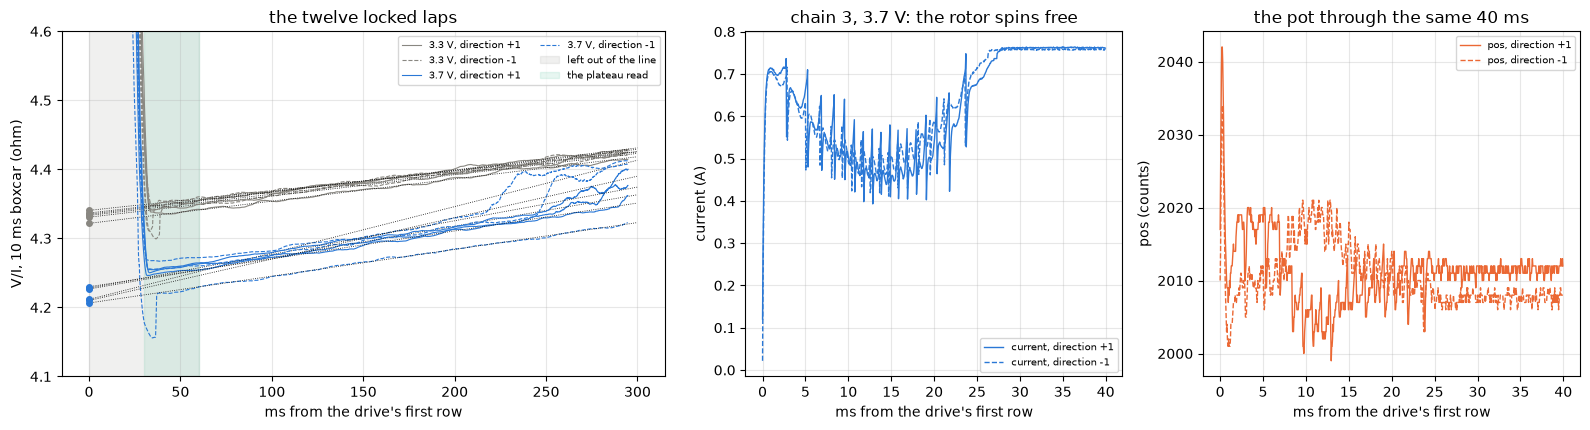

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4),
                       gridspec_kw={"width_ratios": [1.6, 1, 1]})
lap_panel(ax[0])
for d, ls in ((1, "-"), (-1, "--")):
    s = TRACES[(3, d)]
    m = s["t"] < 0.040                  # the first 40 ms
    ax[1].plot(s["t"][m] * 1e3, s["amps"][m], ls, lw=1, color=BLUE,
               label=f"current, direction {d:+d}")
    ax[2].plot(s["t"][m] * 1e3, s["pos"][m], ls, lw=1, color=ORANGE,
               label=f"pos, direction {d:+d}")
figures.label(ax[1], x="ms from the drive's first row", y="current (A)",
              title="chain 3, 3.7 V: the rotor spins free")
figures.label(ax[2], x="ms from the drive's first row", y="pos (counts)",
              title="the pot through the same 40 ms")
for a in ax[1:]:
    a.legend(fontsize=7)
figures.finish(fig)

In [29]:
print(f"dip {L['dip_pct'].mean():.0f} % under the plateau "
      f"({L['dip_pct'].min():.0f} to {L['dip_pct'].max():.0f}) at "
      f"{L['t_dip_ms'].min():.0f} to {L['t_dip_ms'].max():.0f} ms; EMF "
      f"{L['emf_dip_v'].min():.2f} to {L['emf_dip_v'].max():.2f} V, "
      f"{L['emf_dip_rev_s'].min():.0f} to {L['emf_dip_rev_s'].max():.0f} "
      f"rev/s (mean {L['emf_dip_rev_s'].mean():.0f}); back on the plateau by "
      f"{L['spin_until_ms'].min():.1f} to {L['spin_until_ms'].max():.1f} ms "
      f"(mean {L['spin_until_ms'].mean():.1f})")
jump, at_ms, after = [], [], []         # the pot at the step, and after
for (k, d), s in TRACES.items():
    rest = L[(L["chain"] == k) & (L["dir"] == d)]["pos_rest"].iloc[0]
    early = s["t"] < SETTLED_FROM_S     # the first 2 ms
    over = s["pos"][early] - rest       # counts over the baseline's pos
    jump.append(over.max())
    at_ms.append(s["t"][early][np.argmax(over)] * 1e3)
    after.append(np.median(s["pos"][~early]) - rest)
print(f"pot over the baseline in the first 2 ms: {min(jump):.0f} to "
      f"{max(jump):.0f} counts at {min(at_ms):.2f} to {max(at_ms):.2f} ms; "
      f"its median from 2 ms on {min(after):+.0f} to {max(after):+.0f} "
      "counts from the baseline")

dip -49 % under the plateau (-58 to -45) at 10 to 17 ms; EMF 1.61 to 2.02 V, 220 to 276 rev/s (mean 237); back on the plateau by 22.5 to 28.9 ms (mean 27.1)
pot over the baseline in the first 2 ms: 16 to 72 counts at 0.20 to 0.35 ms; its median from 2 ms on -11 to -3 counts from the baseline


After the L/R rise the current reaches about 0.7 A within a millisecond, then falls to a low point 45 to 58 % under the plateau, 49 % on average, at 10 to 17 ms, and is back within 1 % of the plateau by 22.5 to 28.9 ms in every lap. At the plateau's $V_\mathrm{on}/I$ the low point is an EMF of 1.61 to 2.02 V, 220 to 276 rev/s at this motor's $K_e$. The rotor runs through the train's play and the lock's give before the lock holds it, with high confidence, since all twelve laps show the same shape in both directions. Stage 2's bar on the pinion left an early fall of about 1 % over 30 to 50 ms. Here it is a dip of half the current over 25 ms. The line from 60 ms clears it by about 30 ms. The early window and the settled mean both hold it, so on a geared servo neither is a number.

The pot reads 16 to 72 counts over its baseline 0.20 to 0.35 ms into each lap and is back within a couple of milliseconds. Through the spin it wanders by about ten counts, and from 2 ms on its median sits 3 to 11 counts under the baseline. A jump that fast and that large, the same way in both directions, is a transient on the pot's reading at the current's step and not the seat, likely.

### $R_\mathrm{term}$

The headline read, the six 3.7 V laps' first-row values.

In [30]:
G3 = L[L["graded"]]                     # the six 3.7 V laps
LOW = L[~L["graded"]]                   # the six 3.3 V laps
R_TERM = G3["r_first_ohm"].mean()       # ohm, the headline
R_TERM_SD = G3["r_first_ohm"].std()     # ohm, over the six laps
I_TERM = G3["i_first_a"].mean()         # A, its current
T_ROOM = L["board_c"].median()          # C, the board NTC, the room's
R_DIR = G3.groupby("dir")["r_first_ohm"]
print(f"R_term (3.7 V, both directions, 6 laps): {R_TERM:.4f} ohm sd "
      f"{R_TERM_SD:.4f} ({R_TERM_SD / R_TERM * 100:.2f} %) at {I_TERM:.4f}"
      f" A, {G3['r_first_ohm'].min():.4f} to {G3['r_first_ohm'].max():.4f}")
print("by direction: " + ", ".join(
    f"{d:+d} {g.mean():.4f} sd {g.std():.4f}" for d, g in R_DIR))
print(f"median over the six laps {G3['r_first_ohm'].median():.4f} ohm; the "
      f"inductance anchor {R_ANCHOR['value']:.4f}")
print(f"board NTC median {T_ROOM:.2f} C ({L['board_c'].min():.2f} to "
      f"{L['board_c'].max():.2f})")

R_term (3.7 V, both directions, 6 laps): 4.2189 ohm sd 0.0105 (0.25 %) at 0.7666 A, 4.2065 to 4.2300
by direction: -1 4.2094 sd 0.0027, +1 4.2283 sd 0.0017
median over the six laps 4.2192 ohm; the inductance anchor 4.2189
board NTC median 26.26 C (26.10 to 26.32)


The six 3.7 V laps read $R_\mathrm{term}$ = 4.2189 ohm, sd 0.0105 (0.25 %), at 0.7666 A, from 4.2065 to 4.2300. Direction +1 reads 4.2283 and direction -1 4.2094, and the median of the six is 4.2192. The inductance notebook read the same laps for its anchor and got 4.2189, which this read confirms. This is $V/I$ at 0.767 A with $V_0$ inside it, stage 2's definition of $R_\mathrm{term}$, and no construction enters it. The board's NTC read 26.10 to 26.32 C through the plan.

### The two directions

Direction -1's first-row read over direction +1's, per sweep. The -1 lap runs 20 s after the +1 lap.

In [31]:
GAPS = L.pivot(index=["chain", "volts_set"], columns="dir",
               values="r_first_ohm")
GAPS["gap_pct"] = (GAPS[-1] / GAPS[1] - 1) * 100    # -1 over +1, 20 s on
show(GAPS.round(4).reset_index(), n=None)
for v, g in GAPS.groupby(level="volts_set"):
    print(f"{v} V: direction -1 over +1 {g['gap_pct'].mean():+.2f} % "
          f"({g['gap_pct'].min():+.2f} to {g['gap_pct'].max():+.2f})")
gap3 = GAPS.xs(3.7, level="volts_set")["gap_pct"]
sd_each = G3.groupby("dir")["r_first_ohm"].std() / R_TERM * 100
print(f"3.7 V gap {gap3.mean():+.2f} % against each direction's sd "
      f"{sd_each.min():.2f} to {sd_each.max():.2f} % over three laps; the "
      f"gap over its own standard error "
      f"{gap3.mean() / (gap3.std() / np.sqrt(len(gap3))):+.1f}")

dir,chain,volts_set,-1,1,gap_pct
0,0,3.300,4.331,4.322,0.207
1,1,3.300,4.341,4.333,0.168
2,2,3.300,4.337,4.335,0.043
3,3,3.700,4.212,4.227,-0.356
4,4,3.700,4.207,4.230,-0.557
5,5,3.700,4.210,4.228,-0.427


3.3 V: direction -1 over +1 +0.14 % (+0.04 to +0.21)
3.7 V: direction -1 over +1 -0.45 % (-0.56 to -0.36)
3.7 V gap -0.45 % against each direction's sd 0.04 to 0.06 % over three laps; the gap over its own standard error -7.6


At 3.7 V direction -1 reads 0.36 to 0.56 % under direction +1, -0.45 % on average. At 3.3 V it reads 0.04 to 0.21 % over it. Stage 2 had direction -1 1.19 % over +1 a second after it and read that as heat carried from the first lap. With 20 s between them here the copper's heat is gone, and at 3.7 V the sign has turned. Within each direction the three 3.7 V laps scatter by 0.04 to 0.06 %, so the gap is several times the laps' own scatter. Direction and order go together, since the -1 lap always runs second. The 3.7 V -1 laps are also among the noisiest and steepest, the next section shows. Creep that differs by sign is the first candidate, and a direction term at the brushes the second. $R_\mathrm{term}$ is carried over both directions with the two beside it.

### The quiet gate and the plateau

The plant traps set a gate for a quiet locked rotor, a current sd of 4.5 counts or less. Below, each lap over the plateau and over the line's 60 to 300 ms, with the pot's range and the largest change of the 10 ms $V/I$ over 10 ms.

In [32]:
def quiet(s, lo, hi):
    # the quiet-rotor gate over [lo, hi) s: the current's sd in counts,
    # the pot's range, and the largest change of the 10 ms V/I over 10 ms
    m = (s["t"] >= lo) & (s["t"] < hi)
    counts = s["amps"] * SCALES.counts_per_a    # counts over the zero
    ratio = boxcar(s["volts"])[m] / boxcar(s["amps"])[m]
    step = (np.max(np.abs(ratio[STEP_ROWS:] - ratio[:-STEP_ROWS]))
            / ratio.mean() * 100 if m.sum() > 2 * STEP_ROWS else np.nan)
    return {"i_sd_counts": counts[m].std(),
            "pos_range": s["pos"][m].max() - s["pos"][m].min(),
            "max_10ms_step_pct": step}


QL = pd.DataFrame([{"chain": k, "level": L[L["chain"] == k][
                        "volts_set"].iloc[0], "dir": d, "window": name,
                    **quiet(s, lo, hi)}
                   for (k, d), s in TRACES.items()
                   for name, lo, hi in (("plateau 30-60", *PLATEAU_S),
                                        ("line 60-300", FIT_FROM_S, 0.3))])
QL["over_gate"] = QL["i_sd_counts"] > QUIET_SD_COUNTS
show(QL.round(3), n=None)

,chain,level,dir,window,i_sd_counts,pos_range,max_10ms_step_pct,over_gate
0,0,3.300,1,plateau 30-60,1.207,4.000,4.471,False
1,0,3.300,1,line 60-300,4.225,5.000,0.222,False
2,0,3.300,-1,plateau 30-60,1.453,4.000,2.403,False
3,0,3.300,-1,line 60-300,4.039,5.000,0.200,False
4,1,3.300,1,plateau 30-60,1.246,4.000,2.648,False
5,1,3.300,1,line 60-300,4.022,6.000,0.276,False
6,1,3.300,-1,plateau 30-60,5.057,9.000,1.001,True
7,1,3.300,-1,line 60-300,3.706,5.000,0.175,False
8,2,3.300,1,plateau 30-60,1.244,4.000,2.972,False
9,2,3.300,1,line 60-300,4.157,5.000,0.215,False


In [33]:
for (window, level), g in QL.groupby(["window", "level"]):
    over = g[g["over_gate"]]
    print(f"{window}, {level} V: current sd {g['i_sd_counts'].min():.2f} "
          f"to {g['i_sd_counts'].max():.2f} counts, largest 10 ms step "
          f"{g['max_10ms_step_pct'].max():.3f} %; over the "
          f"{QUIET_SD_COUNTS} gate: " + (", ".join(
              f"chain {int(r['chain'])} {int(r['dir']):+d}"
              for _, r in over.iterrows()) or "none"))
copper_rate = (RR_B["warming_pct_per_j"]["value"] / 100
               * G3["watts"].mean())   # per s, the type's at this power
R_PLATEAU = G3["r_plateau_ohm"].mean()
R_PLATEAU_COLD = R_PLATEAU / (1 + copper_rate * PLATEAU_MID_S)
print(f"plateau read (3.7 V, 6 laps): {R_PLATEAU:.4f} ohm sd "
      f"{G3['r_plateau_ohm'].std():.4f} ({G3['r_plateau_ohm'].min():.4f} "
      f"to {G3['r_plateau_ohm'].max():.4f}); less the type's copper "
      f"warming to {PLATEAU_MID_S * 1e3:.0f} ms: {R_PLATEAU_COLD:.4f}, "
      f"{(R_PLATEAU_COLD / R_TERM - 1) * 100:+.2f} % on R_term")

line 60-300, 3.3 V: current sd 3.71 to 4.23 counts, largest 10 ms step 0.276 %; over the 4.5 gate: none
line 60-300, 3.7 V: current sd 4.98 to 8.98 counts, largest 10 ms step 1.247 %; over the 4.5 gate: chain 3 +1, chain 3 -1, chain 4 +1, chain 4 -1, chain 5 +1, chain 5 -1
plateau 30-60, 3.3 V: current sd 1.21 to 16.71 counts, largest 10 ms step 4.471 %; over the 4.5 gate: chain 1 -1, chain 2 -1
plateau 30-60, 3.7 V: current sd 0.98 to 28.26 counts, largest 10 ms step 1.749 %; over the 4.5 gate: chain 4 -1
plateau read (3.7 V, 6 laps): 4.2491 ohm sd 0.0244 (4.2008 to 4.2695); less the type's copper warming to 45 ms: 4.2360, +0.41 % on R_term


In [34]:
rows = []                       # the lowest 10 ms V/I on the plateau
for (k, d), s in TRACES.items():
    keep, ratio = smooth_ratio(s["volts"], s["amps"])
    t = s["t"][keep]
    m = (t >= PLATEAU_S[0]) & (t < PLATEAU_S[1])
    j = int(np.argmin(ratio[m]))
    rows.append({"chain": k, "dir": d, "low_ohm": ratio[m][j],
                 "at_ms": t[m][j] * 1e3})
DIPS = pd.DataFrame(rows).sort_values("low_ohm")
show(DIPS.head(3).round(3), n=None)

,chain,dir,low_ohm,at_ms
9,4,-1,4.156,34.750
8,4,1,4.246,32.850
6,3,1,4.250,33.200


Over the line's 60 to 300 ms every 3.7 V lap is over the gate, at 4.98 to 8.98 counts, and every 3.3 V lap under it, at 3.71 to 4.23. The 3.7 V traces also carry steps of up to 1.25 % in 10 ms, against 0.28 % at most at 3.3 V. On the plateau three laps are over the gate, chain 4's -1 lap at 3.7 V at 28 counts and chain 2's and chain 1's -1 laps at 3.3 V at 17 and 5 counts. Chain 4's -1 lap dips to 4.156 ohm at 35 ms inside the plateau window, the dashed blue trace under the others in the figure above.

The plateau read over the six 3.7 V laps is 4.2491 ohm, sd 0.0244, from 4.2008 to 4.2695, a spread more than twice the first-row read's. Less the type's copper warming to the window's middle, 45 ms, it is 4.2360, 0.41 % over the extrapolated 4.2189. So the choice between the plateau and the first row is worth about 0.4 %, and the plateau stays a secondary check beside the first-row read.

### The warming

Each lap's line slope per watt against the type's.

In [35]:
PCT_PER_J = G3["pct_per_j"].mean()      # % per J, the 3.7 V laps
ALPHA_CU = 1 / (COPPER_ZERO_C + T_ROOM)  # per C, copper at the room
C_MAX = ALPHA_CU * 100 / PCT_PER_J      # J/C, all copper, no heat lost
print(f"warming: 3.7 V laps {PCT_PER_J:.2f} % per J "
      f"({G3['pct_per_j'].min():.2f} to {G3['pct_per_j'].max():.2f}), "
      f"{G3['rise_pct_per_s'].min():.1f} to {G3['rise_pct_per_s'].max():.1f}"
      f" %/s at {G3['watts'].mean():.2f} W; 3.3 V laps "
      f"{LOW['pct_per_j'].mean():.2f} % per J at {LOW['watts'].mean():.2f} W")
print(f"type: mg90-b {RR_B['warming_pct_per_j']['value']:.2f}, mg90-c "
      f"{RR_C['warming_pct_per_j']['value']:.2f} % per J")
print(f"if every ohm were copper keeping all its heat: at most "
      f"{C_MAX:.3f} J/C, {C_MAX / C_CU:.2f} g of copper (report-only)")

warming: 3.7 V laps 4.96 % per J (3.82 to 6.70), 9.2 to 16.0 %/s at 2.40 W; 3.3 V laps 3.11 % per J at 2.28 W
type: mg90-b 2.86, mg90-c 3.44 % per J
if every ohm were copper keeping all its heat: at most 0.077 J/C, 0.20 g of copper (report-only)


The 3.7 V laps' lines rise 9.2 to 16.0 % per second, 3.82 to 6.70 % per joule and 4.96 on average, against the type's 2.86 on mg90-b and 3.44 on mg90-c. The 3.3 V laps rise 3.11 % per joule at nearly the same power, 2.28 W against 2.40 W. Copper warming 60 % faster per joule at 3.7 V than at 3.3 V does not fit the power, and the 3.7 V laps are the ones over the quiet gate and with the steps. A rotor creeping a fraction of a commutation period against the train's and the lock's compliance would move a brush over a segment edge and the terminal $R$ with it. Through 308:1, 60 motor degrees is under 4 pot counts, so the pot would not show it. The slope at 3.7 V is copper plus creep, likely, and the warming per joule from these laps is not the copper's. The bound it gives, at most 0.077 J per C or 0.20 g of copper if every ohm were copper keeping all its heat, is report-only.

### The 3.3 V level and the two-level line

The 3.3 V laps against the 3.7 V laps, the lever between the levels, and the line through the two levels with the 3.3 V volts as read and over the stage 1 factor.

In [36]:
EXCESS_3V3 = (LOW.groupby("dir")["r_first_ohm"].mean()
              / G3.groupby("dir")["r_first_ohm"].mean() - 1) * 100
EXCESS_ALL = (LOW["r_first_ohm"].mean() / R_TERM - 1) * 100
LEVER = 1 / LOW["i_first_a"].mean() - 1 / G3["i_first_a"].mean()
MV_PER_0P1 = 0.001 * R_TERM / LEVER * 1e3   # mV of V0 per 0.1 % of V/I
print(f"3.3 V laps over the 3.7 V laps {EXCESS_ALL:+.2f} % (" + ", ".join(
    f"{d:+d} {v:+.2f} %" for d, v in EXCESS_3V3.items())
    + f") at {LOW['i_first_a'].mean():.3f} against {I_TERM:.3f} A")
print(f"stage 1 at 3.3 V on the bare load {(F_3V3 - 1) * 100:+.2f} %; the "
      f"lever 1/I {LEVER:.4f} per A, so 0.1 % of V/I is {MV_PER_0P1:.0f} mV"
      f" of V0; a 0.1 V drop adds {0.1 * LEVER / R_TERM * 100:.2f} % at 3.3 V")
print(f"a factor at 3.3 V of exactly {1 + EXCESS_ALL / 100:.4f} puts V0 at "
      "zero")

3.3 V laps over the 3.7 V laps +2.71 % (-1 +3.01 %, +1 +2.41 %) at 0.738 against 0.767 A
stage 1 at 3.3 V on the bare load +3.94 %; the lever 1/I 0.0507 per A, so 0.1 % of V/I is 83 mV of V0; a 0.1 V drop adds 0.12 % at 3.3 V
a factor at 3.3 V of exactly 1.0271 puts V0 at zero


In [37]:
def level_lines(table, scale_3v3=1.0, pool=False):
    # V = V0 + R I through the two levels' first-row points, per
    # direction or pooled, the 3.3 V volts divided by scale_3v3
    groups = [("both", table)] if pool else list(table.groupby("dir"))
    out = []
    for d, t in groups:
        low = t["volts_set"] < RAIL_GRADED_V
        volts = np.where(low, t["v_first_v"] / scale_3v3, t["v_first_v"])
        f = laps.line(t["i_first_a"], volts)
        out.append({"dir": d, "r_ohm": f["slope"], "r_se": f["slope_se"],
                    "v0_v": f["intercept"], "v0_se": f["intercept_se"],
                    "rms_mv": f["rms"] * 1e3, "n": f["n"]})
    return pd.DataFrame(out)


LEVEL_LINES = {name: pd.concat([level_lines(L, s), level_lines(L, s, True)],
                               ignore_index=True)
               for name, s in (("as read", 1.0), ("scaled", F_3V3))}
for name, t in LEVEL_LINES.items():
    print(f"3.3 V {name}:")
    show(t.round(4), n=None)

3.3 V as read:


,dir,r_ohm,r_se,v0_v,v0_se,rms_mv,n
0,-1,1.212,0.053,2.302,0.040,1.623,6
1,1,1.430,0.048,2.144,0.036,1.292,6
2,both,1.311,0.089,2.230,0.067,4.049,12


3.3 V scaled:


,dir,r_ohm,r_se,v0_v,v0_se,rms_mv,n
0,-1,5.151,0.100,-0.721,0.075,3.074,6
1,1,5.965,0.160,-1.329,0.121,4.286,6
2,both,5.505,0.157,-0.985,0.118,7.168,12


The 3.3 V laps read 2.71 % over the 3.7 V laps, +2.41 % in direction +1 and +3.01 % in -1, at 0.738 A against 0.767 A. Stage 1 found $V/I$ at that level 3.94 % over the truth on the bare load at 0.56 A, from the regulator running out of headroom, and the type motors read 2.45 and 1.24 % there in stage 2. A contact drop of 0.1 V would add only 0.12 % at the lower current, so the level's excess is the chain's and not a lever on $V_0$.

The lever is small. The two levels are 0.03 A apart, $1/I$ moves 0.0507 per A, and 0.1 % of $V/I$ is 83 mV of $V_0$. Through the two levels as read the line gives $R$ = 1.31 +/- 0.09 ohm and $V_0$ = +2.23 +/- 0.07 V. With the 3.3 V volts over the stage 1 factor it gives $R$ = 5.50 +/- 0.16 ohm and $V_0$ = -0.98 +/- 0.12 V. A factor of exactly 1.0271 would put $V_0$ at zero. The rails were chosen under the lock's 0.85 A hold and the motor's 5 V, and on this board they leave no room for a $V_0$, with high confidence. The two-level line is report-only, and $R_\mathrm{term}$ stays $V/I$ at 0.767 A with $V_0$ inside, as stage 2 defined it.

## The gap to the type

mg90-d's $R_\mathrm{term}$ against the two type motors' at their own currents and board temperatures, and with the type scaled to this board's temperature at copper's 0.39 % per C on the whole resistance. That scaling is an upper bound on the correction, since only the copper's share moves.

In [38]:
rows = []
for key, rr in TYPES.items():
    r_type = rr["r_term_median_ohm"]["value"]       # ohm, its holes' median
    d_t = T_ROOM - rr["board_ntc_c"]["value"]       # C, board to board
    r_at = r_type * (1 + COPPER_PCT_PER_C / 100 * d_t)  # all of it copper
    rows.append({"type": key, "r_type_ohm": r_type,
                 "lo": rr["r_term_median_ohm"]["lo"],
                 "hi": rr["r_term_median_ohm"]["hi"],
                 "type_amps": rr["r_term_amps"]["value"],
                 "type_board_c": rr["board_ntc_c"]["value"],
                 "gap_pct": (R_TERM / r_type - 1) * 100, "dT_c": d_t,
                 "r_type_at_this_board_c": r_at,
                 "gap_at_common_t_pct": (R_TERM / r_at - 1) * 100})
TYPE_GAP = pd.DataFrame(rows).set_index("type")
show(TYPE_GAP.round(4).reset_index(), n=None)
lowest = min(rr["r_term_median_ohm"]["lo"] for rr in TYPES.values())
print(f"{int((G3['r_first_ohm'] < lowest).sum())} of {len(G3)} laps under "
      f"the type's lowest hole, {lowest:.3f} ohm")
r_pair = (R_TERM * I_TERM - R_SAG * I_SAG) / (I_TERM - I_SAG)
print(f"with the sag laps as read: R {r_pair:.3f} ohm, V0 "
      f"{R_SAG * I_SAG - r_pair * I_SAG:+.3f} V")

,type,r_type_ohm,lo,hi,type_amps,type_board_c,gap_pct,dT_c,r_type_at_this_board_c,gap_at_common_t_pct
0,mg90-b,4.455,4.384,4.531,0.784,25.677,-5.306,0.582,4.465,-5.521
1,mg90-c,4.402,4.283,4.439,0.792,22.725,-4.161,3.533,4.463,-5.464


6 of 6 laps under the type's lowest hole, 4.283 ohm
with the sag laps as read: R 4.124 ohm, V0 +0.073 V


mg90-d reads 5.31 % under mg90-b's 4.455 ohm and 4.16 % under mg90-c's 4.402. With the type scaled to 26.3 C both gaps are 5.5 %. The currents sit within 3 % of each other, so the comparison is at one current. All six 3.7 V laps sit under the lowest of the type's holes, 4.283 ohm. The loop here holds the servo's two motor leads and its connector on top of the motor, where the bare motors had their tabs soldered to the rig's leads, and that path adds. So mg90-d's winding and brushes read at least 5 % under both type motors, which differ by 1.2 % from each other, with high confidence on the difference. Its cause is open. Motor-to-motor spread and a new brush pair with its own film are the live candidates. The commutator angle is unlikely to hold 5 %, since the type's holes spread 3.3 and 3.5 % and the six laps here spread 0.25 %. A meter reading at a milliamp on the servo's motor leads at the connector, stage 2's ohms route, would separate them, and it is not in the stage 3 plan.

Paired with the sag laps as read, 4.344 ohm at 0.330 A, the lock gives $R$ = 4.124 ohm and $V_0$ = +0.073 V, the inductance notebook's pair. The section on the three reads shows why that pair is not the motor's line.

## The stop chains

Every step of the six chains through the same reading, from its first row at the held duty, one row per step.

In [39]:
rows, STOP_TRACES = [], {}      # one row per step, signals by key
for _, c in CH_STOP.iterrows():
    k = int(c["k"])
    board_c = ntc_around(PROBES_STOP, c["t_start"], c["t_end"])[0]
    stop = "low" if c["stop"] == "rev" else "high"
    for s in sweep_steps(STOP / c["folder"]):
        STOP_TRACES[(k, s["seg"])] = s.pop("trace")
        pressed = ((stop == "low" and s["dir"] == -1)
                   or (stop == "high" and s["dir"] == 1))
        rows.append({"chain": k, "stop": stop, "pressed_into_stop": pressed,
                     "seat_pos_runner": c["seat_pos"], "board_c": board_c,
                     "step": s["seg"], **s})
T = pd.DataFrame(rows)
T["rise_pct_per_s"] = T["r_slope_ohm_per_s"] / T["r_first_ohm"] * 100
T["pct_per_j"] = T["rise_pct_per_s"] / T["watts"]
first_steps = T[T["step"] == 1]
print(f"{len(T)} steps, every one pressed into its stop: "
      f"{bool(T['pressed_into_stop'].all())}; {int(T['missing'].max())} rows "
      f"missing; the seek press {first_steps['seek_rows'].min()} to "
      f"{first_steps['seek_rows'].max()} rows at "
      f"{first_steps['seek_i_a'].mean():.2f} A and "
      f"{first_steps['seek_ticks'].max()} ticks before step 1; steps 2 and"
      f" 3 open with {T[T['step'] > 1]['rows_before_held'].min()} to "
      f"{T[T['step'] > 1]['rows_before_held'].max()} rows of the step before")

18 steps, every one pressed into its stop: True; 0 rows missing; the seek press 1 to 9 rows at 0.52 A and 588 ticks before step 1; steps 2 and 3 open with 0 to 9 rows of the step before


In [40]:
show(T[["chain", "stop", "dir", "step", "duty_pct", "i_settled_a",
        "v_on_settled_v", "v_eff_settled_v", "r_first_ohm",
        "r_settled_ohm", "rise_pct_per_s", "resid_mohm", "i_sd_counts",
        "pos_median", "pos_min", "pos_max", "board_c"]].round(4), n=None)
KIND = T.assign(kind=np.where(T["step"] == 2, 36, 24)).groupby("kind")
for kind, g in KIND:
    print(f"{kind} %: settled {g['i_settled_a'].min():.4f} to "
          f"{g['i_settled_a'].max():.4f} A (sd {g['i_settled_a'].std():.4f}),"
          f" V_on {g['v_on_settled_v'].min():.3f} to "
          f"{g['v_on_settled_v'].max():.3f} V, V_eff/I settled "
          f"{g['r_settled_ohm'].mean():.4f}, slope "
          f"{g['rise_pct_per_s'].min():+.2f} to "
          f"{g['rise_pct_per_s'].max():+.2f} %/s at "
          f"{g['watts'].mean():.2f} W")
QS = pd.DataFrame([{"chain": k, "step": st, **quiet(s, FIT_FROM_S, 0.3)}
                   for (k, st), s in STOP_TRACES.items()])
print(f"quiet gate over 60-300 ms: current sd {QS['i_sd_counts'].min():.2f}"
      f" to {QS['i_sd_counts'].max():.2f} counts, largest 10 ms step "
      f"{QS['max_10ms_step_pct'].min():.2f} to "
      f"{QS['max_10ms_step_pct'].max():.2f} %; residual "
      f"{T['resid_mohm'].min():.1f} to {T['resid_mohm'].max():.1f} mohm")

,chain,stop,dir,step,duty_pct,i_settled_a,v_on_settled_v,v_eff_settled_v,r_first_ohm,r_settled_ohm,rise_pct_per_s,resid_mohm,i_sd_counts,pos_median,pos_min,pos_max,board_c
0,0,low,-1,1,24.000,0.259,4.777,1.146,4.425,4.424,-0.256,4.208,1.112,2.000,1.000,4.000,26.029
1,0,low,-1,2,36.000,0.383,4.691,1.689,4.399,4.409,1.595,3.138,1.461,2.000,1.000,4.000,26.029
2,0,low,-1,3,24.000,0.259,4.777,1.147,4.429,4.435,0.836,4.974,1.210,2.000,1.000,4.000,26.029
3,1,high,1,1,24.000,0.260,4.780,1.147,4.416,4.408,-1.001,3.655,1.127,3806.000,3802.000,3812.000,26.000
4,1,high,1,2,36.000,0.383,4.694,1.690,4.398,4.412,1.950,2.771,1.346,3806.000,3802.000,3812.000,26.000
5,1,high,1,3,24.000,0.259,4.781,1.147,4.431,4.432,0.363,4.205,1.335,3806.000,3795.000,3815.000,26.000
6,2,low,-1,1,24.000,0.259,4.776,1.146,4.427,4.423,-0.701,3.224,1.060,2.000,1.000,4.000,26.022
7,2,low,-1,2,36.000,0.382,4.689,1.688,4.414,4.417,0.592,2.682,1.236,2.000,0.000,4.000,26.022
8,2,low,-1,3,24.000,0.258,4.777,1.147,4.443,4.438,-0.563,3.340,1.206,2.000,0.000,4.000,26.022
9,3,high,1,1,24.000,0.260,4.779,1.147,4.407,4.411,0.232,4.929,1.102,3807.000,3799.000,3817.000,26.037


24 %: settled 0.2584 to 0.2613 A (sd 0.0009), V_on 4.776 to 4.781 V, V_eff/I settled 4.4204, slope -1.00 to +0.84 %/s at 0.30 W
36 %: settled 0.3822 to 0.3850 A (sd 0.0009), V_on 4.689 to 4.695 V, V_eff/I settled 4.4065, slope +0.59 to +2.12 %/s at 0.65 W


quiet gate over 60-300 ms: current sd 1.04 to 1.49 counts, largest 10 ms step 0.19 to 0.40 %; residual 2.1 to 5.7 mohm


The seek press opens each chain's first step with 1 to 9 rows at 0.52 A and 588 ticks, 49 % of the period, and steps 2 and 3 open with 0 to 9 rows of the step before. Those rows are out of every read, and no row is missing. The 24 % steps settle at 0.2584 to 0.2613 A on a $V_\mathrm{on}$ of 4.776 to 4.781 V, and the 36 % steps at 0.3822 to 0.3850 A on 4.689 to 4.695 V. The steps are quiet. Over 60 to 300 ms their current sd is 1.04 to 1.49 counts against the gate's 4.5, their largest 10 ms step of $V/I$ 0.19 to 0.40 %, and the line's residual 2.1 to 5.7 mohm. Within a step the slope is +0.59 to +2.12 % per second at 36 % and 0.65 W, and -1.00 to +0.84 % per second at 24 % and 0.30 W. No free spin opens a step, since the rotor is already pressed. As read, the 24 % steps give $V_\mathrm{eff}/I_\mathrm{crest}$ = 4.4204 ohm and the 36 % steps 4.4065.

The six chains' $V_\mathrm{eff}/I_\mathrm{crest}$ through the 900 ms of each chain, three at each stop, the steps' boundaries dotted. The thing to see is how flat each step is and how close the chains sit.

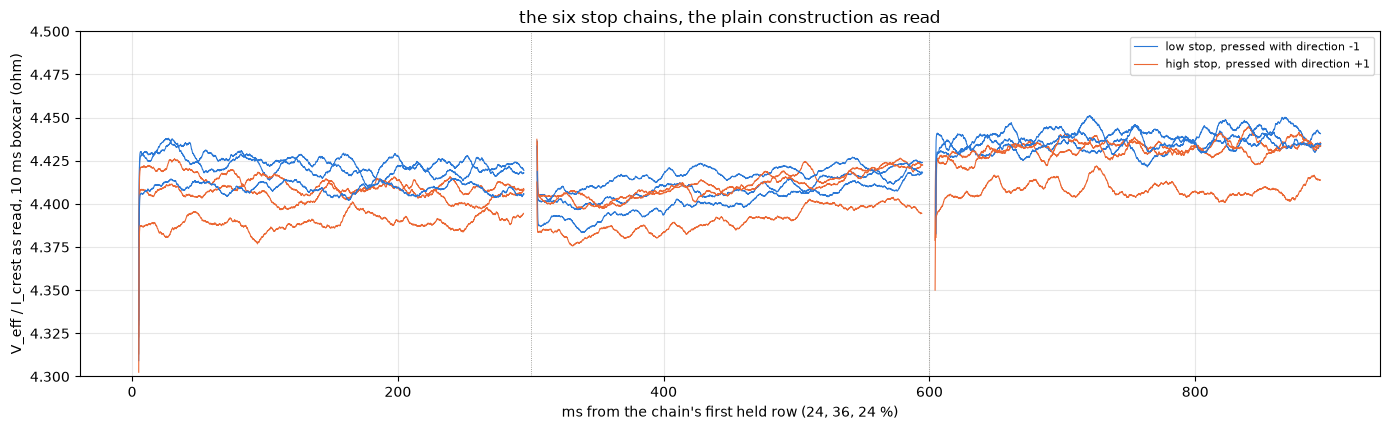

In [41]:
fig, ax = plt.subplots(figsize=(14, 4.4))
for k, g in T.groupby("chain"):
    stop = g["stop"].iloc[0]
    offset = 0.0                        # s, where this step starts
    for step in (1, 2, 3):
        s = STOP_TRACES[(k, step)]
        keep, ratio = smooth_ratio(s["volts"], s["amps"])
        named = step == 1 and k < 2     # one legend entry a stop
        ax.plot((s["t"][keep] + offset) * 1e3, ratio, lw=0.8,
                color=STOP_COLOR[stop],
                label=(f"{stop} stop, pressed with direction "
                       f"{int(g['dir'].iloc[0]):+d}" if named else None))
        offset += s["t"][-1] + 1 / FS
for x in (300, 600):
    ax.axvline(x, **figures.EDGE_STYLE)     # the steps' boundaries
ax.set_ylim(4.3, 4.5)
ax.legend(fontsize=8)
figures.label(ax, x="ms from the chain's first held row (24, 36, 24 %)",
              y="V_eff / I_crest as read, 10 ms boxcar (ohm)",
              title="the six stop chains, the plain construction as read")
figures.finish(fig)

Each step runs flat, and the six chains sit within about 1 % of each other. Step 3 reads 0.26 to 0.62 % over step 1 in each chain, the chain's warmth held in the copper, which the two-point line cancels by averaging the two 24 % steps against the 36 % one.

### The two-level lines

Each chain's line through its two levels, from the settled and the first-row reads, with the least squares line through its three steps beside it.

In [42]:
LINES = pd.concat([chain_lines(T, "i_first_a", "v_first_v", "first row"),
                   chain_lines(T, "i_settled_a", "v_eff_settled_v",
                               "settled")], ignore_index=True)
SET = LINES[LINES["read"] == "settled"]         # the stop read
FIRST = LINES[LINES["read"] == "first row"]
show(LINES[["read", "chain", "stop", "r_bracket_ohm", "v0_bracket_v",
            "r_ls_ohm", "v0_ls_v", "rms_mv", "step3_over_step1_pct",
            "lever_per_a"]].round(4), n=None)
R_STOP, R_STOP_SD = SET["r_bracket_ohm"].mean(), SET["r_bracket_ohm"].std()
V0_STOP, V0_STOP_SD = SET["v0_bracket_v"].mean(), SET["v0_bracket_v"].std()
POOLED = laps.line(T["i_settled_a"], T["v_eff_settled_v"])   # the check
BY_STOP = SET.groupby("stop")[["r_bracket_ohm", "v0_bracket_v"]].mean()
print(f"stop read, settled, 6 chains: R {R_STOP:.4f} sd {R_STOP_SD:.4f}, "
      f"V0 {V0_STOP:+.4f} sd {V0_STOP_SD:.4f}; first row R "
      f"{FIRST['r_bracket_ohm'].mean():.4f}, V0 "
      f"{FIRST['v0_bracket_v'].mean():+.4f}")
print(f"pooled least squares through {POOLED['n']} points: R "
      f"{POOLED['slope']:.4f} +/- {POOLED['slope_se']:.4f}, V0 "
      f"{POOLED['intercept']:+.4f} +/- {POOLED['intercept_se']:.4f}, rms "
      f"{POOLED['rms'] * 1e3:.1f} mV")
print("by stop: " + ", ".join(f"{s} R {r['r_bracket_ohm']:.4f} V0 "
                              f"{r['v0_bracket_v']:+.4f}"
                              for s, r in BY_STOP.iterrows()))
print(f"step 3 over step 1: {SET['step3_over_step1_pct'].min():.2f} to "
      f"{SET['step3_over_step1_pct'].max():.2f} %")

,read,chain,stop,r_bracket_ohm,v0_bracket_v,r_ls_ohm,v0_ls_v,rms_mv,step3_over_step1_pct,lever_per_a
0,first row,0,low,4.340,0.022,4.340,0.022,0.461,0.102,1.258
1,first row,1,high,4.346,0.020,4.346,0.020,1.527,0.332,1.252
2,first row,2,low,4.371,0.017,4.371,0.017,1.725,0.376,1.253
3,first row,3,high,4.350,0.018,4.349,0.018,2.786,0.606,1.249
4,first row,4,low,4.316,0.028,4.316,0.028,2.621,0.574,1.259
5,first row,5,high,4.333,0.017,4.333,0.017,2.772,0.602,1.244
6,settled,0,low,4.367,0.016,4.367,0.016,1.207,0.262,1.253
7,settled,1,high,4.394,0.007,4.394,0.007,2.564,0.552,1.242
8,settled,2,low,4.388,0.011,4.388,0.011,1.579,0.341,1.248
9,settled,3,high,4.386,0.009,4.386,0.009,2.217,0.478,1.244


stop read, settled, 6 chains: R 4.3774 sd 0.0146, V0 +0.0111 sd 0.0047; first row R 4.3428, V0 +0.0202
pooled least squares through 18 points: R 4.3765 +/- 0.0154, V0 +0.0114 +/- 0.0047, rms 3.6 mV
by stop: high R 4.3845 V0 +0.0075, low R 4.3703 V0 +0.0148
step 3 over step 1: 0.26 to 0.62 %


Over the six chains, settled, the stop read is $R$ = 4.3774 ohm sd 0.0146 and $V_0$ = +0.0111 V sd 0.0047. The pooled least squares through all eighteen points agrees, 4.3765 +/- 0.0154 ohm and +0.0114 +/- 0.0047 V with 3.6 mV rms. The first-row read gives 4.3428 ohm and +0.0202 V, 0.8 % lower in $R$, a method systematic of that size on chained steps. The low stop reads 4.3703 ohm and +0.0148 V, the high stop 4.3845 ohm and +0.0075 V, 0.3 % apart and inside the chains' sd. The direction is confounded with the stop here, -1 always at the low stop, so neither the seat nor the direction separates. The stop route's lever is large, $1/I$ moves 1.246 per A between the levels, so 0.1 % of $V/I$ is 3.5 mV of $V_0$.

### The seats

On the left, the lock's seat through the locked laps, the probes before and after each sweep, the sweep's own baseline and the TEL `pos` through each lap, its median with the range. On the right, the stop seats per step on a symmetric log scale, with the free ends written in the servo dotted. The thing to see is how far each seat moves under a lap.

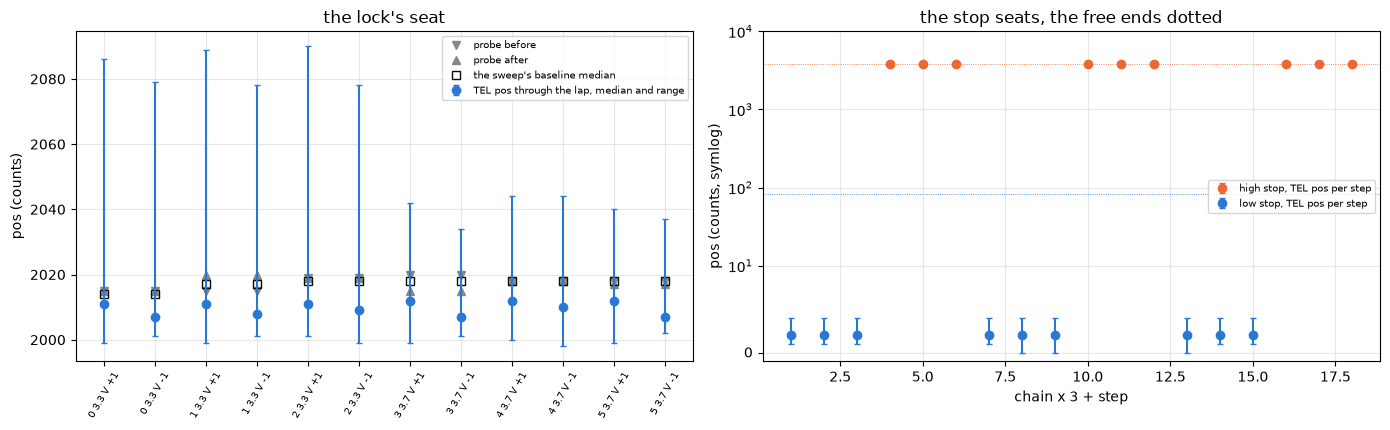

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
lap = np.arange(len(L))
ax[0].plot(lap, L["pos_before"], "v", color=MUTED, label="probe before")
ax[0].plot(lap, L["pos_after"], "^", color=MUTED, label="probe after")
ax[0].plot(lap, L["pos_rest"], "s", color=INK, mfc="none",
           label="the sweep's baseline median")
ax[0].errorbar(lap, L["pos_median"], yerr=[L["pos_median"] - L["pos_min"],
                                           L["pos_max"] - L["pos_median"]],
               fmt="o", color=BLUE, capsize=2,
               label="TEL pos through the lap, median and range")
ax[0].set_xticks(lap, [f"{c} {v:g} V {d:+d}" for c, v, d in
                       zip(L["chain"], L["volts_set"], L["dir"])],
                 rotation=60, fontsize=7)
figures.label(ax[0], y="pos (counts)", title="the lock's seat")
for stop, g in T.groupby("stop"):
    x = g["chain"] * 3 + g["step"]      # one slot per step
    ax[1].errorbar(x, g["pos_median"],
                   yerr=[g["pos_median"] - g["pos_min"],
                         g["pos_max"] - g["pos_median"]], fmt="o",
                   color=STOP_COLOR[stop], capsize=2,
                   label=f"{stop} stop, TEL pos per step")
for end, stop in zip(SERVO_ENDS, ("low", "high")):
    ax[1].axhline(end, color=STOP_COLOR[stop], lw=0.6, ls=":")
ax[1].set_yscale("symlog", linthresh=10)
ax[1].set_ylim(-1, 1e4)                 # counts, both ends in view
figures.label(ax[1], x="chain x 3 + step", y="pos (counts, symlog)",
              title="the stop seats, the free ends dotted")
for a in ax:
    a.legend(fontsize=7)
figures.finish(fig)

In [44]:
shift = L.drop_duplicates("chain")["pos_lap_shift"]
print(f"lock: seats.csv {SEATS_LOCKED['pos'].min()} to "
      f"{SEATS_LOCKED['pos'].max()} (median {SEATS_LOCKED['pos'].median():.0f})"
      f", shift per sweep {shift.abs().min():.0f} to {shift.abs().max():.0f}"
      f" counts; baseline {L['pos_rest'].min():.0f} to "
      f"{L['pos_rest'].max():.0f}; TEL median under the lap " + ", ".join(
          f"{d:+d} {g['pos_median'].min():.0f} to {g['pos_median'].max():.0f}"
          for d, g in L.groupby("dir")))
for stop, g in T.groupby("stop"):
    print(f"{stop} stop: TEL pos median {g['pos_median'].median():.0f} "
          f"({g['pos_min'].min():.0f} to {g['pos_max'].max():.0f} row to "
          f"row); the runner's seats "
          f"{sorted(g['seat_pos_runner'].unique().tolist())}")
print("stop seats.csv shifts:", SEATS_STOP["shift_counts"].tolist(),
      f"| board NTC {T['board_c'].min():.2f} to {T['board_c'].max():.2f} C")

lock: seats.csv 2015 to 2020 (median 2018), shift per sweep 0 to 5 counts; baseline 2014 to 2018; TEL median under the lap -1 2007 to 2010, +1 2011 to 2012
high stop: TEL pos median 3807 (3795 to 3817 row to row); the runner's seats [3806.0, 3807.0, 3808.0]
low stop: TEL pos median 2 (0 to 4 row to row); the runner's seats [2.0]
stop seats.csv shifts: [0, 0, 0, 1, 0, 2] | board NTC 26.00 to 26.04 C


At the lock the seat read 2015 to 2020 through the six sweeps, 0 to 5 counts per sweep, under the runner's 10 count rule. The sweeps' own baselines read 2014 to 2018, and the TEL median under a lap 2011 to 2012 in direction +1 and 2007 to 2010 in -1. That is the lock's give under 0.75 A, a few counts with the direction, about 0.25 degrees at the horn. The lock does not slip.

At the low stop the pot reads 0 to 4 through every step, on its ADC rail and about 80 counts past the free end at 82, so the seat there is blind. At the high stop it reads 3807 in the median, 3795 to 3817 row to row, 15 counts past the free end at 3792, and the runner's seats moved 0, 1 and 2 counts over the three chains. Both stoppers flex under the press, and both stops held the rotor through the chains, which the quiet current traces say where the pot does not. The board NTC read 26.00 to 26.04 C through the stop chains.

## The user's pass against the locked read

The stop read graded against $R_\mathrm{term}$, with the systematics the earlier notebooks carry, the window scale $k$ and the inductance notebook's crest bound.

In [45]:
I24 = T[T["step"] != 2]["i_settled_a"].mean()     # A, the 24 % level
I36 = T[T["step"] == 2]["i_settled_a"].mean()     # A, the 36 % level
V24 = T[T["step"] != 2]["v_eff_settled_v"].mean()
V36 = T[T["step"] == 2]["v_eff_settled_v"].mean()
STOP_LEVER = 1 / I24 - 1 / I36          # per A, between the two levels


def shifted(d24_ma, d36_ma):
    # the pooled two-level line with a crest over-read taken off each
    # level's current, mA
    i_lo, i_hi = I24 - d24_ma * 1e-3, I36 - d36_ma * 1e-3
    r = (V36 - V24) / (i_hi - i_lo)
    return r, V24 - r * i_lo


R_CREST_V, V0_CREST_V = shifted(CREST[24][0], CREST[36][0])   # value
R_CREST_B, V0_CREST_B = shifted(CREST[24][1], CREST[36][1])   # +2 sigma
PRED_AT_LOCK = R_STOP + V0_STOP / I_TERM    # ohm, V/I at 0.767 A
print(f"lever {STOP_LEVER:.3f} per A: 0.1 % of V/I moves V0 by "
      f"{0.001 * R_STOP / STOP_LEVER * 1e3:.1f} mV")
print(f"over k: R {R_STOP / K:.4f} ({R_STOP / K_HI:.4f} to "
      f"{R_STOP / K_LO:.4f}), V0 {V0_STOP / K:+.4f}")
print(f"the inductance crest bound: value R {R_CREST_V:.4f} V0 "
      f"{V0_CREST_V:+.4f}; +2 sigma R {R_CREST_B:.4f} V0 {V0_CREST_B:+.4f}"
      f" ({(R_CREST_B / R_STOP - 1) * 100:+.2f} %, "
      f"{(V0_CREST_B - V0_STOP) * 1e3:+.0f} mV)")
print(f"grade: stop R {(R_STOP / R_TERM - 1) * 100:+.2f} % on R_term; the "
      f"stop line's V/I at {I_TERM:.3f} A {PRED_AT_LOCK:.4f}, "
      f"{(PRED_AT_LOCK / R_TERM - 1) * 100:+.2f} % on it")

lever 1.246 per A: 0.1 % of V/I moves V0 by 3.5 mV
over k: R 4.3499 (4.3422 to 4.3576), V0 +0.0111
the inductance crest bound: value R 4.3688 V0 +0.0201; +2 sigma R 4.3469 V0 +0.0430 (-0.70 %, +32 mV)
grade: stop R +3.76 % on R_term; the stop line's V/I at 0.767 A 4.3920, +4.10 % on it


With the plain construction as read, the user's pass gives $R$ 3.76 % over $R_\mathrm{term}$, and the stop line's $V/I$ at the locked current, 4.3920 ohm, sits 4.10 % over it. Over the window scale $k$ the stop $R$ is 4.3499 ohm, still 3.1 % over. The inductance notebook's crest-to-mean bound, its recommended systematic, moves $R$ by -0.70 % and $V_0$ by +32 mV at its +2 sigma, to 4.3469 ohm and +0.0430 V, and at its value to 4.3688 ohm and +0.0201 V. None of these brings the stop read to the lock. The stop's lever fixes $V_0$ near zero, so a $V_0$ does not close the 4 % either. The user's pass with the plain construction does not reproduce the locked read, with high confidence.

## The three reads under one line

Three reads of this motor's resistance exist on this board. The locked 100 % laps give 3.234 V at 0.767 A, with nothing switching and no construction. The stop chains give two levels on one rail, as read 1.146 V at 0.259 A and 1.689 V at 0.383 A. The sag notebook's stop laps, quoted, give 4.344 ohm at 0.330 A at 1.5 V effective on thirteen rails, one seat at the low stop, about three hours into sitting 1, flat with the rail. The question is whether one line $V = V_0 + R\,I$ fits all three, and under which construction of the partial-duty reads.

The constructions are the as-read one, each stage 1 board term alone, both together, both with the edge lags and the loop at stage 1's bounds, and both with the type's crest term at its locked and spinning $G$. For each, the stop steps are rebuilt and each chain's two-point line read again. The sag laps' as-read $V/I$ is moved by the same construction at the duty the plan commanded on each rail, round(150 / rail) %, with $V_\mathrm{on}$ the rail less the sag notebook's 282 mV. The slope a construction predicts for the sag laps is the as-read slope a flat true $R$ would show under it.

In [46]:
RAILS_SAG = np.arange(8.4, 5.99, -0.2)          # V, the sag's 13 rails
DUTY_SAG = np.round(150 / RAILS_SAG) / 100      # the plan's 1.5 V duty
VON_SAG = RAILS_SAG - VON_GAP                   # V, their crest V_on
VEFF_SAG = DUTY_SAG * VON_SAG                   # V, as the sag read them
V_LOCK = R_TERM * I_TERM                        # V, the locked point
EB = {"edge_ticks": EDGE, "loop_ohm": LOOP["value"]}    # both board terms
VARIANTS = {
    "as read": {},
    "edge lags only": {"edge_ticks": EDGE},
    "brake drop only": {"loop_ohm": LOOP["value"]},
    "edge + brake": EB,
    "edge + brake, lags low": {**EB, "edge_ticks": EDGE_LO},
    "edge + brake, lags high": {**EB, "edge_ticks": EDGE_HI},
    "edge + brake, loop lo": {**EB, "loop_ohm": LOOP["lo"]},
    "edge + brake, loop hi": {**EB, "loop_ohm": LOOP["hi"]},
    "edge + brake + G locked": {**EB, "g_s": G_LOCKED},
    "edge + brake + G spinning": {**EB, "g_s": G_SPIN},
}
print(f"the locked point {V_LOCK:.4f} V at {I_TERM:.4f} A")
print(f"sag rails {RAILS_SAG[0]:.1f} to {RAILS_SAG[-1]:.1f} V at "
      f"{DUTY_SAG.min() * 100:.0f} to {DUTY_SAG.max() * 100:.0f} %; "
      f"{len(VARIANTS)} constructions")

the locked point 3.2344 V at 0.7666 A
sag rails 8.4 to 6.0 V at 18 to 25 %; 10 constructions


In [47]:
def stop_under(kw):
    # the stop steps' volts and current under one construction, and each
    # chain's two-point line through them
    v, i = construct(T["duty_pct"].to_numpy() / 100,
                     T["v_on_settled_v"].to_numpy(),
                     T["i_settled_a"].to_numpy(), **kw)
    s = T.assign(v_c=v, i_c=i)
    lines = []
    for k, g in s.groupby("chain"):
        low, high = g[g["step"] != 2], g[g["step"] == 2].iloc[0]
        i_lo, v_lo = low["i_c"].mean(), low["v_c"].mean()
        r = (high["v_c"] - v_lo) / (high["i_c"] - i_lo)
        lines.append({"chain": k, "stop": g["stop"].iloc[0], "r": r,
                      "v0": v_lo - r * i_lo, "i_lo": i_lo, "v_lo": v_lo,
                      "i_hi": high["i_c"], "v_hi": high["v_c"]})
    return s, pd.DataFrame(lines)


def sag_under(kw):
    # the sag laps under one construction: each rail's V/I moved from the
    # quoted flat read, the winding current, and the rail slope the terms
    # predict for an as-read V/I over a flat true R
    v_c, i_c = construct(DUTY_SAG, VON_SAG, I_SAG, **kw)
    vi = R_SAG * (v_c / i_c) / (VEFF_SAG / I_SAG)
    as_read = (VEFF_SAG / I_SAG) / (v_c / i_c)
    slope = np.polyfit(RAILS_SAG, as_read * vi.mean(), 1)[0]
    return vi, i_c, slope

In [48]:
def joint_line(s, vi_sag, i_sag):
    # V = V0 + R I through the lock's point, the stop's 18 points and the
    # sag's mean point, equal weights, and through lock and stop alone
    i_all = np.r_[I_TERM, s["i_c"].to_numpy(), i_sag.mean()]
    v_all = np.r_[V_LOCK, s["v_c"].to_numpy(), (vi_sag * i_sag).mean()]
    a = np.c_[np.ones_like(i_all), i_all]       # columns: V0, R
    (v0, r), *_ = np.linalg.lstsq(a, v_all, rcond=None)
    resid = v_all - a @ np.array([v0, r])
    (v0_2, r_2), *_ = np.linalg.lstsq(a[:-1], v_all[:-1], rcond=None)
    resid_2 = v_all[:-1] - a[:-1] @ np.array([v0_2, r_2])
    return {"joint_r": r, "joint_v0": v0,
            "joint_resid_lock_mv": resid[0] * 1e3,
            "joint_resid_stop_rms_mv": np.sqrt(np.mean(resid[1:-1] ** 2))
            * 1e3, "joint_resid_sag_mv": resid[-1] * 1e3,
            "lockstop_r": r_2, "lockstop_v0": v0_2,
            "lockstop_rms_mv": np.sqrt(np.mean(resid_2 ** 2)) * 1e3}

In [49]:
rows, POINTS, CHAIN_LINES = [], {}, {}
for name, kw in VARIANTS.items():
    s, lines = stop_under(kw)
    vi_sag, i_sag, slope = sag_under(kw)
    pred = 0.0 if not kw else slope     # as read predicts no slope
    r, v0 = lines["r"].mean(), lines["v0"].mean()
    rows.append({"variant": name, "r_stop": r, "r_stop_sd": lines["r"].std(),
                 "v0_stop": v0, "v0_stop_sd": lines["v0"].std(),
                 "stop_at_lock_pct": ((r + v0 / I_TERM) / R_TERM - 1) * 100,
                 "sag_over_stop_line_pct": (vi_sag.mean() / (
                     r + v0 / i_sag.mean()) - 1) * 100,
                 "sag_slope_predict": pred,
                 "sag_slope_sigma": (SAG_SLOPE["value"] - pred)
                 / SAG_SLOPE_SE, **joint_line(s, vi_sag, i_sag)})
    POINTS[name] = (s, vi_sag.mean(), i_sag.mean())
    CHAIN_LINES[name] = lines
V = pd.DataFrame(rows).set_index("variant")
show(V[["r_stop", "v0_stop", "stop_at_lock_pct", "sag_over_stop_line_pct",
        "sag_slope_predict", "sag_slope_sigma"]].round(4).reset_index(),
     n=None)
show(V[["joint_r", "joint_v0", "joint_resid_lock_mv",
        "joint_resid_stop_rms_mv", "joint_resid_sag_mv", "lockstop_r",
        "lockstop_v0", "lockstop_rms_mv"]].round(4).reset_index(), n=None)

,variant,r_stop,v0_stop,stop_at_lock_pct,sag_over_stop_line_pct,sag_slope_predict,sag_slope_sigma
0,as read,4.377,0.011,4.103,-1.522,0.000,-0.778
1,edge lags only,4.385,-0.042,2.649,-3.221,0.032,-5.278
2,brake drop only,4.261,-0.018,0.435,-2.375,0.007,-1.771
3,edge + brake,4.265,-0.070,-1.095,-4.195,0.041,-6.602
4,"edge + brake, lags low",4.260,-0.010,0.675,-2.101,0.002,-1.060
5,"edge + brake, lags high",4.269,-0.125,-2.684,-6.240,0.081,-12.257
6,"edge + brake, loop lo",4.272,-0.069,-0.852,-4.129,0.041,-6.511
7,"edge + brake, loop hi",4.249,-0.074,-1.570,-4.326,0.043,-6.782
8,edge + brake + G locked,4.206,-0.015,-0.767,-2.385,0.005,-1.490
9,edge + brake + G spinning,4.187,0.003,-0.656,-1.760,-0.008,0.361


,variant,joint_r,joint_v0,joint_resid_lock_mv,joint_resid_stop_rms_mv,joint_resid_sag_mv,lockstop_r,lockstop_v0,lockstop_rms_mv
0,as read,4.158,0.075,-27.996,13.478,-13.372,4.158,0.076,14.589
1,edge lags only,4.242,-0.002,-16.244,9.517,-38.083,4.243,0.000,9.781
2,brake drop only,4.236,-0.012,-1.102,4.303,-30.530,4.237,-0.011,3.875
3,edge + brake,4.322,-0.090,11.193,5.593,-55.383,4.323,-0.088,5.264
4,"edge + brake, lags low",4.223,-0.000,-3.030,4.549,-26.632,4.223,0.001,4.257
5,"edge + brake, lags high",4.411,-0.171,23.970,9.661,-81.210,4.412,-0.167,10.018
6,"edge + brake, loop lo",4.317,-0.085,9.412,5.180,-54.259,4.318,-0.082,4.681
7,"edge + brake, loop hi",4.332,-0.101,14.676,6.579,-57.579,4.333,-0.099,6.568
8,edge + brake + G locked,4.247,-0.028,7.062,4.582,-31.056,4.247,-0.027,4.455
9,edge + brake + G spinning,4.221,-0.007,5.783,4.297,-22.889,4.221,-0.006,4.219


As read there is no single line. The stop line predicts the lock's $V/I$ 4.1 % high, and a joint line through all three reads leaves the lock 28 mV under it, the stop points 13 mV rms off and the sag point 13 mV under. A $V_0$ does not do it, since the stop levels fix $V_0$ at +0.011 V. A constant crest offset does not either, since it moves the stop line's intercept and not the 3.8 % gap in its slope. Temperature does not, at 26.0 C at the stops and 26.3 C at the lock.

With both board terms at stage 1's values the stop chains read $R$ = 4.2647 ohm sd 0.0149 and $V_0$ = -0.0705 V, and the stop line lands 1.09 % under the lock's $V/I$. Lock and stop then fit one line, 4.323 ohm and -0.088 V with 5.3 mV rms. The sag laps sit 4.2 % under that line, and their flat rail slope is 6.6 sigma from the +0.041 ohm per volt the two terms predict. The board terms depend on the rail. At a fixed 1.5 V effective the duty falls from 25 to 18 % across the sag's rails, the edge term grows as $1/D$ and the brake term as $1 - D$, so a flat true $R$ would read +0.041 ohm per volt as read, where the sag laps measured -0.0055 +/- 0.0071. Adding the type's crest term at its spinning $G$ brings the predicted slope to -0.008, 0.4 sigma, and then the lock, the eighteen stop points and the sag's mean fit one line, $R$ = 4.221 ohm and $V_0$ = -0.007 V. The lock sits 6 mV off it, the stop points 4 mV rms and the sag point 23 mV under, 1.8 %, from one seat and one commutator angle, inside the type's angle spread and not a finding.

With the edge lags at the bounds' low end, -4 ticks, the brake term and no crest term, the stop chains give $R$ = 4.260 ohm and $V_0$ = -0.010 V, the lock within +0.7 %, a predicted sag slope of +0.002, 1.1 sigma, and the sag laps 2.1 % under the stop line.

### The inductance notebook's second reading, and the crest term the sag slope asks for

With the board terms in, the rail-independent crest offset that would close the stop levels with the lock, and the per-volt crest term that would bring the board terms' predicted sag slope to the measured one.

In [50]:
s_eb, _ = stop_under(EB)               # the stop steps, both terms
i24 = s_eb[s_eb["step"] != 2]["i_c"].mean()
v24 = s_eb[s_eb["step"] != 2]["v_c"].mean()
i36 = s_eb[s_eb["step"] == 2]["i_c"].mean()
v36 = s_eb[s_eb["step"] == 2]["v_c"].mean()
r_two = (v36 - v24) / (i36 - i24)       # ohm, an offset leaves the slope
v0_app = v24 - r_two * i24              # V, = V0 - R x offset
v0_true = V_LOCK - r_two * I_TERM       # V, the lock carries no offset
OFFSET_A = (v0_true - v0_app) / r_two   # A, the offset that closes them
print(f"edge + brake: the stop levels' slope {r_two:.4f} ohm, apparent V0 "
      f"{v0_app:+.4f} V, the lock at that slope {v0_true:+.4f} V, so a "
      f"rail-independent crest offset of {OFFSET_A * 1e3:+.1f} mA closes "
      "lock and stop")
pred_eb = V.loc["edge + brake", "sag_slope_predict"]
pred_g = V.loc["edge + brake + G locked", "sag_slope_predict"]
per_s = (pred_g - pred_eb) / G_LOCKED   # ohm/V per S of the crest term


def g_for(slope):
    # S, the crest term that brings the board terms' slope to `slope`
    return (slope - pred_eb) / per_s


G_NEEDED = g_for(SAG_SLOPE["value"])
G_LO, G_HI = sorted(g_for(SAG_SLOPE["value"] + e * SAG_SLOPE_SE)
                    for e in (-1, 1))   # S, the term falls as the slope rises
print(f"the sag slope under the board terms asks for a crest term of "
      f"{G_NEEDED * 1e3:.2f} mS ({G_LO * 1e3:.2f} to {G_HI * 1e3:.2f} from "
      f"its se); the type's locked {G_LOCKED * 1e3:.2f}, spinning "
      f"{G_SPIN * 1e3:.2f} mS")

edge + brake: the stop levels' slope 4.2647 ohm, apparent V0 -0.0705 V, the lock at that slope -0.0351 V, so a rail-independent crest offset of +8.3 mA closes lock and stop
the sag slope under the board terms asks for a crest term of 3.22 mS (2.73 to 3.71 from its se); the type's locked 2.49, spinning 3.35 mS


The inductance notebook left two readings of the sag slope alive, a held loss term bounded near zero and a crest offset that does not depend on the rail. With the board terms in, an offset of +8.3 mA on the crest current closes the stop levels' slope and intercept with the lock. An offset leaves the sag laps' slope at the board terms' +0.041 ohm per volt, so the sag laps reject it at 6.6 sigma if the board terms stand. At one rail an offset and a per-volt term act alike, so the stop chains alone say nothing about it, and the sag's rails are what separate them. A per-volt crest term of 3.22 mS, 2.73 to 3.71 over the sag slope's standard error, brings the board terms' prediction to the measured slope. That is the size of the type's spinning $G$, 3.35 mS, and above its locked-burst $G$, 2.49 mS.

The stop steps as applied volts against winding current under three constructions, as read in gray, with both board terms in blue and with the spinning crest term added in green, each with the chains' mean line, and the locked laps' point as a star. The thing to see is which line passes through the star.

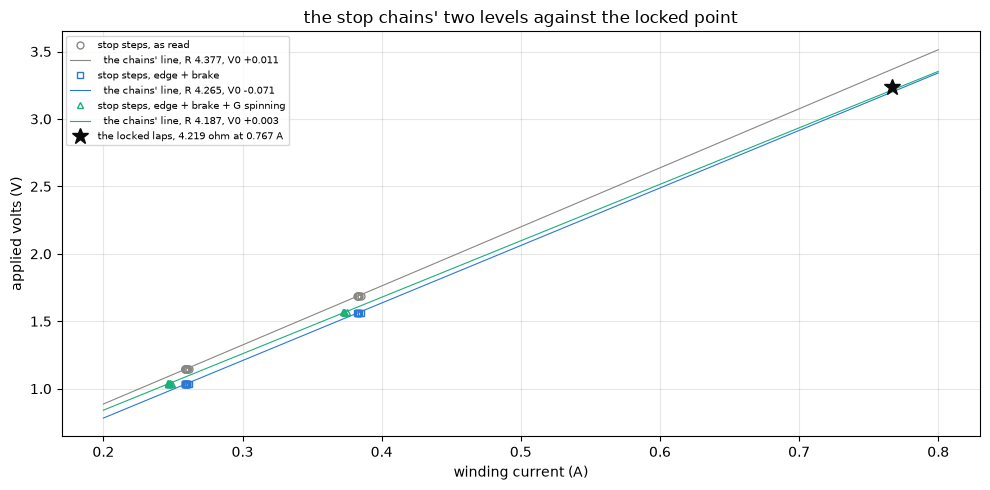

In [51]:
SHOWN = (("as read", MUTED, "o"), ("edge + brake", BLUE, "s"),
         ("edge + brake + G spinning", GREEN, "^"))
fig, ax = plt.subplots(figsize=(10, 5))
amps = np.array([0.2, 0.8])             # A, the lines' span
for name, color, marker in SHOWN:
    s = POINTS[name][0]
    ax.plot(s["i_c"], s["v_c"], marker, ms=5, color=color, mfc="none",
            label=f"stop steps, {name}")
    r, v0 = V.loc[name, "r_stop"], V.loc[name, "v0_stop"]
    ax.plot(amps, v0 + r * amps, color=color, lw=0.8,
            label=f"  the chains' line, R {r:.3f}, V0 {v0:+.3f}")
ax.plot(I_TERM, V_LOCK, "*", ms=12, color=INK,
        label=f"the locked laps, {R_TERM:.3f} ohm at {I_TERM:.3f} A")
ax.legend(fontsize=7)
figures.label(ax, x="winding current (A)", y="applied volts (V)",
              title="the stop chains' two levels against the locked point")
figures.finish(fig)

As read, the stop line passes about 0.13 V over the star at the locked current. With the board terms it passes just under it, 1.1 % in $V/I$, and with the crest term added 0.7 % under it.

Each chain's own line under the as-read construction and with both board terms, from the stop levels out to the locked current, the bracket points circled and colored by stop. The thing to see is how tight the six lines are against their distance from the star.

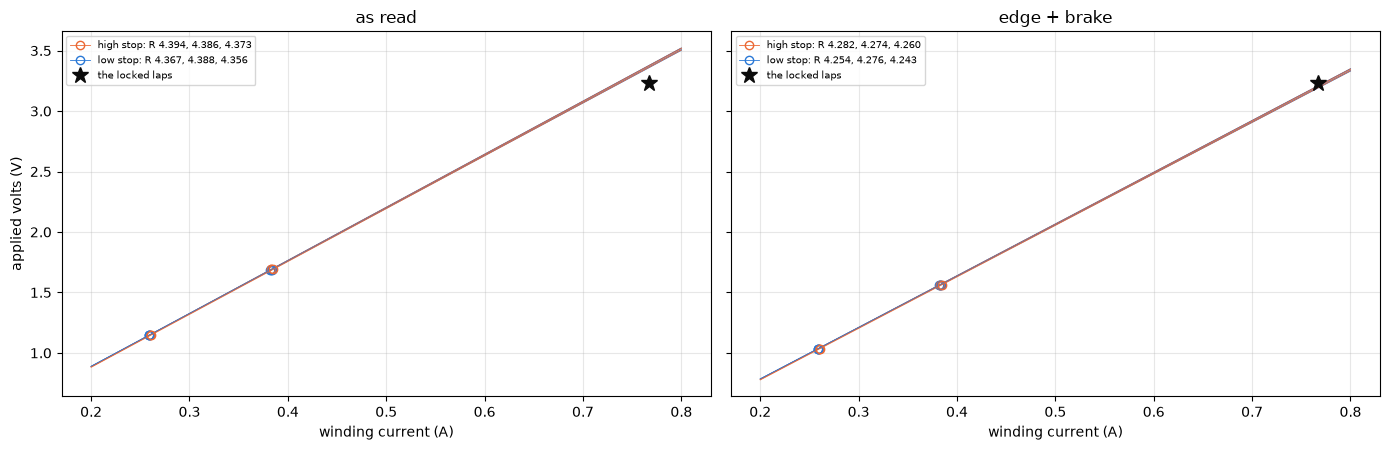

the chains' lines at the locked current, less the lock's volts: as read +123 to +141 mV; edge + brake -46 to -27 mV


In [52]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
span = np.array([0.2, 0.8])             # A, from the stop levels to the lock
for axis, name in zip(ax, ("as read", "edge + brake")):
    for _, c in CHAIN_LINES[name].iterrows():
        color = STOP_COLOR[c["stop"]]
        axis.plot(span, c["v0"] + c["r"] * span, color=color, lw=0.6)
        axis.plot([c["i_lo"], c["i_hi"]], [c["v_lo"], c["v_hi"]], "o",
                  color=color, mfc="none", ms=6)   # the bracket points
    for stop, g in CHAIN_LINES[name].groupby("stop"):
        axis.plot([], [], "o-", mfc="none", lw=0.6, color=STOP_COLOR[stop],
                  label=f"{stop} stop: R " + ", ".join(
                      f"{r:.3f}" for r in g["r"]))
    axis.plot(I_TERM, V_LOCK, "*", ms=12, color=INK,
              label="the locked laps")
    axis.legend(fontsize=7, loc="upper left")
    figures.label(axis, x="winding current (A)", title=name)
figures.label(ax[0], y="applied volts (V)")
figures.finish(fig)
at_lock = {n: (CHAIN_LINES[n]["v0"] + CHAIN_LINES[n]["r"] * I_TERM)
           for n in ("as read", "edge + brake")}
print("the chains' lines at the locked current, less the lock's volts: "
      + "; ".join(f"{n} {(v - V_LOCK).min() * 1e3:+.0f} to "
                  f"{(v - V_LOCK).max() * 1e3:+.0f} mV"
                  for n, v in at_lock.items()))

At the locked current the six as-read lines sit 123 to 141 mV over the lock's volts, and with both board terms 27 to 46 mV under. The chains spread by under 20 mV under either construction, so the gap to the star belongs to the construction and not to a chain.

Every read on one plot of $V/I$ against $1/I$. On this plot a line $V = V_0 + R\,I$ is a straight line with slope $V_0$ and intercept $R$, so the dotted guides through the locked point are the lines with $V_0$ of -0.1, 0 and +0.1 V. The locked laps, the stop steps and the sag point are drawn under three constructions, with the type motors' $R_\mathrm{term}$ as horizontal lines. The thing to see is which construction puts the stop steps and the sag point on one guide with the locked laps.

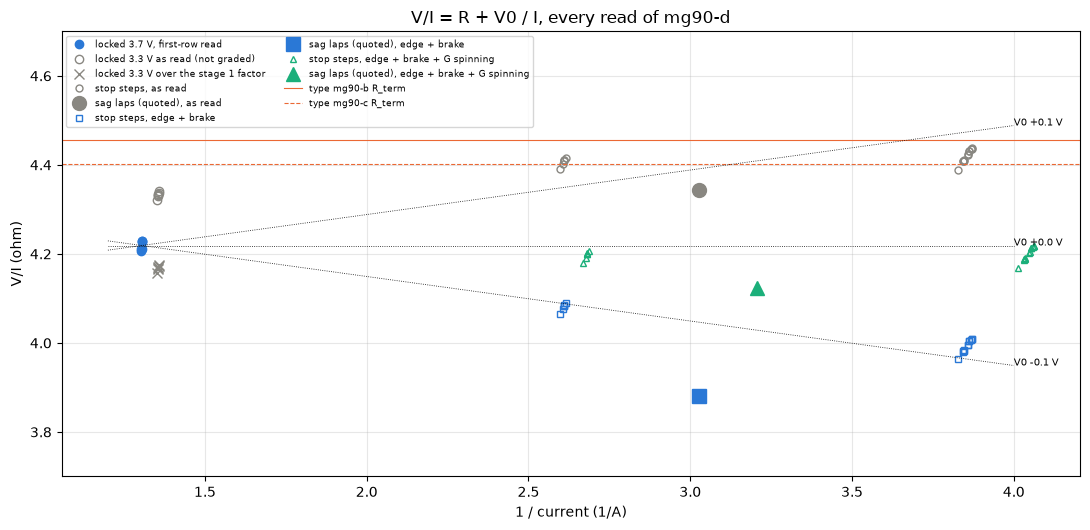

In [53]:
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.plot(1 / G3["i_first_a"], G3["r_first_ohm"], "o", color=BLUE, ms=6,
        label="locked 3.7 V, first-row read")
ax.plot(1 / LOW["i_first_a"], LOW["r_first_ohm"], "o", color=MUTED,
        mfc="none", ms=6, label="locked 3.3 V as read (not graded)")
ax.plot(1 / LOW["i_first_a"], LOW["r_first_ohm"] / F_3V3, "x",
        color=MUTED, ms=7, label="locked 3.3 V over the stage 1 factor")
for name, color, marker in SHOWN:
    s, vi_sag, i_sag = POINTS[name]
    ax.plot(1 / s["i_c"], s["v_c"] / s["i_c"], marker, ms=5, color=color,
            mfc="none", label=f"stop steps, {name}")
    ax.plot(1 / i_sag, vi_sag, marker, ms=10, color=color,
            label=f"sag laps (quoted), {name}")
for key, rr in TYPES.items():
    ax.axhline(rr["r_term_median_ohm"]["value"], color=ORANGE, lw=0.8,
               ls="--" if key == "mg90-c" else "-",
               label=f"type {key} R_term")
inv = np.array([1.2, 4.0])              # 1/A, the guides' span
for v0 in (-0.1, 0.0, 0.1):             # V, guides through the lock
    ax.plot(inv, R_TERM + v0 * (inv - 1 / I_TERM), color=INK, lw=0.6,
            ls=":")
    ax.annotate(f"V0 {v0:+.1f} V", (inv[1], R_TERM + v0 * (inv[1]
                                   - 1 / I_TERM)), fontsize=7)
ax.set_ylim(3.7, 4.7)
ax.legend(fontsize=6.5, ncol=2, loc="upper left")
figures.label(ax, x="1 / current (1/A)", y="V/I (ohm)",
              title="V/I = R + V0 / I, every read of mg90-d")
figures.finish(fig)

As read the stop steps sit near 4.41 ohm, over the 3.3 V locked laps and over every guide through the lock, and the sag point sits under the stop steps. With both board terms the stop steps drop to about the -0.1 V guide and the sag point falls well under it. With the spinning crest term added the stop steps and the sag point sit close to the 0 V guide through the lock, the joint line above. The type motors' lines sit 4 to 5 % over mg90-d's 3.7 V locked laps.

For each construction, on the left, the stop line's $V/I$ at the locked current over the lock and the sag laps over the stop line, in percent, and on the right the rail slope the construction predicts for a flat true $R$ against the sag laps' measured slope with its standard error shaded. The thing to see is which constructions keep the three reads within a percent or two and the slope inside the band.

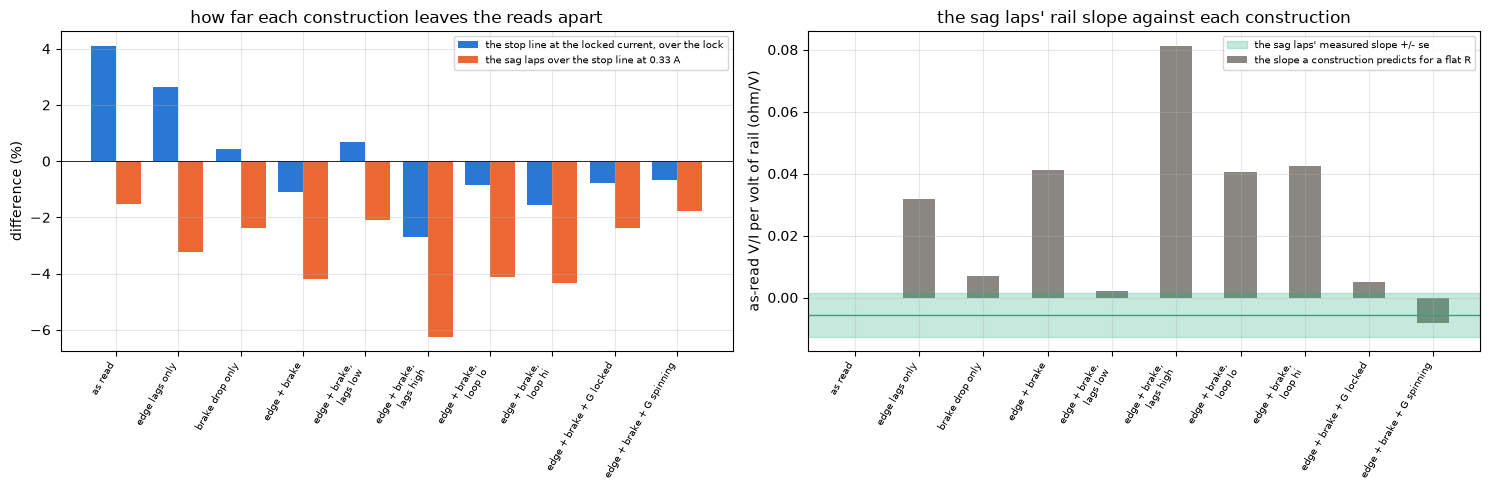

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(V))
names = [n.replace(", ", ",\n") for n in V.index]
ax[0].bar(x - 0.2, V["stop_at_lock_pct"], 0.4, color=BLUE,
          label="the stop line at the locked current, over the lock")
ax[0].bar(x + 0.2, V["sag_over_stop_line_pct"], 0.4, color=ORANGE,
          label="the sag laps over the stop line at 0.33 A")
ax[0].axhline(0, color=INK, lw=0.6)
ax[0].legend(fontsize=7)
figures.label(ax[0], y="difference (%)",
              title="how far each construction leaves the reads apart")
ax[1].bar(x, V["sag_slope_predict"], 0.5, color=MUTED,
          label="the slope a construction predicts for a flat R")
ax[1].axhspan(SAG_SLOPE["lo"], SAG_SLOPE["hi"], color=GREEN, alpha=0.25,
              label="the sag laps' measured slope +/- se")
ax[1].axhline(SAG_SLOPE["value"], color=GREEN, lw=1)
ax[1].legend(fontsize=7)
figures.label(ax[1], y="as-read V/I per volt of rail (ohm/V)",
              title="the sag laps' rail slope against each construction")
for a in ax:
    a.set_xticks(x, names, rotation=60, ha="right", fontsize=7)
figures.finish(fig)

Four constructions keep the predicted sag slope within 2 sigma of the measurement and the stop line within 1 % of the lock. They are the brake drop alone, both terms with the edge lags at their low bound, and both terms with either of the type's crest terms. The brake drop alone is the edge lags at zero ticks, inside the second reading below. Both board terms at stage 1's values with no crest term put the stop line within 1.1 % of the lock and the slope 6.6 sigma off.

### Stage 1's check of the construction

The same constructions on stage 1's own data, quoted as a check of the construction and not of the motor. Bridge-states ran slow-decay rungs at 25 and 40 % into the RL dummy, a resistor and an inductor with no brushes, in three inductive wirings and both directions, with each wiring's DC resistance from its own 100 % rungs. A construction that leaves nothing out reads that DC resistance. The stage 1 notebook should own this number if it is quoted. Its result file does not carry it, and its `window_r_ohm` and `window_scale` are the burst estimator's, which already carries both terms.

In [55]:
DUMMY = PAIR_DIR.parent / BOARD_KEY / "bridge-states" / "capture-1"
rows = []
for w in ("ra", "rab", "rb"):           # the RL dummy's inductive wirings
    dc = BRIDGE["dc_r_ohm"][w]["value"] # ohm, its own 100 % read
    df, _ = tel.load(DUMMY / w / "sweep-slow", BOARD)
    zero_i, _ = tel.rest_zeros(df)
    for seg, g in df[df["seg"] > 0].groupby("seg"):
        gh, held, _ = held_rows(g)
        d = int(gh["dir"].iloc[0])
        on = np.arange(len(gh)) / FS >= DUMMY_FROM_S    # settled rows
        i = SCALES.amps(gh["current_raw"].to_numpy(float), zero_i)[on].mean()
        taps = ((gh["vmotor_a"] - gh["vmotor_b"]) * d).to_numpy(float)
        v_on = SCALES.volts(taps, TAP_OFFSET)[on].mean()
        duty = abs(held) / ARR
        d_edge = (2 * abs(held) - EDGE) / (2 * ARR)     # D prime
        v = {"plain": duty * v_on, "edge": d_edge * v_on,
             "brake": duty * v_on - (1 - duty) * LOOP["value"] * i,
             "both": d_edge * v_on - (1 - d_edge) * LOOP["value"] * i}
        rows.append({"wiring": w, "dir": d, "duty_pct": duty * 100,
                     **{f"{n}_pct": (u / i / dc - 1) * 100
                        for n, u in v.items()}})
DUM = pd.DataFrame(rows)
DUM = DUM[DUM["duty_pct"] < 100]        # the 100 % rungs are the DC R
COLS = ["plain_pct", "edge_pct", "brake_pct", "both_pct"]
show(DUM.groupby("duty_pct")[COLS].agg(["min", "max"]).round(2)
     .reset_index(), n=None)

duty_pct plain_pct       edge_pct       brake_pct       both_pct       
                 min   max      min   max       min   max      min    max
0   25.000     8.300 8.830    3.700 4.200     3.980 4.510   -0.680 -0.180
1   40.000     5.080 5.470    2.290 2.670     1.630 2.100   -1.230 -0.770

On the RL dummy the plain construction reads 8.30 to 8.83 % over the DC resistance at 25 % and 5.08 to 5.47 % at 40 %. The edge lags alone leave 3.70 to 4.20 and 2.29 to 2.67 %, the brake drop alone 3.98 to 4.51 and 1.63 to 2.10 %, and both together -0.18 to -0.68 and -0.77 to -1.23 %. On a load with no brushes the two board terms account for the plain construction's excess to within about 1 %. That is stage 1's check to own, and nothing here is derived from it.

Each rung of the dummy as $V/I$ over its wiring's DC resistance under the four constructions, against the duty. The thing to see is where each construction lands against zero.

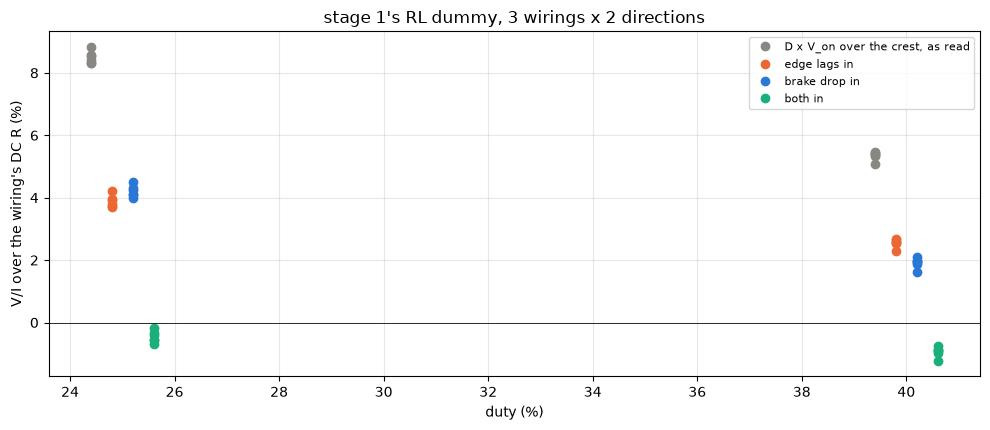

In [56]:
fig, ax = plt.subplots(figsize=(10, 4.4))
nudge = {"plain_pct": -0.6, "edge_pct": -0.2, "brake_pct": 0.2,
         "both_pct": 0.6}               # % of duty, so the dots part
names = {"plain_pct": "D x V_on over the crest, as read",
         "edge_pct": "edge lags in", "brake_pct": "brake drop in",
         "both_pct": "both in"}
for col, color in zip(COLS, (MUTED, ORANGE, BLUE, GREEN)):
    ax.plot(DUM["duty_pct"] + nudge[col], DUM[col], "o", ms=6,
            color=color, label=names[col])
ax.axhline(0, color=INK, lw=0.6)
ax.legend(fontsize=8)
figures.label(ax, x="duty (%)", y="V/I over the wiring's DC R (%)",
              title="stage 1's RL dummy, 3 wirings x 2 directions")
figures.finish(fig)

### Two readings

As read, the three reads have no common line. With stage 1's two board terms at their stated values the stop chains come within about 1 % of the lock, but the sag slope sits 6.6 sigma off. Two readings of the partial-duty reads stand.

1. Leading, moderate. The partial-duty reads carry the two stage 1 board terms and a crest over-read of about 3.2 mS per volt of $(1 - D)\,V_\mathrm{on}$, the size of the type's spinning $G$. The motor's line is then $R$ = 4.19 to 4.22 ohm and $V_0$ = -0.01 to 0.00 V, and the user's pass with the three terms reproduces the locked read within 1 %. The chains on three rails below confirm this reading's crest term and place it at 3.0 to 4.0 mS with edge lags of 11 to 19 ticks, under stage 1's 25, with the line at $R$ = 4.17 to 4.19 ohm and $V_0$ = +0.02 to +0.04 V.
2. Alive, low to moderate. The edge lags on the motor at 18 to 36 % are smaller than the bare load's 25.5 ticks, the bounds reaching -4, the brake term stands and no crest term enters. At the low bound the stop chains give $R$ = 4.260 ohm and $V_0$ = -0.010 V, the lock within +0.7 %, the sag slope predicted at +0.002 ohm per volt, 1.1 sigma, and the sag laps 2.1 % under the stop line. The chains on three rails below kill this reading, at $\chi^2$ 156 over 5.

Dead are a constant crest offset as the whole difference, since it leaves the slope mismatch and the sag slope rejects it at 6.6 sigma if the board terms stand, $V_0$ alone, since the stop lever fixes it near zero as read, and temperature, at 26.0 against 26.3 C.

The kill test is the same stop chains at a second rail, 3.7 V at 32 and 49 % and 7.4 V at 16 and 24 %, at the same two currents. The edge term goes as $1/D$, the brake term as $1 - D$ and the crest term as $(1 - D)\,V_\mathrm{on}$, so four levels on two rails separate the three with no meter. Folding the taps' edges on a burst recording at the stop at 24 and 36 % would test the edge lags on their own, since the TEL rows carry the crest only. Sitting 7 ran the kill test, and the next section reads it.

The first reading reverses the inductance notebook's recommendation. That notebook told the stop chains to take no crest-to-mean correction, from a held-loss bound of 0.42 mS (-0.66 to 1.50) read off the sag laps' slope. Its bound was the same slope read without the board terms. With the board terms the same slope asks for a crest term of about 3.2 mS. So the two notebooks disagree on the crest correction at partial duty, and the next capture, the stop chains at a second rail, decides it. Under the second reading the inductance notebook's recommendation stands. The rails decide it for a crest term, with its size tied to the edge lags along a valley.

These data pin $V_0$ no better than about +/-0.06 V and $R$ no better than 1 % across the constructions. The locked 4.2189 ohm at 0.767 A is the number no construction enters.

## The chains on three rails

The section above ended with a kill test for its two readings, and sitting 7 ran it. The same stop chains ran on a 3.7 V and a 7.4 V rail at the two currents of the 5 V chains, so each current sits on three rails. At one current each term the as-read construction leaves out moves the as-read $V/I$ by a lever of its own. The edge lags go as $1/D$, the brake drop as $1 - D$, and a per-volt crest term $g$ ("g") as $(1 - D)\,V_\mathrm{on} / I$. At a fixed current the rail sets $D$, so six levels on three rails, with the locked laps as the anchor, weigh the three terms against each other from the board's own readings, with no meter.

### Procedure

The `rails` plan of `stages/3-servo/resistance/plan.py` ran in sitting 7, after the open run-up and reference plans. It is the stop plan again at two more rails. On 3.7 V, chains 0 to 5 seek into their stop at 66 % and then drive 32, 49 and 32 % for 300 ms each, chained with no release. On 7.4 V, chains 6 to 11 seek at 33 % and drive 16, 24 and 16 %. Both put about 1.1 and 1.7 V effective on the motor, the 5 V chains' two levels. The even chains drive direction -1 into the low stop and the odd chains +1 into the high stop, so every chain presses into its stop, with 20 s between chains. The 3.7 V block ran first, then the 7.4 V block.

### Data

- `resistance/rails-7/` holds `chains.csv`, `seats.csv` and `chains/<k>/`, laid out as the stop chains' folder above.
- `sittings/servo-7.csv` is the sitting's manifest, with the board NTC probes around every chain and the two rail trims.
- The 5 V chains are the stop chains above, read once and reused here.

The folder's chains and the plan as the data record them.

In [57]:
RAILS7 = PAIR_DIR / "resistance" / "rails-7"   # the 3.7 and 7.4 V chains
RAILS_SITTING = 7                       # the sitting that ran them
board_r, META_RAILS = board_of(RAILS7 / "chains" / "0")   # sense checked
if board_r.key != BOARD.key:            # the same board as the rest
    raise ValueError(f"rails-7 names {board_r.key}, not {BOARD.key}")
CH_RAILS = pd.read_csv(RAILS7 / "chains.csv")      # one row per chain
SEATS_RAILS = pd.read_csv(RAILS7 / "seats.csv")    # the runner's seats
PROBES_RAILS = manifest_probes(RAILS_SITTING)      # the board NTC probes
TRIMS_RAILS = manifest_rails(RAILS_SITTING)        # each rail's trim
t0_rails = manifest(RAILS_SITTING)["t_host"].min() # the sitting's start
show(CH_RAILS, n=None)
for v, g in CH_RAILS.groupby("volts_set"):
    meta = json.loads((RAILS7 / g["folder"].iloc[0] / "meta.json")
                      .read_text())             # the rail's first chain
    print(f"{v:g} V: chains {g['k'].min()} to {g['k'].max()}, "
          f"{meta['schedule']}, seek {meta['seek_duty_pct']} %, stops "
          f"{', '.join(g['stop'])}, board read {g['vsys_read'].iloc[0]:.3f}"
          f" V on DPS {g['dps_read'].iloc[0]:.3f} V")
print(f"from {(CH_RAILS['t_start'].min() - t0_rails) / 60:.1f} to "
      f"{(CH_RAILS['t_end'].max() - t0_rails) / 60:.1f} min into sitting "
      f"{RAILS_SITTING}, rest {META_RAILS['rest_ms'] / 1e3:.0f} s; plans "
      "before: " + ", ".join(plans(RAILS_SITTING)["plan"].iloc[:2]))

,k,volts_set,dps_read,vsys_read,duty_low_pct,duty_high_pct,stop,seat_pos,t_start,t_end,folder
0,0,3.700,3.950,3.692,32,49,rev,2.000,1794099646.698,1794099680.779,chains/0
1,1,3.700,3.950,3.692,32,49,fwd,3810.000,1794099700.791,1794099731.301,chains/1
2,2,3.700,3.950,3.692,32,49,rev,2.000,1794099751.313,1794099781.616,chains/2
3,3,3.700,3.950,3.692,32,49,fwd,3812.000,1794099801.626,1794099831.655,chains/3
4,4,3.700,3.950,3.692,32,49,rev,2.000,1794099851.667,1794099881.935,chains/4
5,5,3.700,3.950,3.692,32,49,fwd,3813.000,1794099901.946,1794099932.338,chains/5
6,6,7.400,7.650,7.425,16,24,rev,2.000,1794099952.349,1794099986.246,chains/6
7,7,7.400,7.650,7.425,16,24,fwd,3817.000,1794100006.257,1794100037.159,chains/7
8,8,7.400,7.650,7.425,16,24,rev,2.000,1794100057.171,1794100087.967,chains/8
9,9,7.400,7.650,7.425,16,24,fwd,3817.000,1794100107.978,1794100140.814,chains/9


3.7 V: chains 0 to 5, ['32@300', 'then:49@300', 'then:32@300'], seek 66 %, stops rev, fwd, rev, fwd, rev, fwd, board read 3.692 V on DPS 3.950 V
7.4 V: chains 6 to 11, ['16@300', 'then:24@300', 'then:16@300'], seek 33 %, stops rev, fwd, rev, fwd, rev, fwd, board read 7.425 V on DPS 7.650 V
from 9.5 to 19.5 min into sitting 7, rest 20 s; plans before: runup (open), ref (open)


The twelve chains ran from 9.5 to 19.5 minutes into sitting 7. The board read 3.692 V on the low rail with the DPS at 3.950 V, and 7.425 V on the high rail with the DPS at 7.650 V. The runner's seats at the high stop walked from 3810 to 3818 over its six chains.

The section above took the edge lags as sample-timing's mean over its two rails. Here the rail is the lever, so the lags enter per rail. Sample-timing measured the tap's ON lag and its OFF lag at 3.7 and 7.4 V, and `Scales.edge_ticks_at` takes their difference on each rail and interpolates it to 5 V. The ladder notebook's two rail terms are quoted beside it for comparison.

In [58]:
# sample-timing's tap ON lag less its OFF lag, measured at 3.7 and 7.4 V,
# interpolated on the rail and held flat outside the two; "lo" and "hi"
# take the widest combination of the two lags' bounds
edge_ticks_at = SCALES.edge_ticks_at
for v in (3.7, 5.0, 7.4):
    print(f"{v:g} V: the window {edge_ticks_at(v):.1f} ticks short "
          f"({edge_ticks_at(v, 'lo'):.0f} to {edge_ticks_at(v, 'hi'):.0f})")
print(f"the two-rail mean the section above used: {EDGE:.1f} ticks; the "
      f"low-side loop {LOOP['value']:.3f} ohm ({LOOP['lo']:.3f} to "
      f"{LOOP['hi']:.3f})")
LADDER = results.read("3-servo", "ladder", pair=PAIR)     # quoted
for form in ("a", "b"):
    t = LADDER[f"rail_term_{form}_g_ms"]
    print(f"the ladder's rail term, form {form.upper()}: {t['value']:.2f} "
          f"mS ({t['lo']:.2f} to {t['hi']:.2f})")

3.7 V: the window 24.0 ticks short (-4 to 46)
5 V: the window 25.1 ticks short (-2 to 48)
7.4 V: the window 27.0 ticks short (2 to 52)
the two-rail mean the section above used: 25.5 ticks; the low-side loop 0.301 ohm (0.281 to 0.339)
the ladder's rail term, form A: 2.58 mS (2.49 to 2.67)
the ladder's rail term, form B: 6.14 mS (6.04 to 6.23)


The window comes up 24.0 ticks short at 3.7 V, 25.1 at 5 V and 27.0 at 7.4 V, with bounds of -4 to 46, -2 to 48 and 2 to 52. The two-rail mean, 25.5 ticks, would put the 7.4 V levels 1.5 ticks off. The low-side loop is bridge-states' 0.301 ohm (0.281 to 0.339), as above. The ladder's rail term reads 2.58 mS in its form A and 6.14 mS in its form B, the form in $(1 - D)\,V_\mathrm{on}$.

### The chains as read

Each step of the rails-7 chains goes through the stop chains' `sweep_steps` above, from its first row at the held duty with settled means from 2 ms. The 5 V steps are the ones read above. The function below also counts the missing rows, the dropout rows and the share of held rows with `window_valid` set, which the reading itself does not check. Per rail and level the table gives the mean over six chains of the settled current, $V_\mathrm{on}$, $V_\mathrm{eff}$ and the as-read $V/I$, with its sd and standard error over the chains and the first-row read beside it.

In [59]:
def rail_chain(c):
    # every step of one rails-7 chain through sweep_steps, with the
    # checks the reading itself does not make: missing rows, dropout
    # rows and window_valid over the held rows of each step
    folder = RAILS7 / c["folder"]
    df, _ = tel.load(folder, BOARD)         # the sweep once more, checked
    zero_i, _ = tel.rest_zeros(df)          # its torque-off zero
    missing = tel.gaps(df)                  # dropped rows per segment
    out = []
    for s in sweep_steps(folder):
        g = df[df["seg"] == s["seg"]].iloc[s["rows_before_held"]:]
        over = g["current_raw"].to_numpy(float) - zero_i   # counts
        valid = g["window_valid"].to_numpy() == 1
        out.append({**s, "missing_rows": int(missing.get(s["seg"], 0)),
                    "dropout_rows": int(tel.dropout_rows(over).sum()),
                    "window_valid_frac": float(valid.mean())})
    return out

In [60]:
rows, RAIL_TRACES = [], {}              # one row per step, signals by key
for _, c in CH_RAILS.iterrows():
    k = int(c["k"])
    board_c, c_lo, c_hi = ntc_around(PROBES_RAILS, c["t_start"],
                                     c["t_end"])
    for s in rail_chain(c):
        RAIL_TRACES[(c["volts_set"], k, s["seg"])] = s.pop("trace")
        rows.append({"rail_v": c["volts_set"], "sitting": RAILS_SITTING,
                     "chain": k,
                     "stop": "low" if c["stop"] == "rev" else "high",
                     "step": s["seg"], "seat_pos_runner": c["seat_pos"],
                     "vsys_read": c["vsys_read"], "board_c": board_c,
                     "board_c_lo": c_lo, "board_c_hi": c_hi,
                     "t_start": c["t_start"], **s})
for (k, step), s in STOP_TRACES.items():     # the 5 V chains, read above
    RAIL_TRACES[(5.0, k, step)] = s
FIVE = (T.merge(CH_STOP[["k", "volts_set", "vsys_read", "t_start"]],
                left_on="chain", right_on="k")   # the 5 V steps above
        .rename(columns={"volts_set": "rail_v"}).assign(sitting=1))
STEPS3 = pd.concat([FIVE, pd.DataFrame(rows)], ignore_index=True)
STEPS3["level"] = np.where(STEPS3["step"] == 2, "high", "low")
for which, col in (("value", "edge_ticks"), ("lo", "edge_lo"),
                   ("hi", "edge_hi")):      # stage 1's lags per rail
    STEPS3[col] = [edge_ticks_at(v, which) for v in STEPS3["rail_v"]]
STEPS3["on_ticks"] = STEPS3["held_ticks"].abs() * 2  # of the 2400 period
STEPS3["rise_pct_per_s"] = (STEPS3["r_slope_ohm_per_s"]
                            / STEPS3["r_first_ohm"] * 100)
STEPS3["settled_over_first_pct"] = (STEPS3["r_settled_ohm"]
                                    / STEPS3["r_first_ohm"] - 1) * 100
STEPS3["von_gap_v"] = STEPS3["vsys_read"] - STEPS3["v_on_settled_v"]
S7 = STEPS3[STEPS3["sitting"] == RAILS_SITTING]     # the rails-7 steps
print(f"{len(S7)} rails-7 steps and {len(FIVE)} 5 V steps")

36 rails-7 steps and 18 5 V steps


In [61]:
rows = []                               # one row per rail and level
for (v, level), g in STEPS3.groupby(["rail_v", "level"]):
    per = g.groupby("chain").agg(       # each chain's mean at the level
        i=("i_settled_a", "mean"), v=("v_eff_settled_v", "mean"),
        von=("v_on_settled_v", "mean"), vi=("r_settled_ohm", "mean"),
        vi_first=("r_first_ohm", "mean"))
    n = len(per)
    rows.append({"rail_v": v, "level": level,
                 "sitting": g["sitting"].iloc[0],
                 "duty": g["duty_pct"].iloc[0] / 100,
                 "on_ticks": g["on_ticks"].iloc[0],
                 "edge_ticks": g["edge_ticks"].iloc[0],
                 "edge_lo": g["edge_lo"].iloc[0],
                 "edge_hi": g["edge_hi"].iloc[0], "n": n,
                 "i": per["i"].mean(), "i_sd": per["i"].std(),
                 "v_on": per["von"].mean(), "v_on_sd": per["von"].std(),
                 "v_eff": per["v"].mean(), "vi": per["vi"].mean(),
                 "vi_sd": per["vi"].std(),
                 "vi_se": per["vi"].std() / np.sqrt(n),
                 "vi_first": per["vi_first"].mean(),
                 "board_c": g["board_c"].mean()})
LEVELS = pd.DataFrame(rows)
LEVELS["inv_d"] = 1 / LEVELS["duty"]                # the edge term's lever
LEVELS["crest_lever"] = ((1 - LEVELS["duty"]) * LEVELS["v_on"]
                         / LEVELS["i"])             # V/A, the crest term's
show(LEVELS.assign(duty_pct=LEVELS["duty"] * 100)[
    ["rail_v", "level", "duty_pct", "on_ticks", "i", "i_sd", "v_on",
     "v_eff", "vi", "vi_sd", "vi_se", "vi_first", "board_c"]].round(4),
     n=None)
print(f"the lock: {R_TERM:.4f} ohm sd {R_TERM_SD:.4f} at {I_TERM:.4f} A, "
      f"V_on {G3['v_on_settled_v'].mean():.3f} V, board "
      f"{G3['board_c'].mean():.2f} C, no construction")

,rail_v,level,duty_pct,on_ticks,i,i_sd,v_on,v_eff,vi,vi_sd,vi_se,vi_first,board_c
0,3.700,high,49.000,1176,0.380,0.002,3.407,1.669,4.399,0.027,0.011,4.389,26.668
1,3.700,low,32.000,768,0.252,0.001,3.486,1.116,4.426,0.025,0.010,4.427,26.668
2,5.000,high,36.000,864,0.383,0.001,4.692,1.689,4.407,0.009,0.004,4.395,26.028
3,5.000,low,24.000,576,0.259,0.001,4.778,1.147,4.420,0.011,0.005,4.421,26.028
4,7.400,high,24.000,576,0.388,0.002,7.080,1.699,4.376,0.029,0.012,4.368,27.041
5,7.400,low,16.000,384,0.264,0.002,7.170,1.147,4.348,0.040,0.016,4.348,27.041


the lock: 4.2189 ohm sd 0.0105 at 0.7666 A, V_on 3.249 V, board 26.30 C, no construction


At about 0.26 A the as-read $V/I$ is 4.4265 ohm at 3.7 V, 4.4204 at 5 V and 4.3485 at 7.4 V. At about 0.38 A it is 4.3995, 4.4065 and 4.3764. From 3.7 to 7.4 V the current rises from 0.252 to 0.264 A at the low level and from 0.380 to 0.388 A at the high level, so each level sits near one current on the three rails. The first-row read sits within 0.012 ohm of the settled read at every level. The shortest ON window is 384 ticks, 16 % on 7.4 V, over the 160-tick floor. The lock reads 4.2189 ohm at 0.7666 A with no construction.

Each chain's as-read $V_\mathrm{eff} / I_\mathrm{crest}$ through its 900 ms, one panel per rail, colored by stop, the steps' boundaries dotted. The thing to see is how flat each step runs and how far apart the chains sit on each rail.

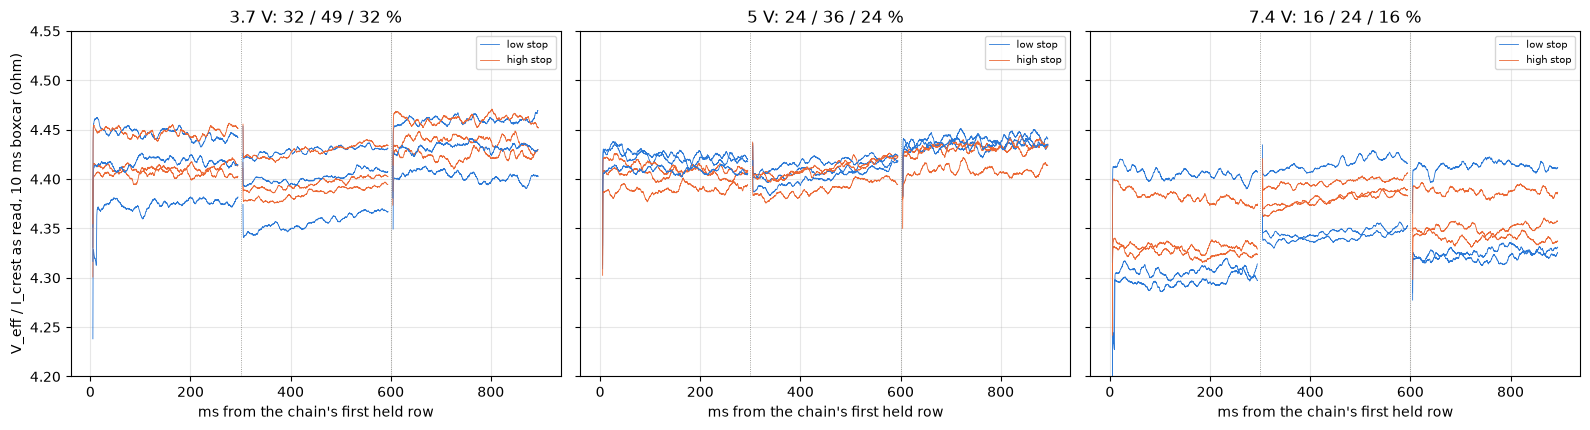

In [62]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for axis, v in zip(ax, (3.7, 5.0, 7.4)):
    g = STEPS3[STEPS3["rail_v"] == v]
    for k, gk in g.groupby("chain"):
        stop = gk["stop"].iloc[0]
        offset = 0.0                    # s, where this step starts
        for step in (1, 2, 3):
            s = RAIL_TRACES[(v, k, step)]
            keep, ratio = smooth_ratio(s["volts"], s["amps"])
            named = step == 1 and k in (g["chain"].min(),
                                        g["chain"].min() + 1)
            axis.plot((s["t"][keep] + offset) * 1e3, ratio, lw=0.6,
                      color=STOP_COLOR[stop],
                      label=f"{stop} stop" if named else None)
            offset += s["t"][-1] + 1 / FS
    for x in (300, 600):
        axis.axvline(x, **figures.EDGE_STYLE)   # the steps' boundaries
    duty = g.groupby("step")["duty_pct"].first()
    axis.legend(fontsize=7)
    figures.label(axis, x="ms from the chain's first held row",
                  title=f"{v:g} V: " + " / ".join(f"{d:.0f}" for d in duty)
                  + " %")
ax[0].set_ylim(4.2, 4.55)
figures.label(ax[0], y="V_eff / I_crest as read, 10 ms boxcar (ohm)")
figures.finish(fig)

Every step runs flat on all three rails after its first few milliseconds, the high step climbing a little as the copper warms. The 3.7 and 7.4 V chains spread wider than the 5 V chains, which the time order below takes up. The checks of the rails-7 steps follow, the seek and the rows, the warming through a chain, the seats, and $V_\mathrm{on}$ against the rail.

In [63]:
for v, g in S7.groupby("rail_v"):
    one = g[g["step"] == 1]                 # the steps the seek opens
    print(f"{v:g} V: seek press {one['seek_rows'].min()} to "
          f"{one['seek_rows'].max()} rows at {one['seek_i_a'].min():.2f} to "
          f"{one['seek_i_a'].max():.2f} A; steps 2 and 3 open with "
          f"{g[g['step'] > 1]['rows_before_held'].min()} to "
          f"{g[g['step'] > 1]['rows_before_held'].max()} rows of the step "
          f"before; ON window {g['on_ticks'].min()} ticks at the least")
print(f"dropout rows {S7['dropout_rows'].sum()}, missing rows "
      f"{S7['missing_rows'].sum()}, window_valid over the held rows at "
      f"least {S7['window_valid_frac'].min():.3f}")
print(f"quiet gate, 60 ms to the end: current sd "
      f"{S7['i_sd_counts'].min():.2f} to {S7['i_sd_counts'].max():.2f} "
      f"counts against {QUIET_SD_COUNTS}; line residual "
      f"{S7['resid_mohm'].min():.1f} to {S7['resid_mohm'].max():.1f} mohm")
print(f"first row over settled: {-S7['settled_over_first_pct'].max():+.2f}"
      f" to {-S7['settled_over_first_pct'].min():+.2f} %")

3.7 V: seek press 1 to 6 rows at 0.50 to 0.51 A; steps 2 and 3 open with 0 to 9 rows of the step before; ON window 768 ticks at the least
7.4 V: seek press 2 to 9 rows at 0.52 to 0.53 A; steps 2 and 3 open with 0 to 9 rows of the step before; ON window 384 ticks at the least
dropout rows 0.0, missing rows 0.0, window_valid over the held rows at least 1.000
quiet gate, 60 ms to the end: current sd 0.98 to 1.40 counts against 4.5; line residual 1.9 to 4.6 mohm
first row over settled: -0.31 to +0.18 %


In [64]:
rows = []                               # one row per chain, three rails
for (v, k), g in STEPS3.groupby(["rail_v", "chain"]):
    g = g.set_index("step")
    rows.append({"rail_v": v, "chain": k, "stop": g["stop"].iloc[0],
                 "step3_over_step1_pct": (g.loc[3, "r_settled_ohm"]
                                          / g.loc[1, "r_settled_ohm"] - 1)
                 * 100,
                 "chain_joules": g["joules"].sum(),
                 "slope_high_pct_per_s": g.loc[2, "rise_pct_per_s"],
                 "slope_low_pct_per_s": g.loc[[1, 3],
                                              "rise_pct_per_s"].mean()})
WARM = pd.DataFrame(rows)
for v, g in WARM.groupby("rail_v"):
    s = STEPS3[STEPS3["rail_v"] == v]
    print(f"{v:g} V: step 3 over step 1 {g['step3_over_step1_pct'].min():+.2f}"
          f" to {g['step3_over_step1_pct'].max():+.2f} %, chain "
          f"{g['chain_joules'].min():.2f} to {g['chain_joules'].max():.2f} J;"
          f" within-step slope high "
          f"{s[s['step'] == 2]['rise_pct_per_s'].min():+.1f} to "
          f"{s[s['step'] == 2]['rise_pct_per_s'].max():+.1f}, low "
          f"{s[s['step'] != 2]['rise_pct_per_s'].min():+.1f} to "
          f"{s[s['step'] != 2]['rise_pct_per_s'].max():+.1f} %/s")

3.7 V: step 3 over step 1 +0.29 to +0.68 %, chain 0.36 to 0.36 J; within-step slope high +0.6 to +2.1, low -1.1 to +0.9 %/s
5 V: step 3 over step 1 +0.26 to +0.62 %, chain 0.37 to 0.37 J; within-step slope high +0.6 to +2.1, low -1.0 to +0.8 %/s
7.4 V: step 3 over step 1 +0.13 to +0.62 %, chain 0.37 to 0.38 J; within-step slope high +1.0 to +1.5, low -1.0 to +1.3 %/s


In [65]:
for (v, stop), g in S7.groupby(["rail_v", "stop"]):
    print(f"{v:g} V, {stop} stop: TEL pos median per step "
          f"{g['pos_median'].min():.0f} to {g['pos_median'].max():.0f}, row "
          f"to row {g['pos_min'].min():.0f} to {g['pos_max'].max():.0f}")
print("seats.csv, high stop:", SEATS_RAILS[SEATS_RAILS["seat"] == "fwd"]
      ["pos"].tolist(), "shifts", SEATS_RAILS["shift_counts"].tolist())
print(f"the horn's rest before each seek: {S7['pos_rest'].min():.0f} to "
      f"{S7['pos_rest'].max():.0f} counts")
for (v, level), g in STEPS3.groupby(["rail_v", "level"]):
    print(f"{v:g} V {level}: V_on {g['v_on_settled_v'].mean():.3f} V at "
          f"{g['i_settled_a'].mean():.3f} A, the torque-off rail read "
          f"{g['vsys_read'].iloc[0]:.3f} V, gap {g['von_gap_v'].mean():.3f}"
          f" V; board NTC {g['board_c'].min():.2f} to "
          f"{g['board_c'].max():.2f} C")

3.7 V, high stop: TEL pos median per step 3810 to 3814, row to row 3787 to 3828
3.7 V, low stop: TEL pos median per step 2 to 2, row to row 0 to 4
7.4 V, high stop: TEL pos median per step 3816 to 3818, row to row 3809 to 3823
7.4 V, low stop: TEL pos median per step 2 to 2, row to row 1 to 4
seats.csv, high stop: [3810, 3812, 3813, 3817, 3817, 3818] shifts [0, 0, 0, 2, 0, 3, 0, 7, 0, 7, 0, 8]
the horn's rest before each seek: 1810 to 2089 counts
3.7 V high: V_on 3.407 V at 0.379 A, the torque-off rail read 3.692 V, gap 0.285 V; board NTC 26.61 to 26.71 C
3.7 V low: V_on 3.486 V at 0.252 A, the torque-off rail read 3.692 V, gap 0.206 V; board NTC 26.61 to 26.71 C
5 V high: V_on 4.692 V at 0.383 A, the torque-off rail read 5.010 V, gap 0.318 V; board NTC 26.00 to 26.04 C
5 V low: V_on 4.778 V at 0.259 A, the torque-off rail read 5.010 V, gap 0.232 V; board NTC 26.00 to 26.04 C
7.4 V high: V_on 7.080 V at 0.388 A, the torque-off rail read 7.425 V, gap 0.345 V; board NTC 26.64 to 27.42 C


The seek press opens each chain's first step with 1 to 6 rows at 0.50 to 0.51 A on 3.7 V and 2 to 9 rows at 0.52 to 0.53 A on 7.4 V, the same press as the 5 V chains' 0.52 A. Steps 2 and 3 open with 0 to 9 rows of the step before. Those rows are out of every read. No row is missing, no row drops out, and every held row carries `window_valid`. The steps are quiet, at a current sd of 0.98 to 1.40 counts over 60 ms to the end against the gate's 4.5, and the line leaves 1.9 to 4.6 mohm. The first-row read sits -0.31 to +0.18 % from the settled read.

Step 3 reads +0.29 to +0.68 % over step 1 at 3.7 V and +0.13 to +0.62 % at 7.4 V, against +0.26 to +0.62 % at 5 V, each chain putting 0.36 to 0.38 J into the motor. Within a step the high level rises +0.6 to +2.1 % per second and the low levels move -1.1 to +1.3. The two low steps sit either side of the high one, so the bracket cancels a linear warming as on 5 V.

At the low stop the pot reads 0 to 4 counts in every step, blind on its ADC rail as before. At the high stop the step medians read 3810 to 3814 on 3.7 V and 3816 to 3818 on 7.4 V, and the runner's seats walked 3810, 3812, 3813, 3817, 3817 and 3818 in time order, two sittings after the 5 V chains' 3806 to 3808. The stopper sets under repeated presses, likely. The quiet currents say both stops held the rotor.

$V_\mathrm{on}$ sits under the torque-off rail read by 0.206, 0.232 and 0.255 V at about 0.26 A on 3.7, 5 and 7.4 V, and by 0.285, 0.318 and 0.345 V at about 0.38 A. At one current the gap grows by 0.05 to 0.06 V from 3.7 to 7.4 V. Stage 1 graded the terminal chain against the meter from 3.7 to 8 V with 3 mV rms left, so a 50 mV chain error at 7.4 V is unlikely. The extra gap is likely the feed's sag, the DPS over the diode, or the rail under load, and the TEL rows carry no rail to tell them apart. A 0.05 V error in $V_\mathrm{on}$ at 16 % would move $V_\mathrm{eff}$ by 8 mV, about 0.03 ohm at 0.26 A. The board NTC read 26.61 to 26.71 C through the 3.7 V block and 26.64 to 27.42 C through the 7.4 V block, warming on the high rail.

Below, each chain's two-point bracket as for the 5 V chains, the two low steps averaged against the high step, in time order. Then each chain's as-read $V/I$ at both levels against time, sitting 1's 5 V chains on the left and sitting 7's chains on the right, with the board NTC on the right axis. The thing to see is whether the reads drift through a block.

In [66]:
rows = []                               # one row per chain, three rails
for (v, k), g in STEPS3.groupby(["rail_v", "chain"]):
    low, high = g[g["step"] != 2], g[g["step"] == 2].iloc[0]
    i_lo, v_lo = low["i_settled_a"].mean(), low["v_eff_settled_v"].mean()
    r = (high["v_eff_settled_v"] - v_lo) / (high["i_settled_a"] - i_lo)
    rows.append({"rail_v": v, "sitting": g["sitting"].iloc[0], "chain": k,
                 "stop": g["stop"].iloc[0], "dir": g["dir"].iloc[0],
                 "d_lo": low["duty_pct"].iloc[0] / 100,
                 "d_hi": high["duty_pct"] / 100,
                 "edge_ticks": g["edge_ticks"].iloc[0],
                 "i_lo": i_lo, "v_lo": v_lo,
                 "von_lo": low["v_on_settled_v"].mean(),
                 "i_hi": high["i_settled_a"], "v_hi": high["v_eff_settled_v"],
                 "von_hi": high["v_on_settled_v"],
                 "r_as_read": r, "v0_as_read": v_lo - r * i_lo,
                 "vi_lo": v_lo / i_lo,
                 "vi_hi": high["v_eff_settled_v"] / high["i_settled_a"],
                 "board_c": g["board_c"].iloc[0],
                 "t_start": g["t_start"].iloc[0]})
BRACKETS = pd.DataFrame(rows)
show(BRACKETS.sort_values("t_start")[["rail_v", "chain", "stop", "vi_lo",
                                      "vi_hi", "r_as_read", "v0_as_read"]]
     .round(4), n=None)

,rail_v,chain,stop,vi_lo,vi_hi,r_as_read,v0_as_read
6,5.000,0,low,4.430,4.409,4.367,0.016
7,5.000,1,high,4.420,4.412,4.394,0.007
8,5.000,2,low,4.430,4.417,4.388,0.011
9,5.000,3,high,4.421,4.410,4.386,0.009
10,5.000,4,low,4.423,4.401,4.356,0.017
11,5.000,5,high,4.399,4.390,4.373,0.007
0,3.700,0,low,4.388,4.357,4.295,0.024
1,3.700,1,high,4.425,4.396,4.337,0.022
2,3.700,2,low,4.453,4.429,4.381,0.018
3,3.700,3,high,4.415,4.386,4.329,0.022


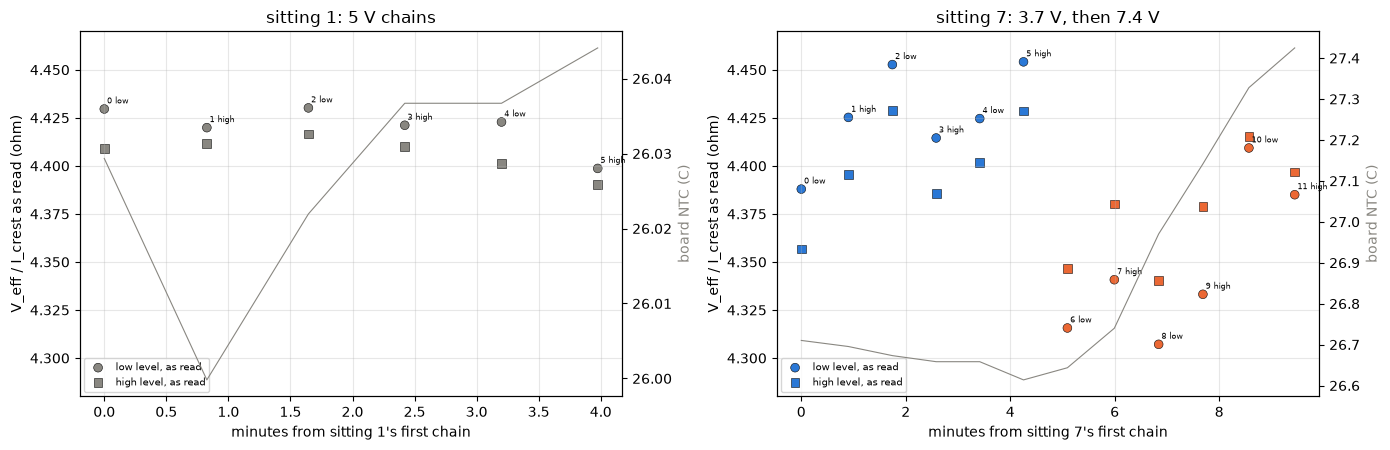

In [67]:
RAIL_COLOR = {3.7: BLUE, 5.0: MUTED, 7.4: ORANGE}  # per rail, 5 V gray
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for axis, sitting in zip(ax, (1, RAILS_SITTING)):
    g = BRACKETS[BRACKETS["sitting"] == sitting].sort_values("t_start")
    t = (g["t_start"] - g["t_start"].min()) / 60    # min from the first
    for level, marker in (("lo", "o"), ("hi", "s")):
        axis.scatter(t, g[f"vi_{level}"], marker=marker, s=40,
                     c=[RAIL_COLOR[v] for v in g["rail_v"]],
                     edgecolors=INK, linewidths=0.4,
                     label=("low" if level == "lo" else "high")
                     + " level, as read")
    for tt, (_, r) in zip(t, g.iterrows()):
        axis.annotate(f"{int(r['chain'])} {r['stop']}", (tt, r["vi_lo"]),
                      fontsize=6, xytext=(2, 4), textcoords="offset points")
    twin = axis.twinx()
    twin.plot(t, g["board_c"], "-", color=MUTED, lw=0.8)
    twin.set_ylabel("board NTC (C)", color=MUTED)
    axis.set_ylim(4.28, 4.47)
    axis.legend(fontsize=7, loc="lower left")
    figures.label(axis, x=f"minutes from sitting {sitting}'s first chain",
                  y="V_eff / I_crest as read (ohm)",
                  title=f"sitting {sitting}: " + (
                      "5 V chains" if sitting == 1 else "3.7 V, then 7.4 V"))
figures.finish(fig)

On 5 V the chains scatter by 0.26 % at the low level and 0.21 % at the high level, the sd over six chains. On 3.7 V they scatter by 0.56 and 0.62 %, and on 7.4 V by 0.93 and 0.66 %, two to four times as much. Inside each sitting 7 block the reads move with time. At 3.7 V the low level reads 4.388 ohm on chain 0 and 4.454 on chain 5, not in a steady climb between, and at 7.4 V chains 10 and 11 read 4.409 and 4.385 against 4.307 to 4.341 on chains 6 to 9. Two candidates are live. The horn rests at a different place before every seek, 1810 to 2089 counts, so each press lands the rotor at a different commutator angle, and the type's angle spread is +/-3 %. Or the read drifts with time. A rising drift would make the later 7.4 V block read higher than the 3.7 V block, and it reads lower, so a drift does not make the rail step. The fits below carry the sd over chains as the error, not the 2 to 5 mohm residual inside a step.

The servo's state that sitting, from the 5 V 30 % reference spins that bracket the plans of sittings 1, 6 and 7, the crest current over each spin's last 100 ms. State only, not analyzed.

In [68]:
def ref_spins(folder):
    # the 5 V 30 % reference spins of one bracket: the crest current
    # over the last 100 ms of each spin, both directions, state only
    out = []
    for _, c in pd.read_csv(folder / "cycles.csv").iterrows():
        df, _ = tel.load(folder / c["folder"], BOARD)
        zero_i, _ = tel.rest_zeros(df)
        driven = df[(df["seg"] > 0) & (df["duty_counts"] != 0)]
        for seg, g in driven.groupby("seg"):
            last = g.iloc[-int(0.1 * FS):]  # the spin's last 100 ms
            amps = SCALES.amps(last["current_raw"].to_numpy(float), zero_i)
            out.append({"set": folder.name, "dir": int(g["dir"].iloc[0]),
                        "i_last100_a": amps.mean()})
    return pd.DataFrame(out)


REFS = pd.concat([ref_spins(PAIR_DIR / "ladder" / f"ref-{side}-{n}")
                  for n in (1, 6, 7) for side in ("open", "close")],
                 ignore_index=True)
show(REFS.groupby(["set", "dir"])["i_last100_a"]
     .agg(lambda x: x.mean() * 1e3).round(1).rename("mA").reset_index(),
     n=None)

,set,dir,mA
0,ref-close-1,-1,94.500
1,ref-close-1,1,92.300
2,ref-close-6,-1,96.500
3,ref-close-6,1,99.300
4,ref-close-7,-1,94.600
5,ref-close-7,1,96.300
6,ref-open-1,-1,102.400
7,ref-open-1,1,105.700
8,ref-open-6,-1,98.100
9,ref-open-6,1,99.500


By direction, -1 then +1, the reference spin read 102.4 and 105.7 mA at sitting 1's open bracket and 94.5 and 92.3 mA at its close, 98.1 and 99.5 against 96.5 and 99.3 in sitting 6, and 93.7 and 97.0 against 94.6 and 96.3 in sitting 7. The run-in happened inside sitting 1. Sitting 7 opens and closes within 1 mA in each direction.

### The user's pass at each rail

The pass as the firmware forms it, each chain's bracket line as read, the mean and sd over six chains on each rail, with the chains' scatter at each level.

In [69]:
PASS = BRACKETS.groupby("rail_v").agg(
    r=("r_as_read", "mean"), r_sd=("r_as_read", "std"),
    v0=("v0_as_read", "mean"), v0_sd=("v0_as_read", "std"),
    scatter_lo_pct=("vi_lo", lambda x: x.std() / x.mean() * 100),
    scatter_hi_pct=("vi_hi", lambda x: x.std() / x.mean() * 100))
show(PASS.round(4).reset_index(), n=None)

,rail_v,r,r_sd,v0,v0_sd,scatter_lo_pct,scatter_hi_pct
0,3.700,4.346,0.033,0.020,0.003,0.561,0.621
1,5.000,4.377,0.015,0.011,0.005,0.260,0.212
2,7.400,4.436,0.028,-0.023,0.013,0.926,0.658


As read, the pass gives $R$ = 4.346 ohm sd 0.033 and $V_0$ = +0.020 V at 3.7 V, 4.377 and +0.011 at 5 V, and 4.436 and -0.023 at 7.4 V. From the low rail to the high one $R$ rises 2 % and $V_0$ falls 43 mV, on one motor at one pair of currents. A motor line has one $R$ and one $V_0$, so the rail dependence is the construction's, with high confidence.

### The as-read $V/I$ at one current against the rail

Each level's as-read $V/I$ on the three rails, a weighted line on the rail, the 7.4 V level less the 3.7 V level in the two levels' standard errors, and what each left-out term alone predicts for that difference at its stage 1 or type value.

In [70]:
TREND = {}                              # per level, the rail trend
for level, g in LEVELS.groupby("level"):
    g = g.sort_values("rail_v")
    fit, cov = np.polyfit(g["rail_v"], g["vi"], 1, w=1 / g["vi_se"],
                          cov=True)     # weighted line on the rail
    end, start = g.iloc[-1], g.iloc[0]  # 7.4 V and 3.7 V
    diff = end["vi"] - start["vi"]
    lever = {"edge": g["v_on"] / g["i"] / (2 * ARR) * g["edge_ticks"],
             "brake": LOOP["value"] * (1 - g["duty"]),
             "crest": R_TERM * g["crest_lever"]}   # ohm per unit of term
    pred = {n: x.iloc[-1] - x.iloc[0] for n, x in lever.items()}
    TREND[level] = {"slope": fit[0], "slope_se": np.sqrt(cov[0, 0]),
                    "diff": diff, "sigma": diff / np.hypot(end["vi_se"],
                                                           start["vi_se"]),
                    "edge": pred["edge"], "brake": pred["brake"],
                    "crest_per_ms": -pred["crest"] * 1e-3,
                    "crest_type_spin": -pred["crest"] * G_SPIN}
    print(f"{level}: " + ", ".join(f"{r['rail_v']:g} V {r['vi']:.4f} +/- "
                                   f"{r['vi_se']:.4f}" for _, r in g.iterrows())
          + f"; weighted slope {fit[0]:+.4f} +/- {np.sqrt(cov[0, 0]):.4f}"
          f" ohm/V; 7.4 less 3.7 V {diff:+.4f} ohm, "
          f"{TREND[level]['sigma']:+.1f} sigma")
for level, t in TREND.items():
    print(f"{level}: 7.4 less 3.7 V predicted by the edge lags (stage 1) "
          f"{t['edge']:+.4f}, the brake drop {t['brake']:+.4f}, a crest "
          f"term {t['crest_per_ms']:+.4f} per mS ({t['crest_type_spin']:+.4f}"
          f" at the type's spinning {G_SPIN * 1e3:.2f} mS) ohm")

high: 3.7 V 4.3995 +/- 0.0112, 5 V 4.4065 +/- 0.0038, 7.4 V 4.3764 +/- 0.0118; weighted slope -0.0078 +/- 0.0071 ohm/V; 7.4 less 3.7 V -0.0231 ohm, -1.4 sigma
low: 3.7 V 4.4265 +/- 0.0101, 5 V 4.4204 +/- 0.0047, 7.4 V 4.3485 +/- 0.0164; weighted slope -0.0194 +/- 0.0111 ohm/V; 7.4 less 3.7 V -0.0780 ohm, -4.0 sigma
high: 7.4 less 3.7 V predicted by the edge lags (stage 1) +0.1154, the brake drop +0.0752, a crest term -0.0391 per mS (-0.1311 at the type's spinning 3.35 mS) ohm
low: 7.4 less 3.7 V predicted by the edge lags (stage 1) +0.1674, the brake drop +0.0481, a crest term -0.0566 per mS (-0.1896 at the type's spinning 3.35 mS) ohm


At the low level, about 0.26 A, the as-read $V/I$ falls 0.078 ohm from 3.7 to 7.4 V, -4.0 sigma, and the weighted line gives -0.019 +/- 0.011 ohm per volt. At the high level it falls 0.023 ohm, -1.4 sigma, -0.008 +/- 0.007 ohm per volt, under 2 sigma and no finding on its own. The edge lags at stage 1's values predict a rise of +0.167 ohm at the low level and +0.115 at the high level, and the brake drop a rise of +0.048 and +0.075. A crest term predicts a fall, -0.057 and -0.039 ohm per mS of $g$, and -0.190 and -0.131 ohm at the type's spinning $G$. Only a crest term carries the sign of the low level's fall. The edge lever $1/D$ and the crest lever $(1 - D)\,V_\mathrm{on}/I$ differ by the factor $1 - D$, 0.51 to 0.84 over the six levels, and that factor is what separates the two, weakly.

The six levels against the edge term's lever on the left and the crest term's on the right, each a mean with its sd over six chains, the chains faint behind, colored by rail, circles the low level and squares the high level. The lock is the star, at $1/D$ = 1 and a crest lever of zero. The thing to see is which way the as-read $V/I$ moves at one current as the rail rises, before any fit.

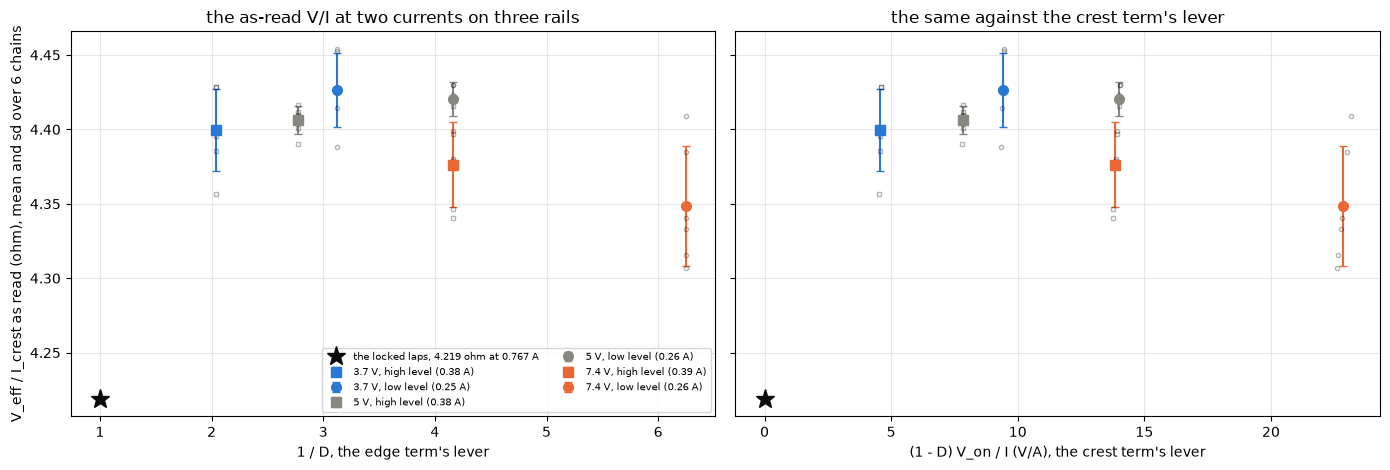

In [71]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for _, r in LEVELS.iterrows():
    marker = "o" if r["level"] == "low" else "s"
    for axis, x in zip(ax, (r["inv_d"], r["crest_lever"])):
        axis.errorbar(x, r["vi"], yerr=r["vi_sd"], fmt=marker, ms=7,
                      capsize=3, color=RAIL_COLOR[r["rail_v"]],
                      label=(f"{r['rail_v']:g} V, {r['level']} level "
                             f"({r['i']:.2f} A)") if axis is ax[0] else None)
for level, marker in (("lo", "o"), ("hi", "s")):   # each chain, faint
    d = BRACKETS[f"d_{level}"]
    xs = (1 / d, (1 - d) * BRACKETS[f"von_{level}"] / BRACKETS[f"i_{level}"])
    for axis, x in zip(ax, xs):
        axis.plot(x, BRACKETS[f"vi_{level}"], marker, ms=3, color=INK,
                  alpha=0.3, mfc="none")
for axis, x in zip(ax, (1, 0)):         # the lock: D = 1, no crest lever
    axis.plot(x, R_TERM, "*", ms=14, color=INK,
              label=(f"the locked laps, {R_TERM:.3f} ohm at {I_TERM:.3f} A"
                     if axis is ax[0] else None))
ax[0].legend(fontsize=7, ncol=2)
figures.label(ax[0], x="1 / D, the edge term's lever",
              y="V_eff / I_crest as read (ohm), mean and sd over 6 chains",
              title="the as-read V/I at two currents on three rails")
figures.label(ax[1], x="(1 - D) V_on / I (V/A), the crest term's lever",
              title="the same against the crest term's lever")
figures.finish(fig)

At both currents the 7.4 V points sit lowest. Against $1/D$ the as-read $V/I$ falls where the edge term alone would have it rise. Against the crest lever the low level's three points fall as the lever grows, the direction a crest over-read gives, and the high level's follow less clearly. The star sits 0.13 to 0.21 ohm under every level, the gap the section above found as read.

### One line under each construction

Each construction builds the applied volts and the winding current of every level through the notebook's `construct`, from the level's mean duty, $V_\mathrm{on}$ and crest current, with stage 1's edge lags taken per rail. The lock enters as its measured volts and current, 3.2344 V at 0.7666 A, and not through `construct`. At 100 % nothing switches, so there is no edge lag and no brake interval to take off. The line $V = V_0 + R\,I$ goes through the six level means and the lock by weighted least squares, each level weighted by its chains' standard error in volts and the lock by its six laps'. $R$ and $V_0$ enter linearly, and a term a construction leaves free is fitted by least squares inside a bound. Each standard error is scaled by $\chi^2$ per degree of freedom where that is over 1. A construction is graded by its $\chi^2$ ("chi squared") over its degrees of freedom, by the pull of its worst level, the residual over that level's standard error, and by the lock's pull.

The constructions, lettered as the analysis note letters them.

- A, as read, $D\,V_\mathrm{on}$ over the crest current.
- B, stage 1's edge lags per rail and the brake drop, the section above's "edge + brake", and B with the lags at their low and high bounds.
- C, B with a free per-volt crest term $g$, the winding current $I_\mathrm{crest} - g\,(1 - D)\,V_\mathrm{on}$, and C with $g$ fixed at the sag slope's 3.22 mS or at the type's spinning or locked $G$.
- D, the brake drop with a free scale on the edge lags and no crest term.
- E, D with a free $g$.
- F, the edge lags, the loop and $g$ all free.
- A with a free $g$, the brake drop alone with and without $g$, the edge lags alone, and A and B each with a free constant crest offset, the inductance notebook's second reading.

The cells below build the points, the fit and the constructions, then the sag laps' rail slope each fitted line predicts, formed as in the section above with the edge lags per rail.

In [72]:
LOCK_V = G3["r_first_ohm"] * G3["i_first_a"]    # V, each 3.7 V lap
LOCK = {"i": G3["i_first_a"].mean(), "v": LOCK_V.mean(),
        "v_sd": LOCK_V.std(), "v_se": LOCK_V.std() / np.sqrt(len(G3)),
        "laps_i": G3["i_first_a"].to_numpy(), "laps_v": LOCK_V.to_numpy(),
        "tags": [f"lock lap {c} {d:+d}"
                 for c, d in zip(G3["chain"], G3["dir"])]}
print(f"the locked anchor: {LOCK['v']:.4f} V sd {LOCK['v_sd']:.4f} at "
      f"{LOCK['i']:.4f} A over {len(G3)} laps, V/I "
      f"{LOCK['v'] / LOCK['i']:.4f} ohm")

the locked anchor: 3.2344 V sd 0.0052 at 0.7666 A over 6 laps, V/I 4.2189 ohm


In [73]:
def level_points(levels):
    # the level means as fit points: duty, V_on, crest current, stage 1's
    # edge lags and their bounds, sigma the level's se in volts
    return {"d": levels["duty"].to_numpy(), "von": levels["v_on"].to_numpy(),
            "i": levels["i"].to_numpy(),
            "e": levels["edge_ticks"].to_numpy(),
            "e_lo": levels["edge_lo"].to_numpy(),
            "e_hi": levels["edge_hi"].to_numpy(),
            "sig": (levels["vi_se"] * levels["i"]).to_numpy(),
            "tag": [f"{v:g} V {l}" for v, l in zip(levels["rail_v"],
                                                    levels["level"])]}


def chain_points(levels):
    # every chain's two bracket points, sigma the level's sd in volts
    sel = BRACKETS[BRACKETS["rail_v"].isin(levels["rail_v"].unique())]
    sd = {(v, l): s for v, l, s in zip(levels["rail_v"], levels["level"],
                                       levels["vi_sd"] * levels["i"])}
    rail = np.r_[sel["rail_v"], sel["rail_v"]]
    return {"d": np.r_[sel["d_lo"], sel["d_hi"]],
            "von": np.r_[sel["von_lo"], sel["von_hi"]],
            "i": np.r_[sel["i_lo"], sel["i_hi"]],
            "e": np.r_[sel["edge_ticks"], sel["edge_ticks"]],
            "e_lo": np.array([edge_ticks_at(v, "lo") for v in rail]),
            "e_hi": np.array([edge_ticks_at(v, "hi") for v in rail]),
            "sig": np.r_[[sd[(v, "low")] for v in sel["rail_v"]],
                         [sd[(v, "high")] for v in sel["rail_v"]]],
            "tag": [f"{v:g} V {l} k{k}" for l in ("low", "high")
                    for v, k in zip(sel["rail_v"], sel["chain"])]}

In [74]:
def with_lock(p, laps=False):
    # the lock appended as one point at its mean (sigma its se) or as
    # its six laps (sigma their sd): D = 1, no V_on, no edge lags
    n = len(LOCK["laps_i"]) if laps else 1
    i_lock = LOCK["laps_i"] if laps else [LOCK["i"]]
    out = {"d": np.r_[p["d"], np.ones(n)],
           "von": np.r_[p["von"], np.full(n, np.nan)],
           "i": np.r_[p["i"], i_lock],
           "v_lock": np.r_[LOCK["laps_v"] if laps else [LOCK["v"]]],
           "sig": np.r_[p["sig"], np.full(n, LOCK["v_sd" if laps
                                                   else "v_se"])],
           "tag": p["tag"] + (LOCK["tags"] if laps
                              else ["lock 3.7 V 100 %"]),
           "is_lock": np.r_[np.zeros(len(p["d"]), bool), np.ones(n, bool)]}
    for key in ("e", "e_lo", "e_hi"):
        out[key] = np.r_[p[key], np.zeros(n)]
    return out


def without_lock(p):
    # the chains alone, no lock point
    return {**p, "v_lock": np.array([]),
            "is_lock": np.zeros(len(p["d"]), bool)}

In [75]:
def applied(p, edge, rho, g, off):
    # the applied volts and winding current of every point through the
    # notebook's construct; the lock takes none, since 100 % does not
    # switch, and enters as its measured volts and current
    v, im = construct(p["d"], p["von"], p["i"], edge_ticks=edge,
                      loop_ohm=rho, g_s=g, offset_a=off)
    n = int((~p["is_lock"]).sum())
    v = np.where(p["is_lock"], np.r_[np.zeros(n), p["v_lock"]], v)
    im = np.where(p["is_lock"], p["i"], im)
    return v, im


def edge_of(s_e, p):
    # the edge lags per point: stage 1's bounds by name, else a scale on
    # stage 1's per-rail lags
    if isinstance(s_e, str):
        return p["e_lo"] if s_e == "lo" else p["e_hi"]
    return s_e * p["e"]


def solve(p, t, sig):
    # V0 and R by weighted least squares at fixed term values t, with
    # each point's pull, its residual over its sigma
    v, im = applied(p, edge_of(t["s_e"], p), t["rho"], t["g"], t["off"])
    a = np.c_[np.ones_like(im), im] / sig[:, None]     # columns V0, R
    (v0, r), *_ = np.linalg.lstsq(a, v / sig, rcond=None)
    return (v - (v0 + r * im)) / sig, v0, r, v, im

In [76]:
from scipy.optimize import least_squares    # the free terms' fit

FREE = {"s_e": (1.0, (-2, 4)),          # edge scale on stage 1's lags
        "rho": (LOOP["value"], (0, 1)),  # ohm, the low-side loop
        "g": (0.0, (-0.02, 0.03)),       # S, the per-volt crest term
        "off": (0.0, (-0.05, 0.05))}     # A, a constant crest offset


def fit_free(spec, p, sig):
    # the terms a construction leaves free (None in its spec) by least
    # squares from FREE's start inside FREE's bounds, with their se from
    # the jacobian, scaled by chi2 / dof where that is over 1
    free = [k for k, v in spec.items() if v is None]

    def terms(x):
        return {**spec, **dict(zip(free, x))}

    if not free:
        return terms([]), free, {}
    sol = least_squares(lambda x: solve(p, terms(x), sig)[0],
                        [FREE[k][0] for k in free],
                        bounds=([FREE[k][1][0] for k in free],
                                [FREE[k][1][1] for k in free]))
    dof = len(p["d"]) - 2 - len(free)
    chi2 = float((sol.fun ** 2).sum())
    try:
        cov = (np.linalg.inv(sol.jac.T @ sol.jac)
               * max(chi2 / max(dof, 1), 1.0))
        se = np.sqrt(np.diag(cov))
    except np.linalg.LinAlgError:
        se = np.full(len(free), np.nan)
    return terms(sol.x), free, dict(zip(free, se))

In [77]:
def fit(name, spec, p, weights=True):
    # one construction through the points: the free terms, then R and V0
    # with their se scaled by chi2 / dof where over 1, the fit's chi2,
    # the lock's pull, and each point's residual
    sig = p["sig"] if weights else np.ones_like(p["sig"])
    t, free, se = fit_free(spec, p, sig)
    pull, v0, r, v, im = solve(p, t, sig)
    dof = len(p["d"]) - 2 - len(free)
    chi2 = float((pull ** 2).sum())
    a = np.c_[np.ones_like(im), im] / sig[:, None]
    cov = np.linalg.inv(a.T @ a) * max(chi2 / max(dof, 1), 1.0)
    s_e, resid = t["s_e"], v - (v0 + r * im)   # V
    lock = p["is_lock"]
    out = {"construction": name, "r": r, "r_se": np.sqrt(cov[1, 1]),
           "v0": v0, "v0_se": np.sqrt(cov[0, 0]), "s_e": s_e,
           "edge_ticks_5v": (edge_ticks_at(5.0, s_e) if isinstance(s_e, str)
                             else s_e * edge_ticks_at(5.0)),
           "rho": t["rho"], "g_ms": t["g"] * 1e3, "off_ma": t["off"] * 1e3,
           "chi2": chi2, "dof": dof, "chi2_dof": chi2 / max(dof, 1),
           "rms_mv": float(np.sqrt(np.mean(resid ** 2))) * 1e3,
           "free": " ".join(free),
           **{f"{k}_se": se[k] * (1e3 if k in ("g", "off") else 1)
              for k in free},
           "lock_resid_mv": (float(resid[lock].mean()) * 1e3
                             if lock.any() else np.nan),
           "lock_pull_sigma": float(pull[lock].mean()) if lock.any()
           else np.nan}
    per = pd.DataFrame({"construction": name, "point": p["tag"],
                        "i_mean": im, "v_applied": v, "resid_mv": resid * 1e3,
                        "pull": pull, "vi_corrected": v / im})
    return out, per

In [78]:
B_TERMS = {"s_e": 1.0, "rho": LOOP["value"], "off": 0.0}  # stage 1's
CONSTRUCTIONS = {                       # None marks a term fitted free
    "A as read": {"s_e": 0.0, "rho": 0.0, "g": 0.0, "off": 0.0},
    "B edge + brake": {**B_TERMS, "g": 0.0},
    "B, lags lo": {**B_TERMS, "s_e": "lo", "g": 0.0},
    "B, lags hi": {**B_TERMS, "s_e": "hi", "g": 0.0},
    "C = B + g free": {**B_TERMS, "g": None},
    "C, g type spin": {**B_TERMS, "g": G_SPIN},
    "C, g type locked": {**B_TERMS, "g": G_LOCKED},
    "C, g sag 3.22": {**B_TERMS, "g": G_NEEDED},
    "D brake + edge free": {**B_TERMS, "s_e": None, "g": 0.0},
    "E brake + edge free + g": {**B_TERMS, "s_e": None, "g": None},
    "F all three free": {**B_TERMS, "s_e": None, "rho": None, "g": None},
    "A + g": {"s_e": 0.0, "rho": 0.0, "g": None, "off": 0.0},
    "brake only": {**B_TERMS, "s_e": 0.0, "g": 0.0},
    "brake only + g": {**B_TERMS, "s_e": 0.0, "g": None},
    "edge only": {**B_TERMS, "rho": 0.0, "g": 0.0},
    "B + const offset": {**B_TERMS, "g": 0.0, "off": None},
    "A + const offset": {"s_e": 0.0, "rho": 0.0, "g": 0.0, "off": None},
}
CONSTRUCTIONS = {n: {k: s[k] for k in FREE}     # one key order for all
                 for n, s in CONSTRUCTIONS.items()}


def run(p, weights=True):
    # every construction through one set of points
    fits, pers = zip(*(fit(n, s, p, weights)
                       for n, s in CONSTRUCTIONS.items()))
    return (pd.DataFrame(fits).set_index("construction"),
            pd.concat(pers, ignore_index=True))

In [79]:
P_MEANS = with_lock(level_points(LEVELS))       # six levels + the lock
FITS, RESID = run(P_MEANS)                      # the main set
S7_LEVELS = LEVELS[LEVELS["sitting"] == RAILS_SITTING]
FITS_S7, _ = run(with_lock(level_points(S7_LEVELS)))    # sitting 7 alone
FITS_CH, _ = run(with_lock(chain_points(LEVELS), laps=True))  # 30 points
FITS_EQ, _ = run(P_MEANS, weights=False)        # equal weights
print(f"{len(FITS)} constructions on {len(P_MEANS['d'])} points; "
      f"{len(FITS_CH)} on {len(BRACKETS) * 2 + len(G3)} chain points and "
      "laps")

17 constructions on 7 points; 17 on 42 chain points and laps


In [80]:
EDGE_SAG = np.array([edge_ticks_at(v) for v in RAILS_SAG])  # per rail


def sag_slope_for(s_e, rho, g, off, r, v0):
    # the as-read rail slope and level the sag laps would show under a
    # construction for the line (r, v0): each rail's as-read V/I over its
    # constructed V/I, times the line's V/I at that winding current
    edge = (np.array([edge_ticks_at(v, s_e) for v in RAILS_SAG])
            if isinstance(s_e, str) else s_e * EDGE_SAG)
    v_c, i_c = construct(DUTY_SAG, VON_SAG, I_SAG, edge_ticks=edge,
                         loop_ohm=rho, g_s=g, offset_a=off)
    as_read = (VEFF_SAG / I_SAG) / (v_c / i_c) * (r + v0 / i_c)
    return float(np.polyfit(RAILS_SAG, as_read, 1)[0]), float(as_read.mean())


rows = []                               # each fitted line's prediction
for name, f in FITS.iterrows():
    slope, level = sag_slope_for(f["s_e"], f["rho"], f["g_ms"] * 1e-3,
                                 f["off_ma"] * 1e-3, f["r"], f["v0"])
    rows.append({"construction": name, "sag_slope_pred": slope,
                 "sag_level_pred": level,
                 "sag_slope_sigma": (SAG_SLOPE["value"] - slope)
                 / SAG_SLOPE_SE})
SAG_PRED = pd.DataFrame(rows).set_index("construction")

The fits on the six level means and the lock. Per construction, $R$ and $V_0$ with their standard errors, the edge lags at 5 V and $g$ as fitted or fixed, $\chi^2$ over its degrees of freedom, the rms residual, the lock's pull, the worst level with its pull, and the sag slope the line predicts with its distance from the measured slope in the sag's sigma.

In [81]:
pulls = RESID[~RESID["point"].str.startswith("lock")].pivot(
    index="construction", columns="point", values="pull")
worst = pulls.abs().idxmax(axis=1)      # the level each fit misses most
worst_pull = pd.Series({n: pulls.loc[n, w] for n, w in worst.items()})
TABLE = FITS[["r", "r_se", "v0", "v0_se", "edge_ticks_5v", "g_ms", "g_se",
              "chi2", "dof", "rms_mv", "lock_pull_sigma"]].assign(
    worst=worst, worst_pull=worst_pull,
    sag_pred=SAG_PRED["sag_slope_pred"],
    sag_sigma=SAG_PRED["sag_slope_sigma"])
show(TABLE.round(4).reset_index(), n=None)
for name in ("D brake + edge free", "E brake + edge free + g",
             "F all three free"):
    f = FITS.loc[name]
    print(f"{name}: edge {f['edge_ticks_5v']:.1f} +/- "
          f"{f['s_e_se'] * edge_ticks_at(5.0):.1f} ticks at 5 V"
          + (f", loop {f['rho']:.3f} +/- {f['rho_se']:.3f} ohm"
             if name.startswith("F") else "")
          + (f", offset {f['off_ma']:.1f} mA" if f["off_ma"] else ""))
for name in ("A + const offset", "B + const offset"):
    f = FITS.loc[name]
    print(f"{name}: offset {f['off_ma']:+.1f} +/- {f['off_se']:.1f} mA")

,construction,r,r_se,v0,v0_se,edge_ticks_5v,g_ms,g_se,chi2,dof,rms_mv,lock_pull_sigma,worst,worst_pull,sag_pred,sag_sigma
0,A as read,4.124,0.042,0.086,0.017,0.000,0.000,NaN,407.315,5,17.142,-6.225,5 V high,15.269,0.000,-0.778
1,B edge + brake,4.328,0.046,-0.089,0.019,25.054,0.000,NaN,499.550,5,33.934,2.395,7.4 V high,-13.637,0.050,-7.833
2,"B, lags lo",4.226,0.026,-0.004,0.011,-1.892,0.000,NaN,155.863,5,19.796,-0.465,7.4 V low,-8.312,0.018,-3.351
3,"B, lags hi",4.416,0.074,-0.161,0.030,48.108,0.000,NaN,1276.582,5,52.483,4.979,7.4 V high,-21.615,0.097,-14.479
4,C = B + g free,4.177,0.006,0.031,0.002,25.054,5.004,0.319,7.475,4,2.667,0.531,5 V low,1.676,-0.027,2.984
5,"C, g type spin",4.226,0.016,-0.008,0.006,25.054,3.349,NaN,58.911,5,11.670,1.038,7.4 V high,-5.123,-0.002,-0.495
6,"C, g type locked",4.252,0.023,-0.028,0.009,25.054,2.493,NaN,127.234,5,17.215,1.341,7.4 V high,-7.263,0.011,-2.332
7,"C, g sag 3.22",4.230,0.017,-0.011,0.007,25.054,3.220,NaN,67.362,5,12.498,1.082,7.4 V high,-5.445,-0.000,-0.771
8,D brake + edge free,4.191,0.015,0.025,0.006,-11.115,0.000,NaN,43.559,4,7.733,-1.650,5 V high,4.213,-0.010,0.587
9,E brake + edge free + g,4.176,0.005,0.033,0.002,16.213,3.909,0.706,3.871,3,2.229,-0.048,3.7 V low,-1.463,-0.024,2.620


D brake + edge free: edge -11.1 +/- 5.6 ticks at 5 V
E brake + edge free + g: edge 16.2 +/- 5.3 ticks at 5 V
F all three free: edge -5.5 +/- 28.8 ticks at 5 V, loop 0.388 +/- 0.116 ohm
A + const offset: offset -29.7 +/- 3.5 mA
B + const offset: offset +12.4 +/- 16.4 mA


Four constructions fail on the rails. As read, A gives $\chi^2$ 407 over 5, its worst level 5 V high at +15.3 sigma and the lock at -6.2. B with stage 1's lags gives 500 over 5, the 7.4 V high level at -13.6 sigma. B at the lags' low bound, the section above's second reading, gives 156 over 5, the 7.4 V low level at -8.3 sigma. D, the brake drop with the edge lags free and no crest term, gives 43.6 over 4 and leaves the 5 V high level at +4.2 sigma, and it needs the lags at -11.1 +/- 5.6 ticks, a window longer than the commanded one. The section above's first reading, C with $g$ at the sag's 3.22 mS, gives 67 over 5, so at stage 1's lags the crest term the sag asks for is too small for the rails.

Two constructions fit. C, B with $g$ free, gives $R$ = 4.1766 +/- 0.0061 ohm, $V_0$ = +0.0313 +/- 0.0024 V and $g$ = 5.00 +/- 0.32 mS at stage 1's lags, with $\chi^2$ 7.5 over 4, its worst level 5 V low at +1.7 sigma and the lock at +0.5. That $g$ holds at stage 1's lags only, and C's line predicts the sag slope at -0.027 ohm per volt, 3.0 sigma from the measured -0.0055. E, the edge lags free with $g$, gives $R$ = 4.1762 +/- 0.0051 ohm, $V_0$ = +0.0328 +/- 0.0020 V, the lags at 16.2 +/- 5.3 ticks and $g$ = 3.91 +/- 0.71 mS, with $\chi^2$ 3.9 over 3, its worst level 3.7 V low at -1.5 sigma and the lock at 0.0. F, with the loop free as well, trades the loop, 0.388 +/- 0.116 ohm, against the edge lags, -5.5 +/- 28.8 ticks, and $g$, 1.8 +/- 2.8 mS, at $\chi^2$ 3.0 over 2, so these levels leave the loop tied to the other two. A constant crest offset fits neither way, A with one at 24.3 over 4 and its 7.4 V low level at -4.1 sigma, B with one at 435 over 4. The brake drop with $g$ and no edge lags gives 16.0 over 4.

The same constructions on every chain's two bracket points with the six laps, on sitting 7's chains alone with the lock, and with equal weights.

In [82]:
for label, fits in (("every chain's bracket points", FITS_CH),
                    ("sitting 7 alone with the lock", FITS_S7)):
    print(f"{label}: " + ", ".join(
        f"{n.split()[0]} {fits.loc[n, 'chi2']:.1f}/{fits.loc[n, 'dof']}"
        + (f" g {fits.loc[n, 'g_ms']:.2f} +/- {fits.loc[n, 'g_se']:.2f}"
           if np.isfinite(fits.loc[n, "g_se"]) else "")
        for n in ("A as read", "B edge + brake", "C = B + g free",
                  "D brake + edge free", "E brake + edge free + g",
                  "brake only + g")))
c7 = FITS_S7.loc["C = B + g free"]
print(f"sitting 7 alone, C: R {c7['r']:.4f} +/- {c7['r_se']:.4f}, V0 "
      f"{c7['v0']:+.4f}, g {c7['g_ms']:.2f} +/- {c7['g_se']:.2f} mS")
dr = (FITS_EQ["r"] - FITS["r"]).abs()   # equal weights against se weights
dv = (FITS_EQ["v0"] - FITS["v0"]).abs()
print(f"equal weights move R by {dr.max():.3f} ohm and V0 by "
      f"{dv.max():.3f} V at most ({dr.idxmax()}, {dv.idxmax()})")
for n in ("C = B + g free", "E brake + edge free + g"):
    print(f"  {n}: R by {dr[n]:.4f} ohm, V0 by {dv[n]:.4f} V")

every chain's bracket points: A 445.8/40, B 544.1/40, C 49.6/39 g 5.02 +/- 0.26, D 85.8/39, E 45.9/38 g 3.92 +/- 0.68, brake 58.0/39 g 1.91 +/- 0.28
sitting 7 alone with the lock: A 80.9/3, B 480.6/3, C 0.7/2 g 4.98 +/- 0.24, D 13.4/2, E 0.4/1 g 4.35 +/- 1.20, brake 4.3/2 g 2.01 +/- 0.34
sitting 7 alone, C: R 4.1853 +/- 0.0056, V0 +0.0256, g 4.98 +/- 0.24 mS
equal weights move R by 0.034 ohm and V0 by 0.028 V at most (B, lags hi, B, lags hi)
  C = B + g free: R by 0.0022 ohm, V0 by 0.0016 V
  E brake + edge free + g: R by 0.0002 ohm, V0 by 0.0001 V


On every chain's bracket points with the six laps, A gives $\chi^2$ 446 over 40 and B 544 over 40, while C gives 49.6 over 39 with $g$ = 5.02 +/- 0.26 mS, D 85.8 over 39 and E 45.9 over 38 with $g$ = 3.92 +/- 0.68 mS. Sitting 7's chains alone with the lock, no sitting 1 data, give A 81 over 3 and B 481 over 3, and C 0.7 over 2 with $R$ = 4.1853 ohm and $g$ = 4.98 +/- 0.24 mS. So the 5 V chains from another sitting do not carry the result. Equal weights move $R$ by 0.034 ohm and $V_0$ by 0.028 V at most, both on B at the lags' high bound, and C and E by under 0.01 in both.

The pull of every level and the lock under ten of the constructions, then the same as bars, the residual in mV on the left and the pull on the right, with each fit's $\chi^2$ over its degrees of freedom in the legend. The thing to see is which constructions keep every bar inside +/- 2 sigma.

In [83]:
SHOWN_FITS = ["A as read", "B edge + brake", "B, lags lo", "C, g sag 3.22",
              "C, g type spin", "C = B + g free", "D brake + edge free",
              "E brake + edge free + g", "brake only + g",
              "A + const offset"]  # ten constructions, the figure's
POINT_ORDER = list(P_MEANS["tag"])      # six levels, then the lock
show(RESID.pivot(index="construction", columns="point", values="pull")
     .loc[SHOWN_FITS, POINT_ORDER].round(1).reset_index(), n=None)

point,construction,3.7 V high,3.7 V low,5 V high,5 V low,7.4 V high,7.4 V low,lock 3.7 V 100 %
0,A as read,4.400,-3.800,15.300,-7.500,2.600,-6.200,-6.200
1,B edge + brake,5.300,10.300,-3.500,2.200,-13.600,-12.500,2.400
2,"B, lags lo",4.200,3.600,2.500,-0.500,-7.000,-8.300,-0.500
3,"C, g sag 3.22",1.500,2.700,-1.900,1.900,-5.400,-4.400,1.100
4,"C, g type spin",1.300,2.400,-1.800,1.900,-5.100,-4.100,1.000
5,C = B + g free,-0.600,-1.400,-1.000,1.700,-1.100,-0.200,0.500
6,D brake + edge free,2.700,-0.500,4.200,-1.800,-1.300,-3.200,-1.600
7,E brake + edge free + g,0.100,-1.500,0.300,0.800,-0.800,-0.600,-0.000
8,brake only + g,1.300,-1.600,2.800,-0.800,-0.300,-1.400,-1.100
9,A + const offset,-0.300,0.800,0.900,0.700,-2.200,-4.100,-0.000


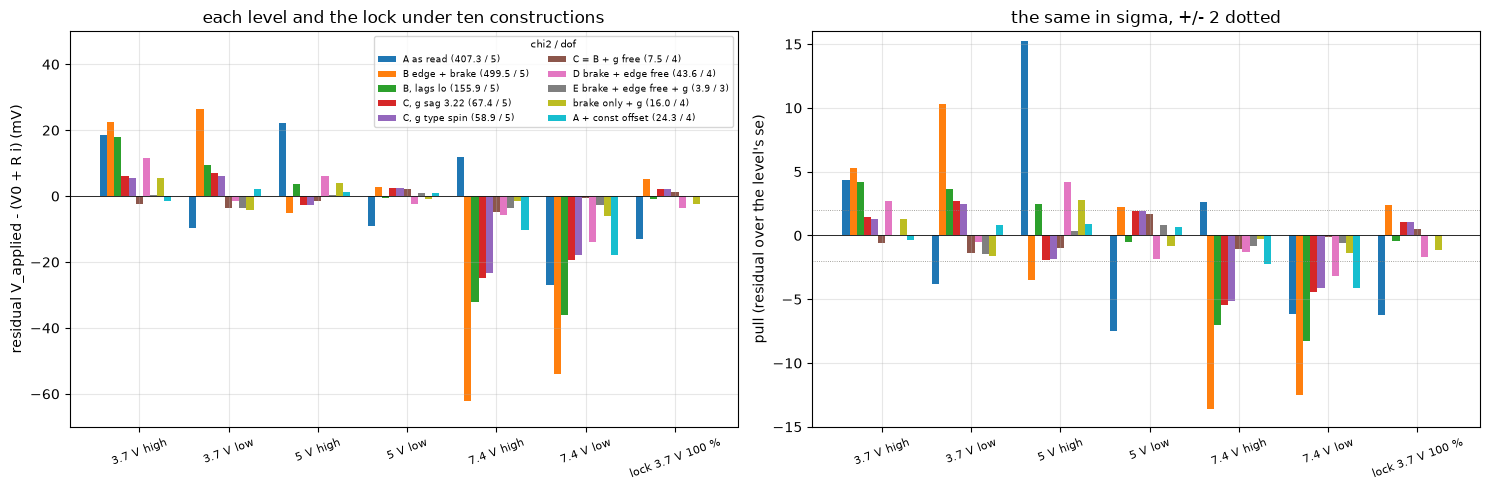

In [84]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(POINT_ORDER))
width = 0.08                            # one bar per construction
for j, name in enumerate(SHOWN_FITS):
    g = RESID[RESID["construction"] == name].set_index("point")
    f = FITS.loc[name]
    bars = x + (j - len(SHOWN_FITS) / 2) * width
    ax[0].bar(bars, g.loc[POINT_ORDER, "resid_mv"], width,
              color=plt.cm.tab10(j % 10),
              label=f"{name} ({f['chi2']:.1f} / {f['dof']})")
    ax[1].bar(bars, g.loc[POINT_ORDER, "pull"], width,
              color=plt.cm.tab10(j % 10))
for axis in ax:
    axis.set_xticks(x, POINT_ORDER, rotation=20, fontsize=8)
    axis.axhline(0, color=INK, lw=0.6)
for y in (-2, 2):
    ax[1].axhline(y, **figures.EDGE_STYLE)
ax[0].set_ylim(-70, 50)
ax[1].set_ylim(-15, 16)
ax[0].legend(fontsize=6.5, ncol=2, title="chi2 / dof", title_fontsize=7)
figures.label(ax[0], y="residual V_applied - (V0 + R i) (mV)",
              title="each level and the lock under ten constructions")
figures.label(ax[1], y="pull (residual over the level's se)",
              title="the same in sigma, +/- 2 dotted")
figures.finish(fig)

Under A the 5 V levels pull +15.3 and -7.5 sigma and the 7.4 V low level and the lock -6.2. Under B and at the lags' low bound the 7.4 V levels sit 32 to 62 mV under the line. With a crest term fixed at the sag's or the type's spinning $G$ at stage 1's lags, the 7.4 V levels still pull -4.1 to -5.4 sigma. Under C and E every level and the lock sit inside 2 sigma.

### The valley

C and E differ in where they put the edge lags, and $g$ moves with them. The grid below holds the loop at stage 1's 0.301 ohm, steps the edge lags from -0.5 to 1.5 times stage 1's per-rail values, -12.5 to 37.6 ticks at 5 V, and steps $g$ from -1 to 8 mS. At each point $R$ and $V_0$ are fitted again and the $\chi^2$ of the six levels and the lock recorded, alone and with the sag laps' measured rail slope joined as one more datum in its own standard error. The bands within 1 and 4 of the minimum are the 1 and 2 sigma ranges for one quantity of interest.

In [85]:
rows = []                               # chi2 over (edge scale, g)
for s_e in np.linspace(-0.5, 1.5, 41):  # 0 to 1.5 x stage 1's lags
    for g_ms in np.linspace(-1, 8, 46):     # mS, the crest term
        spec = {"s_e": s_e, "rho": LOOP["value"], "g": g_ms * 1e-3,
                "off": 0.0}             # the loop at stage 1's value
        f, _ = fit("grid", spec, P_MEANS)
        slope, _ = sag_slope_for(s_e, LOOP["value"], g_ms * 1e-3, 0.0,
                                 f["r"], f["v0"])   # the sag laps
        chi2_sag = ((SAG_SLOPE["value"] - slope) / SAG_SLOPE_SE) ** 2
        rows.append({"s_e": s_e, "edge_ticks_5v": f["edge_ticks_5v"],
                     "g_ms": g_ms, "chi2": f["chi2"], "r": f["r"],
                     "v0": f["v0"], "sag_slope_pred": slope,
                     "chi2_sag": chi2_sag,
                     "chi2_joint": f["chi2"] + chi2_sag})
PROFILE = pd.DataFrame(rows)
print(f"{len(PROFILE)} points on the grid")

1886 points on the grid


In [86]:
def band(col, d_chi2):
    # the grid's minimum of `col` and the points within d_chi2 of it
    best = PROFILE.loc[PROFILE[col].idxmin()]
    return best, PROFILE[PROFILE[col] <= best[col] + d_chi2]


VALLEY = {}                             # (surface, d_chi2): min, band
for col, name in (("chi2", "chains + lock"),
                  ("chi2_joint", "with the sag slope")):
    for d_chi2 in (1.0, 4.0):
        best, inside = band(col, d_chi2)
        VALLEY[(col, d_chi2)] = (best, inside)
        print(f"{name}, chi2 + {d_chi2:.0f}: minimum {best[col]:.2f} at "
              f"{best['edge_ticks_5v']:.1f} ticks, g {best['g_ms']:.1f} mS, R "
              f"{best['r']:.4f}, V0 {best['v0']:+.4f}; band edge "
              f"{inside['edge_ticks_5v'].min():.1f} to "
              f"{inside['edge_ticks_5v'].max():.1f}, g "
              f"{inside['g_ms'].min():.1f} to {inside['g_ms'].max():.1f}, R "
              f"{inside['r'].min():.4f} to {inside['r'].max():.4f}, V0 "
              f"{inside['v0'].min():+.4f} to {inside['v0'].max():+.4f}")
bj = VALLEY[("chi2_joint", 1.0)][0]
print(f"joint minimum: chains {bj['chi2']:.2f}, sag {bj['chi2_sag']:.2f}, "
      f"sag slope predicted {bj['sag_slope_pred']:+.4f} against "
      f"{SAG_SLOPE['value']:+.4f} +/- {SAG_SLOPE_SE:.4f}")
FLOOR = PROFILE.loc[PROFILE.groupby("s_e")["chi2"].idxmin()]
show(FLOOR.iloc[::5][["edge_ticks_5v", "g_ms", "chi2", "r", "v0"]]
     .round(3), n=None)

chains + lock, chi2 + 1: minimum 3.96 at 15.0 ticks, g 3.8 mS, R 4.1750, V0 +0.0339; band edge 12.5 to 20.0, g 3.4 to 4.4, R 4.1704 to 4.1823, V0 +0.0283 to +0.0377
chains + lock, chi2 + 4: minimum 3.96 at 15.0 ticks, g 3.8 mS, R 4.1750, V0 +0.0339; band edge 7.5 to 25.1, g 2.8 to 5.0, R 4.1631 to 4.1891, V0 +0.0223 to +0.0433
with the sag slope, chi2 + 1: minimum 9.37 at 13.8 ticks, g 3.4 mS, R 4.1823, V0 +0.0283; band edge 11.3 to 18.8, g 3.0 to 4.0, R 4.1776 to 4.1883, V0 +0.0236 to +0.0322
with the sag slope, chi2 + 4: minimum 9.37 at 13.8 ticks, g 3.4 mS, R 4.1823, V0 +0.0283; band edge 6.3 to 22.5, g 2.4 to 4.6, R 4.1704 to 4.1943, V0 +0.0189 to +0.0377
joint minimum: chains 4.95, sag 4.42, sag slope predicted -0.0204 against -0.0055 +/- 0.0071


,edge_ticks_5v,g_ms,chi2,r,v0
7,-12.527,0.400,42.024,4.173,0.039
241,-6.264,1.200,27.289,4.173,0.038
474,0.000,1.800,16.176,4.179,0.033
708,6.264,2.600,8.543,4.178,0.033
942,12.527,3.400,4.548,4.178,0.032
1176,18.791,4.200,4.192,4.177,0.032
1410,25.054,5.000,7.475,4.177,0.031
1644,31.318,5.800,14.398,4.176,0.031
1878,37.581,6.600,24.962,4.176,0.030


The chains and the lock alone reach their minimum, $\chi^2$ 3.96 over 3, at 15.0 ticks and $g$ = 3.8 mS, with $R$ = 4.1750 ohm and $V_0$ = +0.0339 V. Within $\chi^2$ + 1 the edge lags run 12.5 to 20.0 ticks and $g$ 3.4 to 4.4 mS, and within $\chi^2$ + 4 they run 7.5 to 25.1 ticks and 2.8 to 5.0 mS. Along the valley's floor $g$ climbs from 1.8 mS at no lag to 3.4 at 12.5 ticks, 5.0 at stage 1's 25.1 and 6.6 at 37.6, with $\chi^2$ 16.2, 4.5, 7.5 and 25.0. Along the same floor $R$ stays at 4.176 to 4.179 ohm and $V_0$ at +0.030 to +0.033 V. Within $\chi^2$ + 1, $R$ runs 4.1704 to 4.1823 ohm and $V_0$ +0.0283 to +0.0377 V.

With the sag slope joined, the minimum moves to 13.8 ticks and $g$ = 3.4 mS, $\chi^2$ 9.37 over 4, 4.95 from the chains and 4.42 from the sag slope, with $R$ = 4.1823 ohm and $V_0$ = +0.0283 V. Within $\chi^2$ + 1 the lags run 11.3 to 18.8 ticks and $g$ 3.0 to 4.0 mS, and within $\chi^2$ + 4 they run 6.3 to 22.5 ticks and 2.4 to 4.6 mS, with $R$ 4.1704 to 4.1943 ohm and $V_0$ +0.0189 to +0.0377 V. At the joint minimum the line predicts the sag slope at -0.0204 ohm per volt against the measured -0.0055 +/- 0.0071, a pull of 2.1 sigma.

$\chi^2$ over its minimum on the grid, the chains and the lock on the left and with the sag slope on the right, contours at 1, 4 and 9. Stage 1's lags and their bounds are the orange verticals, the sag slope's $g$ under B and the type's spinning $G$ the green horizontals, the ladder's form B term the red one, and the minimum the star. The thing to see is the valley's direction and where the quoted terms cross it.

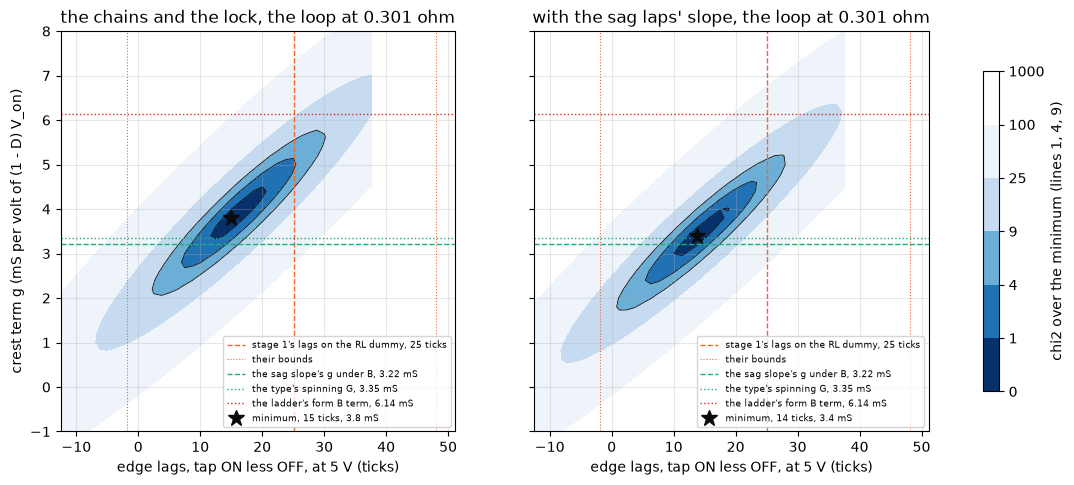

In [87]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for axis, col, title in ((ax[0], "chi2", "the chains and the lock"),
                         (ax[1], "chi2_joint", "with the sag laps' slope")):
    z = PROFILE.pivot(index="g_ms", columns="edge_ticks_5v", values=col)
    above = z.values - z.values.min()   # chi2 over the minimum
    filled = axis.contourf(z.columns, z.index, above,
                           levels=[0, 1, 4, 9, 25, 100, 1000],
                           colors=["#08306b", "#2171b5", "#6baed6",
                                   "#c6dbef", "#eef4fa", "#ffffff"])
    axis.contour(z.columns, z.index, above, levels=[1, 4, 9], colors=INK,
                 linewidths=0.6)
    axis.axvline(edge_ticks_at(5.0), color=ORANGE, ls="--", lw=1,
                 label=f"stage 1's lags on the RL dummy, "
                 f"{edge_ticks_at(5.0):.0f} ticks")
    for which in ("lo", "hi"):
        axis.axvline(edge_ticks_at(5.0, which), color=ORANGE, ls=":",
                     lw=0.8, label="their bounds" if which == "lo" else None)
    for g_ms, ls, color, what in (
            (G_NEEDED * 1e3, "--", GREEN, "the sag slope's g under B"),
            (G_SPIN * 1e3, ":", GREEN, "the type's spinning G"),
            (LADDER["rail_term_b_g_ms"]["value"], ":", figures.RED,
             "the ladder's form B term")):
        axis.axhline(g_ms, color=color, ls=ls, lw=1,
                     label=f"{what}, {g_ms:.2f} mS")
    best = VALLEY[(col, 1.0)][0]
    axis.plot(best["edge_ticks_5v"], best["g_ms"], "*", ms=12, color=INK,
              label=f"minimum, {best['edge_ticks_5v']:.0f} ticks, "
              f"{best['g_ms']:.1f} mS")
    axis.legend(fontsize=6.5, loc="lower right")
    figures.label(axis, x="edge lags, tap ON less OFF, at 5 V (ticks)",
                  title=f"{title}, the loop at {LOOP['value']:.3f} ohm")
figures.label(ax[0], y="crest term g (mS per volt of (1 - D) V_on)")
fig.colorbar(filled, ax=ax, label="chi2 over the minimum (lines 1, 4, 9)",
             shrink=0.8)
plt.show()

The valley runs from short lags and a small $g$ up to stage 1's lags and 5 mS. Stage 1's lags sit on its slope, $\chi^2$ 3.5 over the chains' minimum and further over the joint one. The sag slope's 3.22 mS and the type's spinning 3.35 mS cross the valley near 12 ticks, inside the joint 1 sigma band and the chains' 2 sigma band. The ladder's 6.14 mS sits outside both 2 sigma bands on the grid. So the rails fix a line through $g$ and the lags, not a point on it. A $g$ of 5.0 mS holds only at stage 1's lags, and 3.4 mS at 14 ticks with the sag slope joined.

The jackknife, each of the 18 chains left out in turn, on C, E and the brake drop with $g$.

In [88]:
def levels_from(br):
    # the six level means rebuilt from a set of chains' bracket points
    rows = []
    both = pd.concat([br.assign(level=l, i=br[f"i_{s}"], v=br[f"v_{s}"],
                                von=br[f"von_{s}"], duty=br[f"d_{s}"])
                      for l, s in (("low", "lo"), ("high", "hi"))])
    for (v, l), g in both.groupby(["rail_v", "level"]):
        vi = g["v"] / g["i"]
        rows.append({"rail_v": v, "level": l, "duty": g["duty"].iloc[0],
                     "edge_ticks": g["edge_ticks"].iloc[0],
                     "edge_lo": edge_ticks_at(v, "lo"),
                     "edge_hi": edge_ticks_at(v, "hi"), "i": g["i"].mean(),
                     "v_on": g["von"].mean(), "vi_sd": vi.std(),
                     "vi_se": vi.std() / np.sqrt(len(g))})
    return pd.DataFrame(rows)


rows = []                               # one fit per chain left out
for name in ("C = B + g free", "E brake + edge free + g", "brake only + g"):
    for v, k in BRACKETS[["rail_v", "chain"]].itertuples(index=False):
        keep = ~((BRACKETS["rail_v"] == v) & (BRACKETS["chain"] == k))
        p = with_lock(level_points(levels_from(BRACKETS[keep])))
        f, _ = fit(name, CONSTRUCTIONS[name], p)
        rows.append({"construction": name, "left_out": f"{v:g} V k{k}",
                     **{c: f[c] for c in ("g_ms", "r", "v0", "chi2")}})
JACK = pd.DataFrame(rows)


def jack_se(x):
    # the jackknife standard error over the leave-one-out values
    return np.sqrt((len(x) - 1) / len(x) * ((x - x.mean()) ** 2).sum())

In [89]:
JACK_SE = JACK.groupby("construction").agg(
    g_min=("g_ms", "min"), g_max=("g_ms", "max"), g_se=("g_ms", jack_se),
    r_min=("r", "min"), r_max=("r", "max"), r_se=("r", jack_se),
    v0_min=("v0", "min"), v0_max=("v0", "max"))
show(JACK_SE.round(4).reset_index(), n=None)

,construction,g_min,g_max,g_se,r_min,r_max,r_se,v0_min,v0_max
0,C = B + g free,4.863,5.234,0.380,4.168,4.181,0.014,0.028,0.036
1,E brake + edge free + g,3.732,4.226,0.614,4.170,4.180,0.012,0.030,0.038
2,brake only + g,1.736,2.168,0.438,4.168,4.183,0.014,0.032,0.041


Leaving out one chain moves C's $g$ over 4.86 to 5.23 mS, E's over 3.73 to 4.23 and the brake drop's with $g$ over 1.74 to 2.17, with jackknife standard errors of 0.38, 0.61 and 0.44 mS, near the fits' own. $R$ moves over 4.168 to 4.183 ohm in all three. No single chain carries the result.

The six levels with the lock left out, and each line's $V/I$ at the lock's 0.767 A against $R_\mathrm{term}$. The lock is not in these fits, so no weighting between it and the chains enters the check.

In [90]:
P_ALONE = without_lock(level_points(LEVELS))    # the six levels only
rows = []
for name in ("A as read", "B edge + brake", "C = B + g free",
             "E brake + edge free + g", "brake only + g"):
    f, _ = fit(name, CONSTRUCTIONS[name], P_ALONE)
    at_lock = f["r"] + f["v0"] / I_TERM     # ohm, the line at 0.767 A
    rows.append({"construction": name, "r": f["r"], "r_se": f["r_se"],
                 "v0": f["v0"], "g_ms": f["g_ms"],
                 "edge_ticks_5v": f["edge_ticks_5v"], "chi2": f["chi2"],
                 "dof": f["dof"], "vi_at_lock": at_lock,
                 "over_lock_pct": (at_lock / R_TERM - 1) * 100})
ALONE = pd.DataFrame(rows).set_index("construction")
show(ALONE.round(4).reset_index(), n=None)

,construction,r,r_se,v0,g_ms,edge_ticks_5v,chi2,dof,vi_at_lock,over_lock_pct
0,A as read,4.373,0.033,0.011,0.000,0.000,24.292,4,4.388,4.010
1,B edge + brake,4.232,0.143,-0.060,0.000,25.054,442.862,4,4.154,-1.543
2,C = B + g free,4.157,0.016,0.036,4.919,25.054,4.470,3,4.203,-0.369
3,E brake + edge free + g,4.337,0.014,0.008,-3.323,-50.108,0.888,2,4.347,3.046
4,brake only + g,4.217,0.013,0.026,2.103,0.000,2.841,3,4.251,0.771


Without the lock, C gives $R$ = 4.157 +/- 0.016 ohm, $V_0$ = +0.036 V and $g$ = 4.92 mS at $\chi^2$ 4.5 over 3, and its line at 0.767 A reads 4.2033 ohm, -0.37 % from $R_\mathrm{term}$. The brake drop with $g$ predicts +0.77 %. As read, A predicts +4.01 %, and B, at $\chi^2$ 443 over 4, -1.54 %. E without the lock runs to -50 ticks and a negative $g$, unconstrained. So under C the chains alone reach the lock's 100 % read within 0.4 % from levels at 16 to 49 % on three rails.

### What the rails decide and what they leave

1. Confirmed, high. The partial-duty read carries a crest over-read proportional to $(1 - D)\,V_\mathrm{on}$ on top of the brake drop. No construction without it fits the three rails. A as read, B as the section above stated it, and B at the lags' low bound fail at 156 to 500 over 5. The best construction without a crest term, D, fails at 43.6 over 4 and needs an edge lag of -11 ticks, a window longer than commanded.
2. Likely. Along the valley the motor's line is $R$ = 4.17 to 4.19 ohm and $V_0$ = +0.02 to +0.04 V wherever on the valley the fit sits, and the chains alone predict the lock within 0.4 %. These two numbers are the ones firmware takes, and they do not wait on how $g$ and the lags split.
3. Likely. $g$ is 3.0 to 4.0 mS with the edge lags at 11 to 19 ticks, the joint minimum 3.4 mS at 14 ticks, the size of the type's spinning $G$, 3.35 mS, and of the sag slope's 3.22 mS. At stage 1's lags taken as they are, $g$ is 5.00 +/- 0.32 mS and the sag slope is missed by 3.0 sigma, so C with the RL dummy's lags is disfavored at about 2 sigma by the chains and 3 sigma with the sag.
4. Candidate, about 2 sigma. The bridge's edge lags on the motor are about half of the RL dummy's, 14 against 25 ticks. A short-window current effect that scales like $1/D$ moves the same lever, and in F the loop trades against both, so neither separates here.
5. Dead. A constant crest offset in either form, $V_0$ alone, and temperature. The board read 26.0 to 27.4 C across the three datasets, and the warmest block, 7.4 V, reads lowest, against copper's direction.

The open questions at the end carry what the rails leave, each with the measurement that separates it. Among them are $g$ against the edge lags along the valley, the ladder's 6.14 mS against the chains' 5.0 at the same lags, the sitting 7 chain scatter in time order, and the 7.4 V 16 % window as the strongest single lever on $g$.

## Results

The headline is the locked read, $R_\mathrm{term}$ = 4.219 ohm, sd 0.011, at 0.767 A, with $V_0$ inside it, from the 100 % laps where no construction enters. The locked two-level line is report-only, since its lever leaves no room for a $V_0$. The stop keys carry the plain construction as read, the user's pass with what the board reads. The keys named `edge_brake` and `edge_brake_g` carry stage 1's board terms and the type's crest term as the readings above, candidates and not corrections. The chains on three rails decided their standing, B with stage 1's lags dead and a per-volt crest term confirmed, and the rails keys at the end of this section carry that verdict.

The result file keeps stage 2 rest-resistance's key names and shapes wherever the quantity is the same. Those are `r_term_median_ohm`, `r_term_lap_scatter_pct`, `r_term_amps`, `direction_gap_pct`, `warming_pct_per_j`, `copper_heat_capacity_max_j_per_c`, `copper_mass_max_g`, `v_over_i_3v3_excess_pct`, `v_over_i_3v3_stage1_pct`, `v0_all_rails_v`, `v0_all_rails_scaled_v`, `r_stall_all_rails_ohm`, `lap_joules` and `board_ntc_c`. No holes were run, so the `*_by_hole`, `hole_map_*` and `r_term_angle_pct` keys are out and the by-direction and by-chain keys take their place. `r_term_ohm`, the mean over the six laps, is the headline key, and `r_term_median_ohm` the median of the same laps for stage 2's key.

In [91]:
q = results.quantity
pm = results.pm
R_FIRST = G3["r_first_ohm"]             # ohm, the six 3.7 V laps
OUT = {
    "r_term_ohm": q(R_TERM, R_FIRST.min(), R_FIRST.max(), "ohm"),
    "r_term_median_ohm": results.median_range(R_FIRST, "ohm"),
    "r_term_lap_scatter_pct": q(R_TERM_SD / R_TERM * 100, unit="%"),
    "r_term_amps": q(I_TERM, G3["i_first_a"].min(), G3["i_first_a"].max(),
                     "A"),
}
for d, name in ((1, "fwd"), (-1, "rev")):
    r = G3[G3["dir"] == d]["r_first_ohm"]
    OUT[f"r_term_by_direction_ohm_{name}"] = q(r.mean(), r.min(), r.max(),
                                               "ohm")
for v, key in ((3.7, "direction_gap_pct"), (3.3, "direction_gap_pct_3v3")):
    g = GAPS.xs(v, level="volts_set")["gap_pct"]
    OUT[key] = q(g.mean(), g.min(), g.max(), "%")
P = G3["r_plateau_ohm"]
OUT["r_term_plateau_ohm"] = q(R_PLATEAU, P.min(), P.max(), "ohm")
OUT["r_term_plateau_less_copper_ohm"] = q(R_PLATEAU_COLD, unit="ohm")
r = LOW["r_first_ohm"]
OUT["r_3v3_ohm"] = q(r.mean(), r.min(), r.max(), "ohm")
OUT["v_over_i_3v3_excess_pct"] = q(EXCESS_ALL, EXCESS_3V3.min(),
                                   EXCESS_3V3.max(), "%")
OUT["v_over_i_3v3_stage1_pct"] = q((F_3V3 - 1) * 100, unit="%")
OUT["v0_two_level_lever_mv_per_0p1pct"] = q(MV_PER_0P1, unit="mV")
for name, key in (("as read", ""), ("scaled", "_scaled")):
    line = LEVEL_LINES[name].set_index("dir").loc["both"]
    OUT[f"v0_all_rails{key}_v"] = pm(line["v0_v"], line["v0_se"], "V")
    OUT[f"r_stall_all_rails{key}_ohm"] = pm(line["r_ohm"], line["r_se"],
                                            "ohm")

In [92]:
for key, col, unit in (("free_spin_dip_pct", "dip_pct", "%"),
                       ("free_spin_emf_rev_s", "emf_dip_rev_s", "rev/s"),
                       ("free_spin_until_ms", "spin_until_ms", "ms")):
    OUT[key] = q(L[col].mean(), L[col].min(), L[col].max(), unit)
OUT["warming_pct_per_j"] = results.median_range(G3["pct_per_j"], "%/J",
                                                value=PCT_PER_J)
OUT["warming_pct_per_j_3v3"] = results.median_range(
    LOW["pct_per_j"], "%/J", value=LOW["pct_per_j"].mean())
OUT["copper_heat_capacity_max_j_per_c"] = q(C_MAX, unit="J/C")
OUT["copper_mass_max_g"] = q(C_MAX / C_CU, unit="g")
line_gate = QL[QL["window"] == "line 60-300"]["i_sd_counts"]
OUT["quiet_gate_i_sd_counts"] = q(line_gate.mean(), line_gate.min(),
                                  line_gate.max(), "counts")
OUT["lap_joules"] = results.median_range(L["joules"], "J",
                                         value=L["joules"].max())
OUT["board_ntc_c"] = results.median_range(L["board_c"], "C")
seat = SEATS_LOCKED["pos"]
OUT["seat_pos_lock"] = results.median_range(seat, "counts")
OUT["seat_shift_per_lap_counts"] = q(shift.abs().max(), shift.abs().min(),
                                     shift.abs().max(), "counts")
for key, tag in (("mg90-b", "mg90b"), ("mg90-c", "mg90c")):
    row = TYPE_GAP.loc[key]
    OUT[f"r_type_gap_pct_{tag}"] = q(row["gap_pct"], unit="%")
    OUT[f"r_type_gap_common_t_pct_{tag}"] = q(row["gap_at_common_t_pct"],
                                              unit="%")
print(len(OUT), "keys so far")

34 keys so far


In [93]:
OUT["r_stop_ohm"] = pm(R_STOP, R_STOP_SD, "ohm")
OUT["v0_stop_v"] = pm(V0_STOP, V0_STOP_SD, "V")
for key, col, unit in (("r_stop_first_row_ohm", "r_bracket_ohm", "ohm"),
                       ("v0_stop_first_row_v", "v0_bracket_v", "V")):
    OUT[key] = pm(FIRST[col].mean(), FIRST[col].std(), unit)
OUT["r_stop_pooled_ohm"] = results.line_q(POOLED, "slope", "ohm")
OUT["v0_stop_pooled_v"] = results.line_q(POOLED, "intercept", "V")
for stop in ("low", "high"):
    g = SET[SET["stop"] == stop]
    for key, col, unit in (("r_stop_by_stop_ohm", "r_bracket_ohm", "ohm"),
                           ("v0_stop_by_stop_v", "v0_bracket_v", "V")):
        OUT[f"{key}_{stop}"] = q(g[col].mean(), g[col].min(), g[col].max(),
                                 unit)
OUT["r_stop_by_chain_ohm"] = [round(float(v), 4)
                              for v in SET["r_bracket_ohm"]]
OUT["v0_stop_by_chain_v"] = [round(float(v), 4)
                             for v in SET["v0_bracket_v"]]
for kind, g in KIND:
    for key, col, unit in (("stop_step_amps", "i_settled_a", "A"),
                           ("stop_v_on_v", "v_on_settled_v", "V"),
                           ("stop_vi_as_read_ohm", "r_settled_ohm", "ohm")):
        OUT[f"{key}_{kind}"] = q(g[col].mean(), g[col].min(), g[col].max(),
                                 unit)
w = SET["step3_over_step1_pct"]
OUT["stop_chain_warming_pct"] = q(w.mean(), w.min(), w.max(), "%")
OUT["stop_lever_per_a"] = q(STOP_LEVER, unit="1/A")
OUT["r_stop_over_k_ohm"] = q(R_STOP / K, R_STOP / K_HI, R_STOP / K_LO,
                             "ohm")

In [94]:
OUT["r_stop_crest_bound_ohm"] = q(R_CREST_B, unit="ohm")
OUT["v0_stop_crest_bound_v"] = q(V0_CREST_B, unit="V")
OUT["r_stop_crest_value_ohm"] = q(R_CREST_V, unit="ohm")
OUT["v0_stop_crest_value_v"] = q(V0_CREST_V, unit="V")
eb = V.loc["edge + brake"]
OUT["r_stop_edge_brake_ohm"] = pm(eb["r_stop"], eb["r_stop_sd"], "ohm")
OUT["r_stop_edge_brake_loop_ohm"] = q(
    eb["r_stop"], V.loc["edge + brake, loop hi", "r_stop"],
    V.loc["edge + brake, loop lo", "r_stop"], "ohm")
OUT["r_stop_edge_brake_lags_ohm"] = q(
    eb["r_stop"], V.loc["edge + brake, lags low", "r_stop"],
    V.loc["edge + brake, lags high", "r_stop"], "ohm")
OUT["v0_stop_edge_brake_v"] = q(
    eb["v0_stop"], V.loc["edge + brake, lags high", "v0_stop"],
    V.loc["edge + brake, lags low", "v0_stop"], "V")
for g_name, tag in (("G spinning", "spin"), ("G locked", "locked")):
    row = V.loc[f"edge + brake + {g_name}"]
    OUT[f"r_stop_edge_brake_g_ohm_{tag}"] = q(row["r_stop"], unit="ohm")
    OUT[f"v0_stop_edge_brake_g_v_{tag}"] = q(row["v0_stop"], unit="V")
for name, tag in (("as read", "as_read"), ("edge + brake", "edge_brake"),
                  ("edge + brake + G spinning", "edge_brake_g_spin")):
    OUT[f"stop_over_locked_pct_{tag}"] = q(V.loc[name, "stop_at_lock_pct"],
                                           unit="%")
js = V.loc["edge + brake + G spinning"]
OUT["joint_r_ohm"] = q(js["joint_r"], unit="ohm")
OUT["joint_v0_v"] = q(js["joint_v0"], unit="V")
OUT["joint_resid_mv_lock"] = q(js["joint_resid_lock_mv"], unit="mV")
OUT["joint_resid_mv_stop_rms"] = q(js["joint_resid_stop_rms_mv"], unit="mV")
OUT["joint_resid_mv_sag"] = q(js["joint_resid_sag_mv"], unit="mV")

In [95]:
OUT["sag_slope_board_terms_predict_ohm_per_v"] = q(eb["sag_slope_predict"],
                                                    unit="ohm/V")
OUT["sag_slope_board_terms_sigma"] = q(eb["sag_slope_sigma"], unit="sigma")
OUT["sag_slope_g_needed_ms"] = q(G_NEEDED * 1e3, G_LO * 1e3, G_HI * 1e3,
                                 "mS")
OUT["reading2_offset_ma"] = q(OFFSET_A * 1e3, unit="mA")
for duty in (25, 40):
    g = DUM[DUM["duty_pct"].round() == duty]
    for col in ("plain", "both"):
        c = g[f"{col}_pct"]
        OUT[f"construction_check_dummy_pct_{col}_{duty}"] = q(
            c.mean(), c.min(), c.max(), "%")
OUT["edge_ticks"] = q(EDGE, EDGE_LO, EDGE_HI, "ticks")
OUT["low_side_loop_ohm"] = dict(LOOP)       # stage 1's, quoted
for stop in ("low", "high"):
    g = T[T["stop"] == stop]
    OUT[f"seat_pos_stop_{stop}"] = q(g["pos_median"].median(),
                                     g["pos_min"].min(), g["pos_max"].max(),
                                     "counts")
OUT["board_ntc_c_stop"] = q(T["board_c"].mean(), T["board_c"].min(),
                            T["board_c"].max(), "C")
t0 = manifest(SITTING["stop"])["t_host"].min()
OUT["stop_minutes_into_sitting"] = q((CH_STOP["t_start"].min() - t0) / 60,
                                     unit="min")
seek = first_steps["seek_i_a"]
OUT["stop_seek_amps"] = q(seek.mean(), seek.min(), seek.max(), "A")
print(len(OUT), "keys")

90 keys


The keys of the chains on three rails. The `rails_*` reads and the `r_stop_as_read_*` lines are as read. The `*_rails_<k>` keys are each construction's fit on the six level means and the lock. The valley and joint keys carry the grid's minimum with its $\chi^2$ + 1 band as bounds, and their `_2sigma` keys the $\chi^2$ + 4 band. The valley's $R$ and $V_0$ are the line later notebooks should carry, likely. $g$ and the edge lags are a candidate pair along the valley, and a `g_rails_*` key is read with its edge lags beside it, never alone. The `rails` block holds the levels, every chain's bracket points, every fit and each construction's residual per level.

In [96]:
TAG = {3.7: "3v7", 5.0: "5v", 7.4: "7v4"}      # a rail's key suffix
for _, r in LEVELS.iterrows():
    key = f"{TAG[r['rail_v']]}_{r['level']}"
    OUT[f"rails_vi_as_read_ohm_{key}"] = pm(r["vi"], r["vi_sd"], "ohm")
    OUT[f"rails_step_amps_{key}"] = pm(r["i"], r["i_sd"], "A")
    OUT[f"rails_v_on_v_{key}"] = pm(r["v_on"], r["v_on_sd"], "V")
for level, t in TREND.items():
    OUT[f"rails_vi_as_read_rail_slope_ohm_per_v_{level}"] = pm(
        t["slope"], t["slope_se"], "ohm/V")
    OUT[f"rails_vi_as_read_7v4_less_3v7_ohm_{level}"] = q(t["diff"],
                                                          unit="ohm")
    OUT[f"rails_vi_as_read_7v4_less_3v7_sigma_{level}"] = q(t["sigma"],
                                                            unit="sigma")
for v, r in PASS.iterrows():
    OUT[f"r_stop_as_read_ohm_{TAG[v]}"] = pm(r["r"], r["r_sd"], "ohm")
    OUT[f"v0_stop_as_read_v_{TAG[v]}"] = pm(r["v0"], r["v0_sd"], "V")
    OUT[f"rails_chain_scatter_pct_{TAG[v]}"] = q(
        r["scatter_lo_pct"], r["scatter_hi_pct"], unit="%")

In [97]:
def fit_keys(name, key):
    # one construction's keys: R, V0 and their se, chi2, rms, the lock's
    # pull, the free or fixed g, edge lags and offset, the sag prediction
    f = FITS.loc[name]
    OUT[f"r_rails_{key}_ohm"] = pm(f["r"], f["r_se"], "ohm")
    OUT[f"v0_rails_{key}_v"] = pm(f["v0"], f["v0_se"], "V")
    OUT[f"rails_chi2_{key}"] = q(f["chi2"], unit=f"chi2 over {f['dof']} dof")
    OUT[f"rails_rms_mv_{key}"] = q(f["rms_mv"], unit="mV")
    OUT[f"rails_lock_pull_sigma_{key}"] = q(f["lock_pull_sigma"],
                                            unit="sigma")
    if np.isfinite(f["g_se"]):          # g fitted free
        OUT[f"g_rails_{key}_ms"] = pm(f["g_ms"], f["g_se"], "mS")
    elif f["g_ms"] != 0:                # g fixed at a quoted value
        OUT[f"g_rails_{key}_ms"] = q(f["g_ms"], unit="mS")
    if np.isfinite(f["s_e_se"]):        # the edge lags fitted free
        OUT[f"edge_ticks_rails_{key}"] = pm(
            f["edge_ticks_5v"], f["s_e_se"] * edge_ticks_at(5.0), "ticks")
    elif not isinstance(f["s_e"], str) and float(f["s_e"]) != 0:
        OUT[f"edge_ticks_rails_{key}"] = q(f["edge_ticks_5v"], unit="ticks")
    if np.isfinite(f["off_se"]):        # a constant offset fitted free
        OUT[f"offset_rails_{key}_ma"] = pm(f["off_ma"], f["off_se"], "mA")
    OUT[f"rails_sag_slope_pred_ohm_per_v_{key}"] = q(
        SAG_PRED.loc[name, "sag_slope_pred"], unit="ohm/V")


KEYS = {"A as read": "a", "B edge + brake": "b", "B, lags lo": "b_lags_lo",
        "C = B + g free": "c", "C, g sag 3.22": "c_g_sag",
        "C, g type spin": "c_g_type_spin", "D brake + edge free": "d",
        "E brake + edge free + g": "e", "F all three free": "f",
        "brake only + g": "brake_g", "A + const offset": "a_offset",
        "B + const offset": "b_offset"}
for name, key in KEYS.items():
    fit_keys(name, key)
f = FITS.loc["F all three free"]
OUT["rho_rails_f_ohm"] = pm(f["rho"], f["rho_se"], "ohm")
OUT["g_rails_c_sitting7_ms"] = pm(c7["g_ms"], c7["g_se"], "mS")
OUT["r_rails_c_sitting7_ohm"] = pm(c7["r"], c7["r_se"], "ohm")
OUT["rails_chi2_c_sitting7"] = q(c7["chi2"], unit=f"chi2 over {c7['dof']} dof")

In [98]:
for col, key in (("chi2", "valley"), ("chi2_joint", "joint_sag")):
    best, one = VALLEY[(col, 1.0)]      # the minimum, its chi2 + 1 band
    _, two = VALLEY[(col, 4.0)]         # its chi2 + 4 band
    OUT[f"g_rails_{key}_ms"] = q(best["g_ms"], one["g_ms"].min(),
                                 one["g_ms"].max(), "mS")
    OUT[f"edge_ticks_rails_{key}"] = q(best["edge_ticks_5v"],
                                       one["edge_ticks_5v"].min(),
                                       one["edge_ticks_5v"].max(), "ticks")
    OUT[f"g_rails_{key}_2sigma_ms"] = q(best["g_ms"], two["g_ms"].min(),
                                        two["g_ms"].max(), "mS")
    OUT[f"edge_ticks_rails_{key}_2sigma"] = q(
        best["edge_ticks_5v"], two["edge_ticks_5v"].min(),
        two["edge_ticks_5v"].max(), "ticks")
    OUT[f"r_rails_{key}_ohm"] = q(best["r"], one["r"].min(), one["r"].max(),
                                  "ohm")
    OUT[f"v0_rails_{key}_v"] = q(best["v0"], one["v0"].min(),
                                 one["v0"].max(), "V")
best = VALLEY[("chi2", 1.0)][0]
OUT["rails_chi2_valley_min"] = q(best["chi2"], unit="chi2 over 3 dof")
OUT["rails_joint_sag_chi2"] = q(bj["chi2_joint"], bj["chi2"],
                                bj["chi2_sag"], "chi2 over 4 dof")
OUT["rails_joint_sag_slope_pred_ohm_per_v"] = q(bj["sag_slope_pred"],
                                                unit="ohm/V")
for name, key in (("C = B + g free", "c"), ("E brake + edge free + g", "e"),
                  ("brake only + g", "brake_g")):
    j = JACK_SE.loc[name]
    OUT[f"g_rails_{key}_jackknife_se_ms"] = q(j["g_se"], j["g_min"],
                                              j["g_max"], "mS")
    OUT[f"r_rails_{key}_jackknife_se_ohm"] = q(j["r_se"], j["r_min"],
                                               j["r_max"], "ohm")
for name, key in (("C = B + g free", "c"), ("brake only + g", "brake_g"),
                  ("A as read", "a")):
    OUT[f"rails_lock_pred_from_chains_pct_{key}"] = q(
        ALONE.loc[name, "over_lock_pct"], unit="%")

In [99]:
OUT["g_type_spin_ms_quoted"] = q(G_SPIN * 1e3, unit="mS")
OUT["g_type_locked_ms_quoted"] = q(G_LOCKED * 1e3, unit="mS")
for form in ("a", "b"):
    t = LADDER[f"rail_term_{form}_g_ms"]
    OUT[f"ladder_rail_term_{form}_g_ms_quoted"] = q(t["value"], t["lo"],
                                                    t["hi"], "mS")
OUT["edge_ticks_stage1_by_rail"] = {
    TAG[v]: q(edge_ticks_at(v), edge_ticks_at(v, "lo"),
              edge_ticks_at(v, "hi"), "ticks") for v in (3.7, 5.0, 7.4)}
w = WARM[WARM["rail_v"] != 5.0]["step3_over_step1_pct"]   # rails-7
OUT["rails_chain_warming_pct"] = q(w.mean(), w.min(), w.max(), "%")
f_s = -S7["settled_over_first_pct"]     # first row over settled, about
OUT["rails_first_row_over_settled_pct"] = q(f_s.mean(), f_s.min(),
                                            f_s.max(), "%")
OUT["rails_quiet_gate_i_sd_counts"] = q(S7["i_sd_counts"].mean(),
                                        S7["i_sd_counts"].min(),
                                        S7["i_sd_counts"].max(), "counts")
OUT["rails_dropout_rows"] = q(S7["dropout_rows"].sum(), unit="rows")
OUT["rails_missing_rows"] = q(S7["missing_rows"].sum(), unit="rows")
OUT["rails_window_valid_frac_min"] = q(S7["window_valid_frac"].min())
OUT["rails_seek_amps"] = q(S7["seek_i_a"].mean(), S7["seek_i_a"].min(),
                           S7["seek_i_a"].max(), "A")

In [100]:
for v in (3.7, 7.4):
    g = S7[S7["rail_v"] == v]
    for stop in ("high", "low"):
        s = g[g["stop"] == stop]
        OUT[f"rails_seat_pos_{stop}_{TAG[v]}"] = q(
            s["pos_median"].median(), s["pos_min"].min(), s["pos_max"].max(),
            "counts")
    OUT[f"rails_von_gap_v_{TAG[v]}"] = q(g["von_gap_v"].mean(),
                                         g["von_gap_v"].min(),
                                         g["von_gap_v"].max(), "V")
    OUT[f"rails_board_ntc_c_{TAG[v]}"] = q(g["board_c"].mean(),
                                           g["board_c_lo"].min(),
                                           g["board_c_hi"].max(), "C")
    OUT[f"rails_rail_read_v_{TAG[v]}"] = q(g["vsys_read"].iloc[0],
                                           unit="V")
shifts = SEATS_RAILS["shift_counts"]    # counts from the first seat
OUT["rails_seat_shift_counts"] = q(shifts.max(), shifts.min(),
                                   shifts.max(), "counts")
for name, g in REFS.groupby("set"):     # state only
    key = name.replace("-", "_")
    OUT[f"bracket_ref_current_ma_{key}"] = q(
        g["i_last100_a"].mean() * 1e3, g["i_last100_a"].min() * 1e3,
        g["i_last100_a"].max() * 1e3, "mA")

In [101]:
LEVEL_COLS = {"rail_v": "rail_v", "level": "level", "sitting": "sitting",
              "duty": "duty", "on_ticks": "on_ticks",
              "edge_ticks": "edge_ticks_stage1", "n": "n_chains",
              "i": "i_a", "i_sd": "i_sd_a", "v_on": "v_on_v",
              "v_eff": "v_eff_v", "vi": "vi_as_read_ohm",
              "vi_sd": "vi_sd_ohm", "vi_se": "vi_se_ohm",
              "board_c": "board_c"}
RESIDUALS = {name: {r["point"]: {"resid_mv": r["resid_mv"],
                                 "pull": r["pull"],
                                 "vi_corrected_ohm": r["vi_corrected"]}
                    for _, r in g.iterrows()}
             for name, g in RESID.groupby("construction")}
OUT["rails"] = {
    "levels": LEVELS[list(LEVEL_COLS)].rename(columns=LEVEL_COLS)
    .to_dict("records"),
    "chains": BRACKETS.drop(columns=["t_start"]).to_dict("records"),
    "fits": FITS.to_dict("index"),
    "residuals_by_construction": RESIDUALS,
    "locked_anchor": {"r_ohm": R_TERM, "i_a": I_TERM, "v_v": LOCK["v"],
                      "v_se_v": LOCK["v_se"]}}
print(len(OUT), "keys with the rails block")

269 keys with the rails block


### The result file

The notes that define every key, then the write.

In [102]:
NOTES = (
    "stage 3 resistance of mg90-d on dev-v006-2A-D from two datasets: "
    "resistance/locked-4 (sitting 4, the horn lock at mid travel, six "
    "sweeps 20 s apart, three on 3.3 V and three on 3.7 V, each 300 ms at "
    "100 % in direction +1 and, after a 20 s rest, 300 ms in -1) and "
    "resistance/stop-1 (sitting 1, 5.0 V, six chains 20 s apart of 24, 36 "
    "and 24 % for 300 ms each after a 49 % stall seek, chains 0, 2, 4 "
    "direction -1 into the low stop, 1, 3, 5 direction +1 into the high "
    "stop). Current and terminal volts through stage 1's current-scale "
    "and terminal-chain over each sweep's torque-off zero. A lap or step "
    "is read as stage 2 rest-resistance reads a lap: from its first row "
    "at the held duty, V/I at that row by a line through V/I from 60 ms "
    "to the end, I and V the same way. r_term_ohm (the headline) is that "
    "read on the six 3.7 V laps, both directions, the mean with the "
    "range as bounds: V/I at r_term_amps with V0 inside, stage 2's r_term "
    "read with no holes and no construction. r_term_median_ohm is the "
    "median of the same six laps with the same range, written for stage "
    "2's key, the same definition otherwise. r_term_lap_scatter_pct is "
    "their sd over their mean; r_term_amps their first-row current, mean "
    "and range; r_term_by_direction_ohm_fwd and _rev each direction's "
    "three laps, mean and range; direction_gap_pct the -1 lap over the +1 "
    "lap of each 3.7 V sweep, 20 s later, mean and range (direction and "
    "order confounded), direction_gap_pct_3v3 the same at 3.3 V, "
    "report-only. r_term_plateau_ohm is mean V over mean I from 30 to 60 "
    "ms on the six 3.7 V laps, mean with range, a secondary check; "
    "r_term_plateau_less_copper_ohm the same less mg90-b's copper "
    "warming per joule at these laps' power to the window's middle. "
)

In [103]:
NOTES += (
    "r_3v3_ohm is the 3.3 V laps' first-row read, mean and range, "
    "report-only (that rail sits off stage 1's graded lines); "
    "v_over_i_3v3_excess_pct the 3.3 V laps over the 3.7 V laps, value "
    "over both directions, bounds the two directions; "
    "v_over_i_3v3_stage1_pct stage 1's bare-load factor at 3.3 V, quoted; "
    "v0_two_level_lever_mv_per_0p1pct the V0 that 0.1 % of V/I between "
    "the two levels moves. v0_all_rails_v and r_stall_all_rails_ohm are "
    "the line V = V0 + R I through all twelve first-row points with the "
    "3.3 V volts as read, +/- one standard error, *_scaled_* the same with "
    "the 3.3 V volts over the stage 1 factor, all four report-only (the "
    "levels are 0.03 A apart). free_spin_dip_pct is the current's low "
    "point after the L/R rise under its 30 to 60 ms plateau, "
    "free_spin_emf_rev_s that low point's EMF at the plateau's V_on / I "
    "through the sag result's ke_mv_per_rev_s, free_spin_until_ms when "
    "the current is back within 1 % of the plateau, each the mean and "
    "range over the twelve laps. warming_pct_per_j is the 3.7 V laps' "
    "line slope per watt, mean with range, which carries rotor creep and "
    "is not the copper's; warming_pct_per_j_3v3 the 3.3 V laps'; "
    "copper_heat_capacity_max_j_per_c and copper_mass_max_g the bound the "
    "3.7 V warming gives if every ohm were copper keeping all its heat, "
    "report-only. quiet_gate_i_sd_counts is the current's sd over 60 to "
    "300 ms per lap, mean and range over the twelve, against the plant "
    "traps' 4.5 counts: every 3.7 V lap is over it there, and over 30 to "
    "60 ms chain 4's -1 lap (3.7 V) and chains 1 and 2's -1 laps (3.3 V). "
)

In [104]:
NOTES += (
    "lap_joules is the largest lap's energy with the range over the "
    "twelve; board_ntc_c the board NTC by its nominal beta from the "
    "manifest probes before, inside and after each sweep (the TEL rows "
    "carry no ntc_raw), median with range; seat_pos_lock the lock's "
    "seats.csv median and range; seat_shift_per_lap_counts the largest "
    "probe shift across a sweep with the smallest and largest. "
    "r_type_gap_pct_mg90b and _mg90c are r_term_ohm over each type "
    "motor's r_term_median_ohm at its own board temperature, "
    "r_type_gap_common_t_pct_* with the type scaled to this board's "
    "median at 0.39 %/C on the whole R, an upper bound on that "
    "correction. The stop keys carry the plain construction as read, "
    "V_eff = D x V_on (the commanded duty and the crest tap difference) "
    "over the crest current, unless their name says otherwise. Each step "
    "is read from its first row at the held duty, the seek's and the "
    "previous step's rows out, settled means from 2 ms. r_stop_ohm and "
    "v0_stop_v are the mean over six chains of each chain's line through "
    "two points, the two 24 % steps averaged against the 36 % step, +/- "
    "one sd over the chains; *_first_row_* the same from the first-row "
    "reads; r_stop_pooled_ohm and v0_stop_pooled_v least squares through "
    "all 18 settled points, +/- se, the check; r_stop_by_stop_ohm_low and "
    "_high, v0_stop_by_stop_v_low and _high three chains each, mean and "
    "range (the direction is confounded with the stop); "
    "r_stop_by_chain_ohm and v0_stop_by_chain_v per chain 0 to 5; "
    "stop_step_amps_24 and _36, stop_v_on_v_* and stop_vi_as_read_ohm_* "
    "the settled current, V_on and V_eff / I per step kind, mean and "
    "range; stop_chain_warming_pct step 3's V/I over step 1's; "
    "stop_lever_per_a 1/I between the levels; stop_seek_amps the seek "
    "press's current before step 1, mean and range. "
)

In [105]:
NOTES += (
    "r_stop_over_k_ohm is r_stop_ohm over sample-timing's window scale k "
    "with k's bounds; r_stop_crest_bound_ohm and v0_stop_crest_bound_v "
    "the pooled two-level line with the inductance result's "
    "crest_less_mean_stop_lap_ma +2 sigma bound (5.51 and 4.64 mA) taken "
    "off the current, *_crest_value_* at its value; "
    "stop_over_locked_pct_as_read the stop line's V/I at r_term_amps over "
    "r_term_ohm. Keys with edge_brake carry the construction with stage "
    "1's two board terms: the window shortened by edge_ticks "
    "(sample-timing's tap ON lag less its OFF lag, the mean of the 3.7 "
    "and 7.4 V rails, bounds the widest per-rail combinations) of the "
    "2400 tick period, and the brake interval's drop low_side_loop_ohm x "
    "i (bridge-states) over the rest of the period. r_stop_edge_brake_ohm "
    "is +/- one sd over chains; r_stop_edge_brake_loop_ohm its range "
    "over the loop's bounds; r_stop_edge_brake_lags_ohm and "
    "v0_stop_edge_brake_v the range over the edge lags' bounds; "
    "*_edge_brake_g_*_spin and _locked add a crest over-read G x (1 - D) "
    "x V_on with mg90-b's spinning or locked-burst G from motor-model, "
    "comparison values, not mg90-d's. The rails chains decided the "
    "standing of r_stop_edge_brake_ohm and the r_stop_edge_brake_g_* "
    "keys. Edge + brake at stage 1's lags fails the three rails "
    "(rails_chi2_b), and so does a crest term fixed at the type's G "
    "at those lags (rails_chi2_c_g_type_spin), so these keys record "
    "the one-rail reading and not the motor's line. "
    "stop_over_locked_pct_edge_brake and "
    "_edge_brake_g_spin as for as_read. joint_r_ohm and joint_v0_v are "
    "the line through the lock's point, the 18 stop points and the sag "
    "laps' mean point under edge + brake + G spinning, equal weights, "
    "joint_resid_mv_lock, _stop_rms and _sag its residuals. "
)

In [106]:
NOTES += (
    "sag_slope_board_terms_predict_ohm_per_v is the as-read rail slope "
    "edge + brake predict for the sag laps over a flat true R (the sag "
    "result quoted: 1.5 V effective at round(150 / rail) % on 13 rails, "
    "V_on the rail less rail_minus_crest_von_mv), "
    "sag_slope_board_terms_sigma its distance from the measured slope in "
    "the sag's se; sag_slope_g_needed_ms the per-volt crest term that "
    "brings that prediction to the measured slope, bounds from its se, "
    "its standing decided by the rails chains (a per-volt crest term "
    "confirmed, this g inside the joint band at edge lags near 12 "
    "ticks, not at stage 1's; g_rails_joint_sag_ms); "
    "reading2_offset_ma the rail-independent crest offset that closes "
    "lock and stop under edge + brake, which the sag slope rejects if the "
    "board terms stand. Standing of the readings: edge + brake + a crest "
    "term near the type's spinning G leading, moderate; edge lags smaller "
    "than stage 1's on the motor and no crest term alive, low to "
    "moderate; a constant offset, V0 alone and temperature dead. Every "
    "edge_brake, g and joint key is a candidate reading, not a "
    "correction; the next capture (the stop chains at a second rail) "
    "decides, and the rails chains (the rails_* keys) decided it, "
    "reading 1's crest term confirmed with smaller edge lags and "
    "reading 2 dead (rails_chi2_b_lags_lo). "
    "construction_check_dummy_pct_plain_25, _plain_40, _both_25 "
    "and _both_40 are the plain construction and the one with both board "
    "terms on stage 1's bridge-states sweep-slow rungs into the RL dummy "
    "(wirings ra, rab, rb, both directions), V/I from 30 ms over each "
    "wiring's dc_r_ohm, mean and range, a check of the construction for "
    "the stage 1 notebook to own, no result derived from it; edge_ticks "
    "and low_side_loop_ohm the stage 1 terms as used, quoted. "
)

In [107]:
NOTES += (
    "resistance/rails-7 (sitting 7, the stop chains again on 3.7 V at "
    "32/49/32 % after a 66 % seek and on 7.4 V at 16/24/16 % after a 33 % "
    "seek, six chains each, alternate stops, every chain pressed into its "
    "stop) adds the rails keys, read with the stop chains' step reading "
    "beside resistance/stop-1 (5 V) and the six 3.7 V locked laps. "
    "rails_vi_as_read_ohm_<rail>_<level> (rail 3v7, 5v or 7v4; level low, "
    "about 0.26 A, or high, about 0.38 A) is the settled as-read V_eff / "
    "I_crest, the mean over six chains of each chain's mean at the level, "
    "+/- one sd over chains; rails_step_amps_* and rails_v_on_v_* its "
    "current and V_on the same way. "
    "rails_vi_as_read_rail_slope_ohm_per_v_<level> is the line of that "
    "read on the rail at one level, weighted by the levels' se, +/- se; "
    "rails_vi_as_read_7v4_less_3v7_ohm_<level> the 7.4 V level less the "
    "3.7 V level and rails_vi_as_read_7v4_less_3v7_sigma_<level> that "
    "difference over the two levels' se in quadrature. "
    "r_stop_as_read_ohm_<rail> and v0_stop_as_read_v_<rail> are the "
    "user's pass at each rail as read, each chain's two-point bracket, "
    "mean +/- sd over six chains; rails_chain_scatter_pct_<rail> the sd "
    "over chains of the low level's as-read V/I over its mean, its lo the "
    "high level's (not a bound). "
)

In [108]:
NOTES += (
    "r_rails_<k>_ohm and v0_rails_<k>_v are V_applied = V0 + R i_mean "
    "through the six level means (weights the chains' se in volts) and "
    "the lock (its measured volts and current, no construction, weight "
    "its laps' se) under construction k, +/- se scaled by chi2 / dof where "
    "over 1; rails_chi2_<k> the chi2 (dof in its unit), rails_rms_mv_<k> "
    "the rms residual, rails_lock_pull_sigma_<k> the lock's residual over "
    "its se. The applied volts and winding current come from the "
    "notebook's construct with stage 1's edge lags per rail "
    "(sample-timing's tap ON lag less OFF lag at 3.7 and 7.4 V, "
    "interpolated on the rail; edge_ticks_stage1_by_rail with the widest "
    "bounds), bridge-states' low_side_loop_ohm, and a crest over-read g x "
    "(1 - D) x V_on. k is a as read; b stage 1's lags + the brake drop; "
    "b_lags_lo b with the lags at their low bound; c b + g free; c_g_sag "
    "and c_g_type_spin c with g fixed at sag_slope_g_needed_ms or "
    "mg90-b's spinning G; d the brake drop + a free scale on the lags, no "
    "g; e d + g free; f lags, loop and g free (rho_rails_f_ohm the loop); "
    "brake_g the brake drop + g free, no lags; a_offset and b_offset a "
    "and b + a free rail-independent crest offset (offset_rails_*_ma). "
    "g_rails_<k>_ms is g, +/- se where free, a bare value where fixed; "
    "edge_ticks_rails_<k> the edge lags at 5 V, +/- se where fitted, "
    "stage 1's where fixed. rails_sag_slope_pred_ohm_per_v_<k> is the "
    "as-read rail slope the fitted line predicts for the sag laps (the "
    "sag result quoted, the lags per rail), against r_stop_lap_per_v_ohm "
    "there. g_rails_c_sitting7_ms, r_rails_c_sitting7_ohm and "
    "rails_chi2_c_sitting7 are c on the 3.7 and 7.4 V levels and the "
    "lock alone. "
)

In [109]:
NOTES += (
    "The *_valley keys come from the chi2 surface over the edge lags (-0.5 "
    "to 1.5 x stage 1's) and g (-1 to 8 mS) with the loop at "
    "low_side_loop_ohm, R and V0 refitted at each point; "
    "g_rails_valley_ms and edge_ticks_rails_valley the minimum with the "
    "chi2 + 1 band as bounds, their _2sigma keys the chi2 + 4 band, "
    "r_rails_valley_ohm and v0_rails_valley_v the minimum's R and V0 with "
    "their range over the chi2 + 1 band, rails_chi2_valley_min the "
    "minimum's chi2 over 3 dof. The *_joint_sag keys are the same with "
    "the sag laps' measured rail slope joined as one datum in its se; "
    "rails_joint_sag_chi2 the joint minimum, its lo the chains' part and "
    "hi the sag slope's (not bounds); rails_joint_sag_slope_pred_ohm_per_v "
    "the slope it predicts. g_rails_<k>_jackknife_se_ms and "
    "r_rails_<k>_jackknife_se_ohm (k c, e, brake_g) are leave-one-chain-"
    "out jackknife se over the 18 chains, lo and hi the leave-one-out "
    "range (not bounds on the se). rails_lock_pred_from_chains_pct_<k> "
    "(c, brake_g, a) is the fit with the lock left out, its line's V/I "
    "at r_term_amps over r_term_ohm. g_type_spin_ms_quoted and "
    "g_type_locked_ms_quoted are mg90-b's motor-model G, "
    "ladder_rail_term_a_g_ms_quoted and _b_ the ladder result's rail "
    "terms, quoted for comparison. Standing: a per-volt crest term is "
    "confirmed (no construction without one fits the three rails, high); "
    "R 4.17 to 4.19 ohm and V0 +0.02 to +0.04 V along the valley, likely; "
    "g and the edge lags a candidate pair along the valley, never a point "
    "(g 5.0 mS only at stage 1's lags, 3.4 mS at 14 ticks with the sag "
    "slope joined); the edge lags on the motor about half the RL dummy's, "
    "a candidate at about 2 sigma. "
)

In [110]:
NOTES += (
    "rails_chain_warming_pct is step 3's settled V/I over step 1's on the "
    "rails-7 chains, mean and range; rails_first_row_over_settled_pct "
    "the first-row read over the settled one (formed as minus settled "
    "over first), mean and range; rails_quiet_gate_i_sd_counts the "
    "current's sd from 60 ms to the end per step, mean and range, against "
    "4.5 counts; rails_dropout_rows, rails_missing_rows and "
    "rails_window_valid_frac_min over every held rails-7 row; "
    "rails_seek_amps the current over the rows before each step's held "
    "duty, mean and range over every rails-7 step with such rows (the "
    "seek press before step 1, the previous step's rows before steps 2 "
    "and 3). rails_seat_pos_high_<rail> and _low_<rail> are the steps' "
    "TEL pos, the median of the step medians with the row-to-row range, "
    "the low one blind on the pot's ADC rail; rails_seat_shift_counts "
    "seats.csv's shift_counts, the largest with the range; "
    "rails_von_gap_v_<rail> the torque-off rail read less the settled "
    "crest V_on, mean and range over the steps; rails_board_ntc_c_<rail> "
    "the board NTC around the chains, mean with the probes' range; "
    "rails_rail_read_v_<rail> the rail the runner read torque off. "
    "bracket_ref_current_ma_<set> is the 5 V 30 % reference spin's crest "
    "current over its last 100 ms in the ladder's ref-open and ref-close "
    "sets of sittings 1, 6 and 7, mean with the range over both "
    "directions, state only. The rails block holds the six levels, every "
    "chain's bracket points as read, every construction's fit with its "
    "residual and pull per level, and the locked anchor. "
)

In [111]:
NOTES += (
    "seat_pos_stop_low and _high are the steps' TEL pos, the median of the "
    "step medians with the row-to-row range, the low one blind on the "
    "pot's ADC rail; board_ntc_c_stop the board NTC around the chains, "
    "mean and range; stop_minutes_into_sitting the first chain's start "
    "after sitting 1's first event. Left out against stage 2's file: "
    "*_by_hole, hole_map_* and r_term_angle_pct (no holes), r_stall_ohm, "
    "v0_brush_v, v0_mean_v and the graded lines (no V0 holds on these "
    "rails), early_excess_pct (the early window holds the free spin), "
    "copper_tau_s and direction_gap_* kept and offset (20 s between the "
    "directions), and the run-up, ohms and room keys (not run)."
)
CAPTURE = (f"{results.rel(LOCKED)}, {results.rel(STOP)}, "
           f"{results.rel(RAILS7)}")
path = results.write("3-servo", "resistance", CAPTURE, pair=PAIR,
                     notes=NOTES, **OUT)
written = results.read("3-servo", "resistance", pair=PAIR)
print("wrote", path, "with", len(OUT), "keys, capture", written["capture"])

wrote stages/3-servo/resistance/results/mg90-d__dev-v006-2A-D.json with 269 keys, capture telemetry/mg90-d__dev-v006-2A-D/resistance/locked-4, telemetry/mg90-d__dev-v006-2A-D/resistance/stop-1, telemetry/mg90-d__dev-v006-2A-D/resistance/rails-7


In [112]:
def leaves(d, prefix=""):
    # every numeric quantity in a nested result, with its dotted key
    for k, v in d.items():
        if isinstance(v, dict) and "value" in v:
            yield {"key": prefix + k, **v}
        elif isinstance(v, dict):
            yield from leaves(v, prefix + k + ".")


flat = pd.DataFrame(list(leaves({k: v for k, v in written.items()
                                 if k not in ("capture", "notes")})))
show(flat, n=None)
lists = [k for k, v in written.items() if isinstance(v, list)]
print(f"{len(flat)} numeric quantities and {len(lists)} lists ({lists})")

,key,value,lo,hi,unit
0,r_term_ohm,4.219,4.206,4.230,ohm
1,r_term_median_ohm,4.219,4.206,4.230,ohm
2,r_term_lap_scatter_pct,0.250,NaN,NaN,%
3,r_term_amps,0.767,0.765,0.768,A
4,r_term_by_direction_ohm_fwd,4.228,4.227,4.230,ohm
...,...,...,...,...,...
263,bracket_ref_current_ma_ref_close_6,97.773,78.184,120.914,mA
264,bracket_ref_current_ma_ref_close_7,95.516,75.540,114.086,mA
265,bracket_ref_current_ma_ref_open_1,104.011,83.470,120.804,mA
266,bracket_ref_current_ma_ref_open_6,98.790,85.673,117.721,mA


268 numeric quantities and 2 lists (['r_stop_by_chain_ohm', 'v0_stop_by_chain_v'])


## Limitations

- One seat per route. The lock at mid travel and the two stops are three commutator angles, and the type's holes put the angle's spread at about 3 % on $R$.
- The locked laps run on two rails only, under the lock's hold and the motor's 5 V, and the 3.3 V rail sits off stage 1's graded lines, so the two-level line holds no $V_0$.
- The 3.7 V laps are over the quiet gate on the line's window, and their slope carries more than the copper's warming. The first-row read extrapolates back over the plateau, where one 3.7 V lap is over the gate.
- The stop chains run on one rail, so an offset and a per-volt crest term act alike there and these data do not separate the two readings. The rails-7 chains add 3.7 and 7.4 V and separate them, in the section on three rails.
- The board terms are stage 1's, measured on a bare load and on the RL dummy in other captures. The edge lags' bounds are wide, -4 to 52 ticks.
- The crest terms are the type's, carried from mg90-b's motor-model for comparison. 3.2 mS is what one slope asks for, not a measurement on mg90-d.
- The sag laps are quoted from their result file, one seat at the low stop, about three hours into sitting 1 on a fresh motor.
- The low stop's seat is blind, the pot on its ADC rail.
- The board NTC stands in for the room and the copper. The copper's temperature is not measured.
- The stop chains ran in the servo's first sitting, minutes after its first drive, on new brushes and fresh grease. The locked laps ran in a later sitting.
- One board, one servo, and the DPS as the supply.

## Open questions

1. The user's pass reads $R$ 3.8 % over the locked read with the plain construction. Candidates are the two stage 1 board terms plus a per-volt crest term of the type's spinning size, and the board terms with smaller edge lags on the motor and no crest term. The same stop chains at 3.7 and 7.4 V at the same two currents separate them, and a burst recording at the stop at 24 and 36 % tests the edge lags directly. The rails-7 chains ran that test, a per-volt crest term is confirmed and the second candidate is dead, and the term's size against the edge lags stays open as 8.
2. The sag laps' flat rail slope against the +0.041 ohm per volt the board terms predict, 6.6 sigma. Candidates are a crest term of about 3.2 mS per volt and edge lags near their low bound. Under the first reading this reverses the inductance notebook's held bound and its no-correction recommendation, and that notebook should carry both readings. Separated as 1. The rails confirm the crest term, and the joint valley with the sag slope puts it at 3.0 to 4.0 mS, so the inductance notebook's no-correction recommendation is dead on these data.
3. mg90-d's $R_\mathrm{term}$ 5 % under both type motors with the servo's leads in the loop. Candidates are motor spread and the new brush pair, with the angle unlikely at 5 %. A meter reading at a milliamp on the motor leads at the connector separates them.
4. The 3.7 V laps' slope, 4.96 % per joule against the type's 2.9 to 3.4 and the 3.3 V laps' 3.1, with steps of up to 1.25 % in 10 ms and every 3.7 V lap over the quiet gate on the line's window. Candidates are rotor creep through the train's and the lock's compliance, and a warmer copper node inside the case. The horn on the camera through a lap, laps at 3.5 V for the slope's trend with torque, and a shorter lap read on the plateau alone separate them.
5. Direction -1 0.45 % under +1 at 3.7 V and 0.14 % over it at 3.3 V. Candidates are creep by sign, a direction term at the brushes, and the lap order, since -1 always ran second. The lap order reversed and more pairs separate them.
6. The sag laps 1.8 to 4.2 % under the lock and stop line under every construction. Candidates are one commutator angle, the crest term's rail shape, and three hours of running on a fresh motor between the chains and the sag laps. Stop laps at 1.5 V effective repeated in a later sitting at the same seat and at a second one separate them.
7. The stop route's $V_0$, -0.13 to 0.00 V over the edge lags' bounds and the crest term. Separated as 1, with the lags' bounds narrowed by a stage 1 repeat of sample-timing on 5 V at 24 and 36 %. The rails put $V_0$ at +0.02 to +0.04 V along the valley.
8. $g$ against the edge lags along the valley, 5.0 mS at stage 1's 25 ticks, 3.4 at 14 and 1.8 at none. Candidates are the motor's own edge lags shorter than the RL dummy's, and a short-window current effect that scales like $1/D$. Folding the taps' edges on a burst or scope recording at the stop, on the motor at 16 to 49 %, measures the motor's own lags. A level set that breaks the pairing of the duty with the rail, 7.4 V at 32 % and 3.7 V at 16 %, separates them within the fit.
9. The ladder's form B rail term, 6.14 mS, against the chains' 5.0 mS at the same lags, 2.7 sigma by the chains' standard error. Candidates are a real extra term on the spinning rotor, the brush clocks, and the ladder's construction with stage 1's lags. Forming the ladder's term again with the edge lags at 14 ticks and comparing separates them.
10. The sitting 7 chain scatter, 0.6 to 0.9 % against 0.2 to 0.3 % at 5 V, with a rise in time order inside each rail block. Candidates are the commutator angle, the horn parked at a different place before every seek, and a slow drift. Parking at one position before every seek and interleaving the rails chain by chain, 3.7, 7.4, 3.7 V and so on, separates them, since a drift then no longer aliases into a rail term.
11. The 7.4 V 16 % level, 384 ON ticks, the shortest window here and the strongest single lever on $g$. A short-window current under-read there would read as edge lags shorter than stage 1's, not as $g$. Chains at 20 and 30 % on a rail near 6 V, the same effective volts, or the same 16 % into a dummy load on this board separate the two.

These data leave open $V_0$ to better than about +/-0.06 V, $R$ to better than 1 % across the constructions, which reading of the sag slope is right, the motor's own loss term, the commutator angle at any seat, the cause of the 5 % type gap, the copper's warming rate, the pot's seat at the low stop, and whether the direction term at 3.7 V is the brushes' or the creep's. The rails narrow $V_0$ to +0.02 to +0.04 V and $R$ to 4.17 to 4.19 ohm along the valley and settle the sag slope's reading as a crest term, and they leave $g$ and the edge lags open against each other.

## Conclusion

Inside the assembled servo mg90-d's motor reads a terminal resistance of 4.219 ohm, sd 0.011, at 0.767 A and a board temperature of 26.3 C, from six 100 % laps into the horn lock, with the contact offset inside it. The read needs no construction and confirms the inductance notebook's anchor. It sits 5.3 % under mg90-b and 4.2 % under mg90-c, about 5.5 % under both at one temperature with the servo's leads and connector in the loop, a gap that is the motor's with high confidence and whose cause is open. The locked two-level line holds no $V_0$ on these rails.

The user's pass at the end stops, with the plain construction, gives $R$ = 4.377 ohm and $V_0$ = +0.011 V, 3.8 % over the locked read, with high confidence. Stage 1's two board terms bring it to 4.265 ohm and -0.071 V, within 1.1 % of the lock. With a crest term of the type's spinning size added, lock, stop and sag fit one line, $R$ = 4.221 ohm and $V_0$ = -0.007 V, the leading reading at moderate confidence. A second reading, with smaller edge lags and no crest term, is alive at low to moderate confidence. The chains on three rails decide between them.

The partial-duty read carries a per-volt crest term, confirmed by the chains on three rails with high confidence, and the second reading is dead. The motor's partial-duty line is $R$ = 4.17 to 4.19 ohm with $V_0$ = +0.02 to +0.04 V under every construction that fits, and the chains alone predict the lock within 0.4 %. $g$ and the edge lags trade along a valley, and the joint minimum with the sag's slope, $g$ = 3.4 mS at 14 ticks, is the type's spinning $G$.

Later notebooks should take four things from this run.

- Carry $R_\mathrm{term}$ = 4.219 ohm at 0.767 A as mg90-d's terminal resistance with $V_0$ inside, the reference every partial-duty read is graded against.
- Treat $V_0$ as bounded to about +/-0.06 V by these data and no better. The rails narrow it to +0.02 to +0.04 V along the valley.
- For a pass at the end stops, form the partial-duty volts with the bridge's edge and brake terms as board constants. With the plain construction the pass reads 3.8 % high, and with the terms its $R$ comes within about 1 %, its $V_0$ moving with the edge lags' uncertainty.
- Hold the crest-to-mean correction at partial duty as open between this notebook and the inductance notebook, and run the stop chains at a second rail before either notebook's recommendation is carried forward. The rails have run, and they confirm the crest term and kill the no-correction recommendation.